# 2026 Data Collection and Cleaning

In [1]:
#initialing environment
import sys

#prints the path of the active Python interpreter to confirm the notebook is using the project's virtual environment
print(sys.executable)

print("Publix Sentiment Analysis environment is working!")

C:\Users\rbill\Python Projects\publix_sentiment_analysis\.venv\Scripts\python.exe
Publix Sentiment Analysis environment is working!


In [2]:
#importing of packages and creation of aliases for later reference
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import nltk

#printing of each package and its associated version 
print("pandas:", pd.__version__)
print("numpy:", np.__version__)
print("matplotlib:", plt.matplotlib.__version__)
print("seaborn:", sns.__version__)
print("scikit-learn:", sklearn.__version__)
print("nltk:", nltk.__version__)

print("\nHello from my Publix project!")

pandas: 3.0.5
numpy: 2.5.2
matplotlib: 3.11.1
seaborn: 0.13.2
scikit-learn: 1.9.0
nltk: 3.10.2

Hello from my Publix project!


In [3]:
#Created a list containing the column names that define the structure of our dataset
columns = [
    "year",
    "date",
    "subreddit",
    "contentId",
    "parentPostId",
    "contentType",
    "title",
    "text",
    "url",
    "searchTerm",
    "evaluationRelevant",
    "evaluationScore",
    "evaluationCategory",
    "evaluationScoreBand",
    "raiseMentioned",
    "raiseAmount",
    "sentiment",
    "sentimentScore",
    "notes"
]

#initialized the variable redditData and made it into a dataframe with the structure outlined by columns
redditData = pd.DataFrame(columns=columns)

#This takes the DataFrame and writes it to a CSV file
redditData.to_csv(
    "../data/raw/redditEvaluationsRaw.csv",
    index=False
)

#confirmation message if everything goes right
print("Raw Reddit dataset structure updated successfully.")

Raw Reddit dataset structure updated successfully.


In [4]:
#prints the top 5 rows within the dataframe (though nothing yet has been entered, this is more to see that all the columns are properly working)
redditData.head()

,year,date,subreddit,contentId,parentPostId,contentType,title,text,url,searchTerm,evaluationRelevant,evaluationScore,evaluationCategory,evaluationScoreBand,raiseMentioned,raiseAmount,sentiment,sentimentScore,notes


In [5]:
#imported the request package so Python can make an HTTP request to Reddit and retrieve its response.
import requests

#creating a variable to store address in .json format with the search term being eval
url = "https://www.reddit.com/r/Publix/search.json?q=eval&restrict_sr=1"

#variable meant to store the websites response, url variable providing address, headers telling reddit that the request is coming from a program called PublixSentimentAnalysis, version 1.0
response = requests.get(
    url,
    headers={"User-Agent": "PublixSentimentAnalysis/1.0"}
)

#printing the HTTP status code returned by Reddit.
print(response.status_code)

403


In [6]:
#Created a dictionary containing the data for the first Reddit post using the predefined dataset column names as its keys
newPost = {
    "year": 2026,
    "date": "2026-08-10",
    "subreddit": "Publix",
    "contentId": "1vka7jm",
    "parentPostId": "1vka7jm",
    "contentType": "post",
    "title": "Eval Raises",
    "text": "",
    "url": "https://www.reddit.com/r/publix/comments/1vka7jm/eval_raises/",
    "searchTerm": "eval raise",
    "evaluationRelevant": True,
    "evaluationScore": 65,
    "evaluationCategory": "",
    "evaluationScoreBand": "",
    "raiseMentioned": True,
    "raiseAmount": "",
    "sentiment": "",
    "sentimentScore": "",
    "notes": ""
}

#reading the existing csv into redditData
redditData = pd.read_csv("../data/raw/redditEvaluationsRaw.csv")

#checking whether the Reddit post has already been recorded
if newPost["contentId"] in redditData["contentId"].values:
    print("Post already exists. No new record added.")
else:
    #converts the newPost dictionary into a one-row DataFrame and adds it to the existing DataFrame
    redditData = pd.concat(
        [redditData, pd.DataFrame([newPost])],
        ignore_index=True
    )

    #saving the updated DataFrame back into the csv
    redditData.to_csv(
        "../data/raw/redditEvaluationsRaw.csv",
        index=False
    )

    print("New Reddit post added successfully.")

New Reddit post added successfully.


In [7]:
#loads the csv data into redditData
redditData = pd.read_csv("../data/raw/redditEvaluationsRaw.csv")

#testing that the saved CSV can be loaded and contains the expected records.
print("Number of records:", len(redditData))
print()

#printing some of the record data also for validation of success
print(redditData[[
    "date",
    "contentId",
    "contentType",
    "title",
    "evaluationScore",
    "raiseMentioned"
]])

Number of records: 1

         date contentId contentType        title  evaluationScore  \
0  2026-08-10   1vka7jm        post  Eval Raises               65   

   raiseMentioned  
0            True  


In [8]:
#Created a dictionary containing the data for the next Reddit post using the predefined dataset column names as its keys
newPost = {
    "year": 2026,
    "date": "2026-08-07",
    "subreddit": "Publix",
    "contentId": "1viha5u",
    "parentPostId": "1viha5u",
    "contentType": "post",
    "title": "Evals in a nutshell. But maybe this is just me with sour grapes that I only got Meets Expectations.",
    "text": "",
    "url": "https://www.reddit.com/r/publix/comments/1viha5u/evals_in_a_nutshell_but_maybe_this_is_just_me/",
    "searchTerm": "evaluation",
    "evaluationRelevant": True,
    "evaluationScore": "",
    "evaluationCategory": "Meets Expectations",
    "evaluationScoreBand": "40-59",
    "raiseMentioned": True,
    "raiseAmount": "",
    "sentiment": "",
    "sentimentScore": "",
    "notes": ""
}

#reading the existing csv into redditData
redditData = pd.read_csv("../data/raw/redditEvaluationsRaw.csv")


#checking whether the Reddit post has already been recorded
if newPost["contentId"] in redditData["contentId"].values:
    print("Post already exists. No new record added.")
else:
    #converts the newPost dictionary into a one-row DataFrame and adds it to the existing DataFrame
    redditData = pd.concat(
        [redditData, pd.DataFrame([newPost])],
        ignore_index=True
    )

    #saving the updated DataFrame back into the csv
    redditData.to_csv(
        "../data/raw/redditEvaluationsRaw.csv",
        index=False
    )

    print("New Reddit post added successfully.")

New Reddit post added successfully.


In [9]:
#reading the csv data to our data frame
redditData = pd.read_csv("../data/raw/redditEvaluationsRaw.csv")

#validation check, displaying the current number of records
print("Number of records:", len(redditData))
print()

#printing selected columns to visually validate the recorded data
print(redditData[[
    "date",
    "contentId",
    "title",
    "evaluationScore",
    "evaluationCategory",
    "evaluationScoreBand",
    "raiseMentioned"
]].to_string(index=False))

Number of records: 2

      date contentId                                                                                               title  evaluationScore evaluationCategory evaluationScoreBand  raiseMentioned
2026-08-10   1vka7jm                                                                                         Eval Raises             65.0                NaN                 NaN            True
2026-08-07   1viha5u Evals in a nutshell. But maybe this is just me with sour grapes that I only got Meets Expectations.              NaN Meets Expectations               40-59            True


In [10]:
#Created a dictionary containing the data for the next Reddit post using the predefined dataset column names as its keys
newPost = {
    "year": 2026,
    "date": "2026-08-07",
    "subreddit": "Publix",
    "contentId": "1vi8dge",
    "parentPostId": "1vi8dge",
    "contentType": "post",
    "title": "Did your eval accurately reflect your work? Be honest.",
    "text": "",
    "url": "https://www.reddit.com/r/publix/comments/1vi8dge/did_your_eval_accurately_reflect_your_work_be/",
    "searchTerm": "eval",
    "evaluationRelevant": True,
    "evaluationScore": "",
    "evaluationCategory": "",
    "evaluationScoreBand": "",
    "raiseMentioned": False,
    "raiseAmount": "",
    "sentiment": "",
    "sentimentScore": "",
    "notes": ""
}

#reading existing data from csv to the dataframe redditData
redditData = pd.read_csv("../data/raw/redditEvaluationsRaw.csv")

#checking whether the Reddit post has already been recorded
if newPost["contentId"] in redditData["contentId"].values:
    print("Post already exists. No new record added.")
else:
    #converts the newPost dictionary into a one-row DataFrame and adds it to the existing DataFrame
    redditData = pd.concat(
        [redditData, pd.DataFrame([newPost])],
        ignore_index=True
    )

    #saving the updated DataFrame back into the csv
    redditData.to_csv(
        "../data/raw/redditEvaluationsRaw.csv",
        index=False
    )

    print("New Reddit post added successfully.")

New Reddit post added successfully.


In [11]:
#reading existing data from csv to the dataframe redditData
redditData = pd.read_csv("../data/raw/redditEvaluationsRaw.csv")

print("Number of records:", len(redditData))
print()

print(redditData[[
    "date",
    "contentId",
    "title",
    "evaluationScore",
    "evaluationCategory",
    "evaluationScoreBand",
    "raiseMentioned"
]].to_string(index=False))

Number of records: 3

      date contentId                                                                                               title  evaluationScore evaluationCategory evaluationScoreBand  raiseMentioned
2026-08-10   1vka7jm                                                                                         Eval Raises             65.0                NaN                 NaN            True
2026-08-07   1viha5u Evals in a nutshell. But maybe this is just me with sour grapes that I only got Meets Expectations.              NaN Meets Expectations               40-59            True
2026-08-07   1vi8dge                                              Did your eval accurately reflect your work? Be honest.              NaN                NaN                 NaN           False


In [12]:
newPost = {
    "year": 2026,
    "date": "2026-08-06",
    "subreddit": "Publix",
    "contentId": "1vh7t4p",
    "parentPostId": "1vh7t4p",
    "contentType": "post",
    "title": "Just got my evaluation today and I'm about to start acting like the score they gave me",
    "text": "",
    "url": "https://www.reddit.com/r/publix/comments/1vh7t4p/just_got_my_evaluation_today_and_im_about_to/",
    "searchTerm": "evaluation",
    "evaluationRelevant": True,
    "evaluationScore": "",
    "evaluationCategory": "",
    "evaluationScoreBand": "",
    "raiseMentioned": False,
    "raiseAmount": "",
    "sentiment": "",
    "sentimentScore": "",
    "notes": ""
}

redditData = pd.read_csv("../data/raw/redditEvaluationsRaw.csv")

#checking whether the Reddit post has already been recorded
if newPost["contentId"] in redditData["contentId"].values:
    print("Post already exists. No new record added.")
else:
    #converts the newPost dictionary into a one-row DataFrame and adds it to the existing DataFrame
    redditData = pd.concat(
        [redditData, pd.DataFrame([newPost])],
        ignore_index=True
    )

    #saving the updated DataFrame back into the csv
    redditData.to_csv(
        "../data/raw/redditEvaluationsRaw.csv",
        index=False
    )

    print("New Reddit post added successfully.")

New Reddit post added successfully.


In [13]:
redditData = pd.read_csv("../data/raw/redditEvaluationsRaw.csv")

print("Number of records:", len(redditData))
print()

print(redditData[[
    "date",
    "contentId",
    "title",
    "evaluationScore",
    "evaluationCategory",
    "evaluationScoreBand",
    "raiseMentioned"
]].to_string(index=False))

Number of records: 4

      date contentId                                                                                               title  evaluationScore evaluationCategory evaluationScoreBand  raiseMentioned
2026-08-10   1vka7jm                                                                                         Eval Raises             65.0                NaN                 NaN            True
2026-08-07   1viha5u Evals in a nutshell. But maybe this is just me with sour grapes that I only got Meets Expectations.              NaN Meets Expectations               40-59            True
2026-08-07   1vi8dge                                              Did your eval accurately reflect your work? Be honest.              NaN                NaN                 NaN           False
2026-08-06   1vh7t4p              Just got my evaluation today and I'm about to start acting like the score they gave me              NaN                NaN                 NaN           False


In [14]:
newPost = {
    "year": 2026,
    "date": "2026-08-02",
    "subreddit": "Publix",
    "contentId": "1vds4gk",
    "parentPostId": "1vds4gk",
    "contentType": "post",
    "title": "Annual evaluation feels like a scam",
    "text": "",
    "url": "https://www.reddit.com/r/publix/comments/1vds4gk/annual_evaluation_feels_like_a_scam/",
    "searchTerm": "evaluation",
    "evaluationRelevant": True,
    "evaluationScore": "",
    "evaluationCategory": "",
    "evaluationScoreBand": "",
    "raiseMentioned": False,
    "raiseAmount": "",
    "sentiment": "",
    "sentimentScore": "",
    "notes": ""
}

redditData = pd.read_csv("../data/raw/redditEvaluationsRaw.csv")

#checking whether the Reddit post has already been recorded
if newPost["contentId"] in redditData["contentId"].values:
    print("Post already exists. No new record added.")
else:
    #converts the newPost dictionary into a one-row DataFrame and adds it to the existing DataFrame
    redditData = pd.concat(
        [redditData, pd.DataFrame([newPost])],
        ignore_index=True
    )

    #saving the updated DataFrame back into the csv
    redditData.to_csv(
        "../data/raw/redditEvaluationsRaw.csv",
        index=False
    )

    print("New Reddit post added successfully.")

New Reddit post added successfully.


In [15]:
newPost = {
    "year": 2026,
    "date": "2026-08-02",
    "subreddit": "Publix",
    "contentId": "1vdrrdn",
    "parentPostId": "1vdrrdn",
    "contentType": "post",
    "title": "Botched evals department-wide… Need advice",
    "text": "",
    "url": "https://www.reddit.com/r/publix/comments/1vdrrdn/botched_evals_departmentwide_need_advice/",
    "searchTerm": "evals",
    "evaluationRelevant": True,
    "evaluationScore": "",
    "evaluationCategory": "",
    "evaluationScoreBand": "",
    "raiseMentioned": False,
    "raiseAmount": "",
    "sentiment": "",
    "sentimentScore": "",
    "notes": ""
}

redditData = pd.read_csv("../data/raw/redditEvaluationsRaw.csv")

#checking whether the Reddit post has already been recorded
if newPost["contentId"] in redditData["contentId"].values:
    print("Post already exists. No new record added.")
else:
    #converts the newPost dictionary into a one-row DataFrame and adds it to the existing DataFrame
    redditData = pd.concat(
        [redditData, pd.DataFrame([newPost])],
        ignore_index=True
    )

    #saving the updated DataFrame back into the csv
    redditData.to_csv(
        "../data/raw/redditEvaluationsRaw.csv",
        index=False
    )

    print("New Reddit post added successfully.")

New Reddit post added successfully.


In [16]:
newPost = {
    "year": 2026,
    "date": "2026-07-28",
    "subreddit": "Publix",
    "contentId": "1v9haqx",
    "parentPostId": "1v9haqx",
    "contentType": "post",
    "title": "Anyone ever gotten a perfect evaluation?",
    "text": "",
    "url": "https://www.reddit.com/r/publix/comments/1v9haqx/anyone_ever_gotten_a_perfect_evaluation/",
    "searchTerm": "evaluation",
    "evaluationRelevant": True,
    "evaluationScore": "",
    "evaluationCategory": "",
    "evaluationScoreBand": "",
    "raiseMentioned": False,
    "raiseAmount": "",
    "sentiment": "",
    "sentimentScore": "",
    "notes": ""
}

redditData = pd.read_csv("../data/raw/redditEvaluationsRaw.csv")

#checking whether the Reddit post has already been recorded
if newPost["contentId"] in redditData["contentId"].values:
    print("Post already exists. No new record added.")
else:
    #converts the newPost dictionary into a one-row DataFrame and adds it to the existing DataFrame
    redditData = pd.concat(
        [redditData, pd.DataFrame([newPost])],
        ignore_index=True
    )

    #saving the updated DataFrame back into the csv
    redditData.to_csv(
        "../data/raw/redditEvaluationsRaw.csv",
        index=False
    )

    print("New Reddit post added successfully.")

New Reddit post added successfully.


In [17]:
newPost = {
    "year": 2026,
    "date": "2026-07-28",
    "subreddit": "Publix",
    "contentId": "1v909tq",
    "parentPostId": "1v909tq",
    "contentType": "post",
    "title": "Question Regarding Evals",
    "text": "",
    "url": "https://www.reddit.com/r/publix/comments/1v909tq/question_regarding_evals/",
    "searchTerm": "evals",
    "evaluationRelevant": True,
    "evaluationScore": "",
    "evaluationCategory": "",
    "evaluationScoreBand": "",
    "raiseMentioned": False,
    "raiseAmount": "",
    "sentiment": "",
    "sentimentScore": "",
    "notes": ""
}

redditData = pd.read_csv("../data/raw/redditEvaluationsRaw.csv")

#checking whether the Reddit post has already been recorded
if newPost["contentId"] in redditData["contentId"].values:
    print("Post already exists. No new record added.")
else:
    #converts the newPost dictionary into a one-row DataFrame and adds it to the existing DataFrame
    redditData = pd.concat(
        [redditData, pd.DataFrame([newPost])],
        ignore_index=True
    )

    #saving the updated DataFrame back into the csv
    redditData.to_csv(
        "../data/raw/redditEvaluationsRaw.csv",
        index=False
    )

    print("New Reddit post added successfully.")

New Reddit post added successfully.


In [18]:
newPost = {
    "year": 2026,
    "date": "2026-07-27",
    "subreddit": "Publix",
    "contentId": "1v8hou3",
    "parentPostId": "1v8hou3",
    "contentType": "post",
    "title": "Evaluation comments",
    "text": "",
    "url": "https://www.reddit.com/r/publix/comments/1v8hou3/evaluation_comments/",
    "searchTerm": "evaluation",
    "evaluationRelevant": True,
    "evaluationScore": "",
    "evaluationCategory": "",
    "evaluationScoreBand": "",
    "raiseMentioned": False,
    "raiseAmount": "",
    "sentiment": "",
    "sentimentScore": "",
    "notes": ""
}

redditData = pd.read_csv("../data/raw/redditEvaluationsRaw.csv")

#checking whether the Reddit post has already been recorded
if newPost["contentId"] in redditData["contentId"].values:
    print("Post already exists. No new record added.")
else:
    #converts the newPost dictionary into a one-row DataFrame and adds it to the existing DataFrame
    redditData = pd.concat(
        [redditData, pd.DataFrame([newPost])],
        ignore_index=True
    )

    #saving the updated DataFrame back into the csv
    redditData.to_csv(
        "../data/raw/redditEvaluationsRaw.csv",
        index=False
    )

    print("New Reddit post added successfully.")

New Reddit post added successfully.


In [19]:
redditData = pd.read_csv("../data/raw/redditEvaluationsRaw.csv")

print("Number of records:", len(redditData))
print()

print(redditData[[
    "date",
    "contentId",
    "title",
    "evaluationScore",
    "evaluationCategory",
    "evaluationScoreBand",
    "raiseMentioned"
]].to_string(index=False))

Number of records: 9

      date contentId                                                                                               title  evaluationScore evaluationCategory evaluationScoreBand  raiseMentioned
2026-08-10   1vka7jm                                                                                         Eval Raises             65.0                NaN                 NaN            True
2026-08-07   1viha5u Evals in a nutshell. But maybe this is just me with sour grapes that I only got Meets Expectations.              NaN Meets Expectations               40-59            True
2026-08-07   1vi8dge                                              Did your eval accurately reflect your work? Be honest.              NaN                NaN                 NaN           False
2026-08-06   1vh7t4p              Just got my evaluation today and I'm about to start acting like the score they gave me              NaN                NaN                 NaN           False
2026-08-02   

In [20]:
newPost = {
    "year": 2026,
    "date": "2026-07-27",
    "subreddit": "Publix",
    "contentId": "1v8cuzv",
    "parentPostId": "1v8cuzv",
    "contentType": "post",
    "title": "Raise",
    "text": "",
    "url": "https://www.reddit.com/r/publix/comments/1v8cuzv/raise/",
    "searchTerm": "raise",
    "evaluationRelevant": True,
    "evaluationScore": "",
    "evaluationCategory": "",
    "evaluationScoreBand": "",
    "raiseMentioned": True,
    "raiseAmount": "<5%",
    "sentiment": "",
    "sentimentScore": "",
    "notes": "Employee reported scoring 7 in all categories except time and attendance, where they scored 4."
}

redditData = pd.read_csv("../data/raw/redditEvaluationsRaw.csv")

#checking whether the Reddit post has already been recorded
if newPost["contentId"] in redditData["contentId"].values:
    print("Post already exists. No new record added.")
else:
    #converts the newPost dictionary into a one-row DataFrame and adds it to the existing DataFrame
    redditData = pd.concat(
        [redditData, pd.DataFrame([newPost])],
        ignore_index=True
    )

    #saving the updated DataFrame back into the csv
    redditData.to_csv(
        "../data/raw/redditEvaluationsRaw.csv",
        index=False
    )

    print("New Reddit post added successfully.")

New Reddit post added successfully.


In [21]:
newPost = {
    "year": 2026,
    "date": "2026-07-26",
    "subreddit": "Publix",
    "contentId": "1v7nzjx",
    "parentPostId": "1v7nzjx",
    "contentType": "post",
    "title": "i received a bad evaluation",
    "text": "",
    "url": "https://www.reddit.com/r/publix/comments/1v7nzjx/i_received_a_bad_evaluation/",
    "searchTerm": "evaluation",
    "evaluationRelevant": True,
    "evaluationScore": "",
    "evaluationCategory": "",
    "evaluationScoreBand": "",
    "raiseMentioned": False,
    "raiseAmount": "",
    "sentiment": "",
    "sentimentScore": "",
    "notes": ""
}

redditData = pd.read_csv("../data/raw/redditEvaluationsRaw.csv")

#checking whether the Reddit post has already been recorded
if newPost["contentId"] in redditData["contentId"].values:
    print("Post already exists. No new record added.")
else:
    #converts the newPost dictionary into a one-row DataFrame and adds it to the existing DataFrame
    redditData = pd.concat(
        [redditData, pd.DataFrame([newPost])],
        ignore_index=True
    )

    #saving the updated DataFrame back into the csv
    redditData.to_csv(
        "../data/raw/redditEvaluationsRaw.csv",
        index=False
    )

    print("New Reddit post added successfully.")

New Reddit post added successfully.


In [22]:
newPost = {
    "year": 2026,
    "date": "2026-07-25",
    "subreddit": "Publix",
    "contentId": "1v612r0",
    "parentPostId": "1v612r0",
    "contentType": "post",
    "title": "Team leader raise",
    "text": "",
    "url": "https://www.reddit.com/r/publix/comments/1v612r0/team_leader_raise/",
    "searchTerm": "raise",
    "evaluationRelevant": True,
    "evaluationScore": "",
    "evaluationCategory": "",
    "evaluationScoreBand": "",
    "raiseMentioned": True,
    "raiseAmount": "",
    "sentiment": "",
    "sentimentScore": "",
    "notes": ""
}

redditData = pd.read_csv("../data/raw/redditEvaluationsRaw.csv")

#checking whether the Reddit post has already been recorded
if newPost["contentId"] in redditData["contentId"].values:
    print("Post already exists. No new record added.")
else:
    #converts the newPost dictionary into a one-row DataFrame and adds it to the existing DataFrame
    redditData = pd.concat(
        [redditData, pd.DataFrame([newPost])],
        ignore_index=True
    )

    #saving the updated DataFrame back into the csv
    redditData.to_csv(
        "../data/raw/redditEvaluationsRaw.csv",
        index=False
    )

    print("New Reddit post added successfully.")

New Reddit post added successfully.


In [23]:
newPost = {
    "year": 2026,
    "date": "2026-08-07",
    "subreddit": "Publix",
    "contentId": "1viephx",
    "parentPostId": "1viephx",
    "contentType": "post",
    "title": "Evals/ raises?",
    "text": "",
    "url": "https://www.reddit.com/r/publix/comments/1viephx/evals_raises/",
    "searchTerm": "evals",
    "evaluationRelevant": True,
    "evaluationScore": "",
    "evaluationCategory": "",
    "evaluationScoreBand": "",
    "raiseMentioned": True,
    "raiseAmount": "",
    "sentiment": "",
    "sentimentScore": "",
    "notes": ""
}

redditData = pd.read_csv("../data/raw/redditEvaluationsRaw.csv")

#checking whether the Reddit post has already been recorded
if newPost["contentId"] in redditData["contentId"].values:
    print("Post already exists. No new record added.")
else:
    #converts the newPost dictionary into a one-row DataFrame and adds it to the existing DataFrame
    redditData = pd.concat(
        [redditData, pd.DataFrame([newPost])],
        ignore_index=True
    )

    #saving the updated DataFrame back into the csv
    redditData.to_csv(
        "../data/raw/redditEvaluationsRaw.csv",
        index=False
    )

    print("New Reddit post added successfully.")

New Reddit post added successfully.


In [24]:
redditData = pd.read_csv("../data/raw/redditEvaluationsRaw.csv")

print("Number of records:", len(redditData))
print()

print(redditData[[
    "date",
    "contentId",
    "title",
    "evaluationScore",
    "evaluationCategory",
    "evaluationScoreBand",
    "raiseMentioned"
]].to_string(index=False))

Number of records: 13

      date contentId                                                                                               title  evaluationScore evaluationCategory evaluationScoreBand  raiseMentioned
2026-08-10   1vka7jm                                                                                         Eval Raises             65.0                NaN                 NaN            True
2026-08-07   1viha5u Evals in a nutshell. But maybe this is just me with sour grapes that I only got Meets Expectations.              NaN Meets Expectations               40-59            True
2026-08-07   1vi8dge                                              Did your eval accurately reflect your work? Be honest.              NaN                NaN                 NaN           False
2026-08-06   1vh7t4p              Just got my evaluation today and I'm about to start acting like the score they gave me              NaN                NaN                 NaN           False
2026-08-02  

In [25]:
newPost = {
    "year": 2026,
    "date": "2026-08-07",
    "subreddit": "Publix",
    "contentId": "1vibl6m",
    "parentPostId": "1vibl6m",
    "contentType": "post",
    "title": "Is availability part of what should be “scored” on an eval?",
    "text": "",
    "url": "https://www.reddit.com/r/publix/comments/1vibl6m/is_availability_part_of_what_should_be_scored_on/",
    "searchTerm": "eval",
    "evaluationRelevant": True,
    "evaluationScore": "",
    "evaluationCategory": "",
    "evaluationScoreBand": "",
    "raiseMentioned": False,
    "raiseAmount": "",
    "sentiment": "",
    "sentimentScore": "",
    "notes": ""
}

redditData = pd.read_csv("../data/raw/redditEvaluationsRaw.csv")

#checking whether the Reddit post has already been recorded
if newPost["contentId"] in redditData["contentId"].values:
    print("Post already exists. No new record added.")
else:
    #converts the newPost dictionary into a one-row DataFrame and adds it to the existing DataFrame
    redditData = pd.concat(
        [redditData, pd.DataFrame([newPost])],
        ignore_index=True
    )

    #saving the updated DataFrame back into the csv
    redditData.to_csv(
        "../data/raw/redditEvaluationsRaw.csv",
        index=False
    )

    print("New Reddit post added successfully.")

New Reddit post added successfully.


In [26]:
newPost = {
    "year": 2026,
    "date": "2026-08-06",
    "subreddit": "Publix",
    "contentId": "1vhnbo7",
    "parentPostId": "1vhnbo7",
    "contentType": "post",
    "title": "Raise increase/decrease?",
    "text": "",
    "url": "https://www.reddit.com/r/publix/comments/1vhnbo7/raise_increasedecrease/",
    "searchTerm": "raise",
    "evaluationRelevant": True,
    "evaluationScore": "",
    "evaluationCategory": "",
    "evaluationScoreBand": "",
    "raiseMentioned": True,
    "raiseAmount": "",
    "sentiment": "",
    "sentimentScore": "",
    "notes": ""
}

redditData = pd.read_csv("../data/raw/redditEvaluationsRaw.csv")

#checking whether the Reddit post has already been recorded
if newPost["contentId"] in redditData["contentId"].values:
    print("Post already exists. No new record added.")
else:
    #converts the newPost dictionary into a one-row DataFrame and adds it to the existing DataFrame
    redditData = pd.concat(
        [redditData, pd.DataFrame([newPost])],
        ignore_index=True
    )

    #saving the updated DataFrame back into the csv
    redditData.to_csv(
        "../data/raw/redditEvaluationsRaw.csv",
        index=False
    )

    print("New Reddit post added successfully.")

New Reddit post added successfully.


In [27]:
newPost = {
    "year": 2026,
    "date": "2026-08-06",
    "subreddit": "Publix",
    "contentId": "1vhg0i1",
    "parentPostId": "1vhg0i1",
    "contentType": "post",
    "title": "the hard truth",
    "text": "",
    "url": "https://www.reddit.com/r/publix/comments/1vhg0i1/the_hard_truth/",
    "searchTerm": "evaluation",
    "evaluationRelevant": True,
    "evaluationScore": "",
    "evaluationCategory": "",
    "evaluationScoreBand": "",
    "raiseMentioned": False,
    "raiseAmount": "",
    "sentiment": "",
    "sentimentScore": "",
    "notes": ""
}

redditData = pd.read_csv("../data/raw/redditEvaluationsRaw.csv")

#checking whether the Reddit post has already been recorded
if newPost["contentId"] in redditData["contentId"].values:
    print("Post already exists. No new record added.")
else:
    #converts the newPost dictionary into a one-row DataFrame and adds it to the existing DataFrame
    redditData = pd.concat(
        [redditData, pd.DataFrame([newPost])],
        ignore_index=True
    )

    #saving the updated DataFrame back into the csv
    redditData.to_csv(
        "../data/raw/redditEvaluationsRaw.csv",
        index=False
    )

    print("New Reddit post added successfully.")

New Reddit post added successfully.


In [28]:
redditData = pd.read_csv("../data/raw/redditEvaluationsRaw.csv")

print("Number of records:", len(redditData))
print()

print(redditData[[
    "date",
    "contentId",
    "title",
    "evaluationScore",
    "evaluationCategory",
    "evaluationScoreBand",
    "raiseMentioned"
]].to_string(index=False))

Number of records: 16

      date contentId                                                                                               title  evaluationScore evaluationCategory evaluationScoreBand  raiseMentioned
2026-08-10   1vka7jm                                                                                         Eval Raises             65.0                NaN                 NaN            True
2026-08-07   1viha5u Evals in a nutshell. But maybe this is just me with sour grapes that I only got Meets Expectations.              NaN Meets Expectations               40-59            True
2026-08-07   1vi8dge                                              Did your eval accurately reflect your work? Be honest.              NaN                NaN                 NaN           False
2026-08-06   1vh7t4p              Just got my evaluation today and I'm about to start acting like the score they gave me              NaN                NaN                 NaN           False
2026-08-02  

In [29]:
newPost = {
    "year": 2026,
    "date": "2026-08-01",
    "subreddit": "Publix",
    "contentId": "1vcwo0k",
    "parentPostId": "1vcwo0k",
    "contentType": "post",
    "title": "Evals",
    "text": "",
    "url": "https://www.reddit.com/r/publix/comments/1vcwo0k/evals/",
    "searchTerm": "evals",
    "evaluationRelevant": True,
    "evaluationScore": "",
    "evaluationCategory": "",
    "evaluationScoreBand": "",
    "raiseMentioned": True,
    "raiseAmount": "",
    "sentiment": "",
    "sentimentScore": "",
    "notes": "Post asks whether corporate is telling store managers to lower evaluation scores; reports multiple employees receiving lower scores after SM review."
}

redditData = pd.read_csv("../data/raw/redditEvaluationsRaw.csv")

#checking whether the Reddit post has already been recorded
if newPost["contentId"] in redditData["contentId"].values:
    print("Post already exists. No new record added.")
else:
    #converts the newPost dictionary into a one-row DataFrame and adds it to the existing DataFrame
    redditData = pd.concat(
        [redditData, pd.DataFrame([newPost])],
        ignore_index=True
    )

    #saving the updated DataFrame back into the csv
    redditData.to_csv(
        "../data/raw/redditEvaluationsRaw.csv",
        index=False
    )

    print("New Reddit post added successfully.")

New Reddit post added successfully.


In [30]:
newPost = {
    "year": 2026,
    "date": "2026-07-31",
    "subreddit": "Publix",
    "contentId": "1vbjt87",
    "parentPostId": "1vbjt87",
    "contentType": "post",
    "title": "Eval",
    "text": "",
    "url": "https://www.reddit.com/r/publix/comments/1vbjt87/eval/",
    "searchTerm": "eval",
    "evaluationRelevant": True,
    "evaluationScore": "",
    "evaluationCategory": "Role Model",
    "evaluationScoreBand": "",
    "raiseMentioned": True,
    "raiseAmount": "6–6.5%",
    "sentiment": "positive",
    "sentimentScore": "",
    "notes": "Employee reports receiving Role Model for the second time in two years; expects a 6–6.5% raise and says the result made them feel valued and motivated."
}

redditData = pd.read_csv("../data/raw/redditEvaluationsRaw.csv")

#checking whether the Reddit post has already been recorded
if newPost["contentId"] in redditData["contentId"].values:
    print("Post already exists. No new record added.")
else:
    #converts the newPost dictionary into a one-row DataFrame and adds it to the existing DataFrame
    redditData = pd.concat(
        [redditData, pd.DataFrame([newPost])],
        ignore_index=True
    )

    #saving the updated DataFrame back into the csv
    redditData.to_csv(
        "../data/raw/redditEvaluationsRaw.csv",
        index=False
    )

    print("New Reddit post added successfully.")

New Reddit post added successfully.


In [31]:
import pandas as pd

redditData = pd.read_csv("../data/raw/redditEvaluationsRaw.csv")

print("Rows:", len(redditData))
print("Columns:", redditData.columns.tolist())
redditData.tail()

Rows: 18
Columns: ['year', 'date', 'subreddit', 'contentId', 'parentPostId', 'contentType', 'title', 'text', 'url', 'searchTerm', 'evaluationRelevant', 'evaluationScore', 'evaluationCategory', 'evaluationScoreBand', 'raiseMentioned', 'raiseAmount', 'sentiment', 'sentimentScore', 'notes']


,year,date,subreddit,contentId,parentPostId,contentType,title,text,url,searchTerm,evaluationRelevant,evaluationScore,evaluationCategory,evaluationScoreBand,raiseMentioned,raiseAmount,sentiment,sentimentScore,notes
13,2026,2026-08-07,Publix,1vibl6m,1vibl6m,post,Is availability part of what should be “scored...,NaN,https://www.reddit.com/r/publix/comments/1vibl...,eval,True,NaN,NaN,NaN,False,NaN,NaN,NaN,NaN
14,2026,2026-08-06,Publix,1vhnbo7,1vhnbo7,post,Raise increase/decrease?,NaN,https://www.reddit.com/r/publix/comments/1vhnb...,raise,True,NaN,NaN,NaN,True,NaN,NaN,NaN,NaN
15,2026,2026-08-06,Publix,1vhg0i1,1vhg0i1,post,the hard truth,NaN,https://www.reddit.com/r/publix/comments/1vhg0...,evaluation,True,NaN,NaN,NaN,False,NaN,NaN,NaN,NaN
16,2026,2026-08-01,Publix,1vcwo0k,1vcwo0k,post,Evals,NaN,https://www.reddit.com/r/publix/comments/1vcwo...,evals,True,NaN,NaN,NaN,True,NaN,NaN,NaN,Post asks whether corporate is telling store m...
17,2026,2026-07-31,Publix,1vbjt87,1vbjt87,post,Eval,NaN,https://www.reddit.com/r/publix/comments/1vbjt...,eval,True,NaN,Role Model,NaN,True,6–6.5%,positive,NaN,Employee reports receiving Role Model for the ...


In [32]:
redditData.info()

<class 'pandas.DataFrame'>
RangeIndex: 18 entries, 0 to 17
Data columns (total 19 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   year                 18 non-null     int64  
 1   date                 18 non-null     str    
 2   subreddit            18 non-null     str    
 3   contentId            18 non-null     str    
 4   parentPostId         18 non-null     str    
 5   contentType          18 non-null     str    
 6   title                18 non-null     str    
 7   text                 0 non-null      float64
 8   url                  18 non-null     str    
 9   searchTerm           18 non-null     str    
 10  evaluationRelevant   18 non-null     bool   
 11  evaluationScore      1 non-null      float64
 12  evaluationCategory   2 non-null      str    
 13  evaluationScoreBand  1 non-null      str    
 14  raiseMentioned       18 non-null     bool   
 15  raiseAmount          2 non-null      str    
 16  sen

In [33]:
redditData.isna().sum()

year                    0
date                    0
subreddit               0
contentId               0
parentPostId            0
contentType             0
title                   0
text                   18
url                     0
searchTerm              0
evaluationRelevant      0
evaluationScore        17
evaluationCategory     16
evaluationScoreBand    17
raiseMentioned          0
raiseAmount            16
sentiment              17
sentimentScore         18
notes                  15
dtype: int64

In [34]:
redditData[[
    "contentId",
    "date",
    "title",
    "searchTerm",
    "evaluationRelevant",
    "evaluationScore",
    "evaluationCategory",
    "evaluationScoreBand",
    "raiseMentioned",
    "raiseAmount",
    "sentiment",
    "sentimentScore"
]]

,contentId,date,title,searchTerm,evaluationRelevant,evaluationScore,evaluationCategory,evaluationScoreBand,raiseMentioned,raiseAmount,sentiment,sentimentScore
0,1vka7jm,2026-08-10,Eval Raises,eval raise,True,65.0,NaN,NaN,True,NaN,NaN,NaN
1,1viha5u,2026-08-07,Evals in a nutshell. But maybe this is just me...,evaluation,True,NaN,Meets Expectations,40-59,True,NaN,NaN,NaN
2,1vi8dge,2026-08-07,Did your eval accurately reflect your work? Be...,eval,True,NaN,NaN,NaN,False,NaN,NaN,NaN
3,1vh7t4p,2026-08-06,Just got my evaluation today and I'm about to ...,evaluation,True,NaN,NaN,NaN,False,NaN,NaN,NaN
4,1vds4gk,2026-08-02,Annual evaluation feels like a scam,evaluation,True,NaN,NaN,NaN,False,NaN,NaN,NaN
5,1vdrrdn,2026-08-02,Botched evals department-wide… Need advice,evals,True,NaN,NaN,NaN,False,NaN,NaN,NaN
6,1v9haqx,2026-07-28,Anyone ever gotten a perfect evaluation?,evaluation,True,NaN,NaN,NaN,False,NaN,NaN,NaN
7,1v909tq,2026-07-28,Question Regarding Evals,evals,True,NaN,NaN,NaN,False,NaN,NaN,NaN
8,1v8hou3,2026-07-27,Evaluation comments,evaluation,True,NaN,NaN,NaN,False,NaN,NaN,NaN
9,1v8cuzv,2026-07-27,Raise,raise,True,NaN,NaN,NaN,True,<5%,NaN,NaN


In [35]:
print(redditData.loc[0, "url"])

https://www.reddit.com/r/publix/comments/1vka7jm/eval_raises/


In [36]:
import requests

url = redditData.loc[0, "url"]

response = requests.get(
    url,
    headers={"User-Agent": "Mozilla/5.0"}
)

print(response.status_code)
print(len(response.text))

403
1522


In [37]:
import requests

url = redditData.loc[0, "url"].rstrip("/") + ".json"

response = requests.get(
    url,
    headers={
        "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 Chrome/154.0 Safari/537.36"
    }
)

print(response.status_code)
print(len(response.text))
print(response.text[:200])

403
189908
<body class=theme-beta><div><style>.theme-light,:root{--rem360:22.5rem;--rem320:20rem;--rem192:12rem;--rem144:9rem;--rem128:8rem;--rem96:6rem;--rem90:5.625rem;--rem88:5.5rem;--rem64:4rem;--rem56:3.5re


In [38]:
redditData["text"] = redditData["text"].astype("string")

redditData.loc[0, "text"] = """When are we going to get our raises from our evaluations? I got a 65 on my eval for this year, and it was my first eval since I’ve started working with Publix! What’s the increase going to be??"""

redditData.to_csv(
    "../data/raw/redditEvaluationsRaw.csv",
    index=False
)

print(redditData.loc[0, "text"])

When are we going to get our raises from our evaluations? I got a 65 on my eval for this year, and it was my first eval since I’ve started working with Publix! What’s the increase going to be??


In [39]:
redditData.info()

<class 'pandas.DataFrame'>
RangeIndex: 18 entries, 0 to 17
Data columns (total 19 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   year                 18 non-null     int64  
 1   date                 18 non-null     str    
 2   subreddit            18 non-null     str    
 3   contentId            18 non-null     str    
 4   parentPostId         18 non-null     str    
 5   contentType          18 non-null     str    
 6   title                18 non-null     str    
 7   text                 1 non-null      string 
 8   url                  18 non-null     str    
 9   searchTerm           18 non-null     str    
 10  evaluationRelevant   18 non-null     bool   
 11  evaluationScore      1 non-null      float64
 12  evaluationCategory   2 non-null      str    
 13  evaluationScoreBand  1 non-null      str    
 14  raiseMentioned       18 non-null     bool   
 15  raiseAmount          2 non-null      str    
 16  sen

In [40]:
print(redditData.loc[
    redditData["contentId"] == "1viha5u",
    "url"
].iloc[0])

https://www.reddit.com/r/publix/comments/1viha5u/evals_in_a_nutshell_but_maybe_this_is_just_me/


In [41]:
redditData.loc[
    redditData["contentId"] == "1viha5u",
    "text"
] = """Evals in a nutshell. But maybe this is just me with sour grapes that I only got Meets Expectations. Maybe i should shape up and really give Publix my all and be the best employee this company has ever seen and maybe just maybe in 4 years ill be making $21 an hour as I celebrate my 25th anniversary!"""

redditData.to_csv(
    "../data/raw/redditEvaluationsRaw.csv",
    index=False
)

print(redditData.loc[
    redditData["contentId"] == "1viha5u",
    "text"
].iloc[0])

Evals in a nutshell. But maybe this is just me with sour grapes that I only got Meets Expectations. Maybe i should shape up and really give Publix my all and be the best employee this company has ever seen and maybe just maybe in 4 years ill be making $21 an hour as I celebrate my 25th anniversary!


In [42]:
print(redditData.loc[
    redditData["contentId"] == "1vi8dge",
    "url"
].iloc[0])

https://www.reddit.com/r/publix/comments/1vi8dge/did_your_eval_accurately_reflect_your_work_be/


In [43]:
nextPost = redditData[redditData["text"].isna() | (redditData["text"] == "")].iloc[0]

print("Content ID:", nextPost["contentId"])
print("Date:", nextPost["date"])
print("Title:", nextPost["title"])
print("URL:", nextPost["url"])

Content ID: 1vi8dge
Date: 2026-08-07
Title: Did your eval accurately reflect your work? Be honest.
URL: https://www.reddit.com/r/publix/comments/1vi8dge/did_your_eval_accurately_reflect_your_work_be/


In [44]:
def getNextPost():
    remaining = redditData[
        redditData["text"].isna() | (redditData["text"] == "")
    ]

    if len(remaining) == 0:
        print("All posts have text!")
        return

    post = remaining.iloc[0]

    print("Content ID:", post["contentId"])
    print("Date:", post["date"])
    print("Title:", post["title"])
    print("URL:", post["url"])

In [45]:
getNextPost()

Content ID: 1vi8dge
Date: 2026-08-07
Title: Did your eval accurately reflect your work? Be honest.
URL: https://www.reddit.com/r/publix/comments/1vi8dge/did_your_eval_accurately_reflect_your_work_be/


In [46]:
redditData.loc[
    redditData["contentId"] == "1vi8dge",
    "text"
] = """How many of you or your coworkers have received a worse evaluation score or raise than the previous year? Been hearing some shady things from coworkers about scores that don't reflect their work."""

redditData.to_csv(
    "../data/raw/redditEvaluationsRaw.csv",
    index=False
)

print("Saved:", redditData.loc[
    redditData["contentId"] == "1vi8dge",
    "contentId"
].iloc[0])

Saved: 1vi8dge


In [47]:
getNextPost()

Content ID: 1vh7t4p
Date: 2026-08-06
Title: Just got my evaluation today and I'm about to start acting like the score they gave me
URL: https://www.reddit.com/r/publix/comments/1vh7t4p/just_got_my_evaluation_today_and_im_about_to/


In [48]:
redditData.loc[
    redditData["contentId"] == "1vh7t4p",
    "text"
] = """Because what do you mean I scored that low working this hard everyday. I'm truly frustrated rn because I genuinely thought this was my best year out of all my years, just to be scored like that

Lower than last year too, what are we doing?"""

redditData.to_csv(
    "../data/raw/redditEvaluationsRaw.csv",
    index=False
)

print("Saved:", redditData.loc[
    redditData["contentId"] == "1vh7t4p",
    "contentId"
].iloc[0])

Saved: 1vh7t4p


In [49]:
getNextPost()

Content ID: 1vds4gk
Date: 2026-08-02
Title: Annual evaluation feels like a scam
URL: https://www.reddit.com/r/publix/comments/1vds4gk/annual_evaluation_feels_like_a_scam/


In [50]:
if "deleted" not in redditData.columns:
    redditData["deleted"] = False

redditData.loc[
    redditData["contentId"] == "1vh7t4p",
    "deleted"
] = True

redditData.loc[
    redditData["contentId"] == "1vh7t4p",
    "notes"
] = "Post deleted; original text unavailable."

redditData.to_csv(
    "../data/raw/redditEvaluationsRaw.csv",
    index=False
)

print("Marked as deleted:", redditData.loc[
    redditData["contentId"] == "1vh7t4p",
    "contentId"
].iloc[0])

Marked as deleted: 1vh7t4p


In [51]:
def getNextPost():
    remaining = redditData[
        ~redditData["deleted"] &
        (redditData["text"].isna() | (redditData["text"] == ""))
    ]

    if len(remaining) == 0:
        print("All available posts have text!")
        return

    post = remaining.iloc[0]

    print("Content ID:", post["contentId"])
    print("Date:", post["date"])
    print("Title:", post["title"])
    print("URL:", post["url"])

In [52]:
getNextPost()

Content ID: 1vds4gk
Date: 2026-08-02
Title: Annual evaluation feels like a scam
URL: https://www.reddit.com/r/publix/comments/1vds4gk/annual_evaluation_feels_like_a_scam/


In [53]:
redditData.loc[
    redditData["contentId"] == "1vh7t4p",
    ["contentId", "deleted", "notes"]
]

,contentId,deleted,notes
3,1vh7t4p,True,Post deleted; original text unavailable.


In [54]:
def getNextPost():
    remaining = redditData[
        (redditData["contentId"] != "1vh7t4p") &
        (redditData["text"].isna() | (redditData["text"] == ""))
    ]

    if len(remaining) == 0:
        print("All available posts have text!")
        return

    post = remaining.iloc[0]

    print("Content ID:", post["contentId"])
    print("Date:", post["date"])
    print("Title:", post["title"])
    print("URL:", post["url"])

In [55]:
getNextPost()

Content ID: 1vds4gk
Date: 2026-08-02
Title: Annual evaluation feels like a scam
URL: https://www.reddit.com/r/publix/comments/1vds4gk/annual_evaluation_feels_like_a_scam/


In [56]:
test = redditData[
    redditData["contentId"] != "1vh7t4p"
]

print(test[["contentId", "title"]].head())

  contentId                                              title
0   1vka7jm                                        Eval Raises
1   1viha5u  Evals in a nutshell. But maybe this is just me...
2   1vi8dge  Did your eval accurately reflect your work? Be...
4   1vds4gk                Annual evaluation feels like a scam
5   1vdrrdn         Botched evals department-wide… Need advice


In [57]:
print(
    redditData.loc[
        redditData["contentId"] == "1vh7t4p",
        "contentId"
    ].tolist()
)

['1vh7t4p']


In [58]:
redditData.loc[
    redditData["contentId"] == "1vds4gk",
    "deleted"
] = True

redditData.loc[
    redditData["contentId"] == "1vds4gk",
    "notes"
] = "Post deleted; original text unavailable."

redditData.to_csv(
    "../data/raw/redditEvaluationsRaw.csv",
    index=False
)

print("Marked as deleted:", redditData.loc[
    redditData["contentId"] == "1vds4gk",
    "contentId"
].iloc[0])

Marked as deleted: 1vds4gk


In [59]:
getNextPost()

Content ID: 1vds4gk
Date: 2026-08-02
Title: Annual evaluation feels like a scam
URL: https://www.reddit.com/r/publix/comments/1vds4gk/annual_evaluation_feels_like_a_scam/


In [60]:
redditData.loc[
    redditData["contentId"] == "1vdrrdn",
    "text"
] = """So this is actually a bit of a special case. I’m in customer service. A TON of people in my department got 52s and very generic feedback (much of which had next to nothing reflecting our actual performance after talking to several associates). I asked my SM about it, and she told me that both the CSM and ACSM were out at the same time around evaluations, and they both had to rely on others—such as the previous ACSM—for feedback to put on our evals. My SM was frustrated with them for it, but wasn’t really clear on if and how I can dispute this. More than that, both of them had transferred in within the last few months of that period and only observed us for a short while.

I just can’t believe they thought that would slide. How is that legal? It’s not like this is a lot of peoples’ livelihoods or anything…

What are my next steps here?"""

redditData.to_csv(
    "../data/raw/redditEvaluationsRaw.csv",
    index=False
)

print("Saved:", redditData.loc[
    redditData["contentId"] == "1vdrrdn",
    "contentId"
].iloc[0])

Saved: 1vdrrdn


In [61]:
getNextPost()

Content ID: 1vds4gk
Date: 2026-08-02
Title: Annual evaluation feels like a scam
URL: https://www.reddit.com/r/publix/comments/1vds4gk/annual_evaluation_feels_like_a_scam/


In [62]:
redditData.loc[
    redditData["contentId"] == "1v9haqx",
    "text"
] = """just a quick question, i feel like it’s completely unheard of and out of reach!"""

redditData.to_csv(
    "../data/raw/redditEvaluationsRaw.csv",
    index=False
)

print("Saved:", redditData.loc[
    redditData["contentId"] == "1v9haqx",
    "contentId"
].iloc[0])

Saved: 1v9haqx


In [63]:
getNextPost()

Content ID: 1vds4gk
Date: 2026-08-02
Title: Annual evaluation feels like a scam
URL: https://www.reddit.com/r/publix/comments/1vds4gk/annual_evaluation_feels_like_a_scam/


In [64]:
redditData.loc[
    redditData["contentId"] == "1v909tq",
    "text"
] = """Hey y’all, I am a pretty silent but active person on r/publix, and I have seen a lot of posts regarding people and their evaluations. I’m a 19M and cashier who has been working at Publix for a year and three months now and I have yet to be evaluated once. It seems like now is some sort of evaluation season, so i’m wondering if they do evaluations by job class? Region? I’m just confused on how I haven’t had one yet so I just wanted to double check with y’all. Thank you so much!"""

redditData.to_csv(
    "../data/raw/redditEvaluationsRaw.csv",
    index=False
)

print("Saved:", redditData.loc[
    redditData["contentId"] == "1v909tq",
    "contentId"
].iloc[0])

Saved: 1v909tq


In [65]:
getNextPost()

Content ID: 1vds4gk
Date: 2026-08-02
Title: Annual evaluation feels like a scam
URL: https://www.reddit.com/r/publix/comments/1vds4gk/annual_evaluation_feels_like_a_scam/


In [66]:
redditData.loc[
    redditData["contentId"] == "1v8hou3",
    "text"
] = """Does anyone know who or when the comments of your evaluations are read? Is it by the DM after you acknowledge or does anyone actually pay attention to them? Is it bad to disagree with your eval or give reasons why you believe it to be wrong?"""

redditData.to_csv(
    "../data/raw/redditEvaluationsRaw.csv",
    index=False
)

print("Saved:", redditData.loc[
    redditData["contentId"] == "1v8hou3",
    "contentId"
].iloc[0])

Saved: 1v8hou3


In [67]:
getNextPost()

Content ID: 1vds4gk
Date: 2026-08-02
Title: Annual evaluation feels like a scam
URL: https://www.reddit.com/r/publix/comments/1vds4gk/annual_evaluation_feels_like_a_scam/


In [68]:
redditData.loc[
    redditData["contentId"] == "1v8cuzv",
    "text"
] = """I have been with Publix for just under a year. I received an evaluation where I scored a 7 in everything but time and attendance where I got a 4. I got less than a five percent raise. Is this normal?"""

redditData.to_csv(
    "../data/raw/redditEvaluationsRaw.csv",
    index=False
)

print("Saved:", redditData.loc[
    redditData["contentId"] == "1v8cuzv",
    "contentId"
].iloc[0])

Saved: 1v8cuzv


In [69]:
getNextPost()

Content ID: 1vds4gk
Date: 2026-08-02
Title: Annual evaluation feels like a scam
URL: https://www.reddit.com/r/publix/comments/1vds4gk/annual_evaluation_feels_like_a_scam/


In [70]:
redditData.loc[
    redditData["contentId"] == "1v7nzjx",
    "deleted"
] = True

redditData.loc[
    redditData["contentId"] == "1v7nzjx",
    "notes"
] = "Post deleted; original text unavailable."

redditData.to_csv(
    "../data/raw/redditEvaluationsRaw.csv",
    index=False
)

print("Marked as deleted:", redditData.loc[
    redditData["contentId"] == "1v7nzjx",
    "contentId"
].iloc[0])

Marked as deleted: 1v7nzjx


In [71]:
getNextPost()

Content ID: 1vds4gk
Date: 2026-08-02
Title: Annual evaluation feels like a scam
URL: https://www.reddit.com/r/publix/comments/1vds4gk/annual_evaluation_feels_like_a_scam/


In [72]:
redditData.loc[
    redditData["contentId"] == "1v612r0",
    "text"
] = """Promoted to Team Leader, Didn’t Receive the Raise, and Now I’m Getting the Runaround About Backpay — What Should I Do?
I’m looking for advice from other Publix Team Leaders or associates who may have been in a similar situation.
I was promoted to Team Leader on April 25, and I’ve been making $17.80 an hour since then. I recently received my evaluation, and my pay was increased to $18.60.
The issue is that I was told by both my Assistant Store Manager and Grocery Assistant Manager not to worry because I would receive the money I missed out on through backpay. However, I’ve asked my Store Manager about it multiple times, and I feel like I keep getting the runaround without receiving a clear answer about when the backpay will be paid or how much I’m supposed to receive.
I’m trying to handle this professionally and understand what’s going on. I’m not looking to cause problems—I just want to make sure I’m getting the pay I’m owed for the time I worked as a Team Leader.
Has anyone else experienced this after being promoted to Team Leader? How long did it take to receive your backpay? And who did you have to speak with to get a clear answer?
Any advice would be appreciated.

And another thing if it’s something that can’t be done why even tell me"""

redditData.to_csv(
    "../data/raw/redditEvaluationsRaw.csv",
    index=False
)

print("Saved:", redditData.loc[
    redditData["contentId"] == "1v612r0",
    "contentId"
].iloc[0])

Saved: 1v612r0


In [73]:
getNextPost()

Content ID: 1vds4gk
Date: 2026-08-02
Title: Annual evaluation feels like a scam
URL: https://www.reddit.com/r/publix/comments/1vds4gk/annual_evaluation_feels_like_a_scam/


In [74]:
redditData.loc[
    redditData["contentId"] == "1viephx",
    "text"
] = """Can someone explain what the eval process is? What gets graded? How much of a raise could I expect? I've been with the company for over a year, technically I'm a bagger but I started cashiering last December and recently I've been doing the deli and working in grocery as well. I'm 16. Should I expect a raise? I currently am making 14 an hour."""
    
redditData.to_csv(
    "../data/raw/redditEvaluationsRaw.csv",
    index=False
)

In [75]:
getNextPost()

Content ID: 1vds4gk
Date: 2026-08-02
Title: Annual evaluation feels like a scam
URL: https://www.reddit.com/r/publix/comments/1vds4gk/annual_evaluation_feels_like_a_scam/


In [76]:
redditData.loc[
    redditData["contentId"] == "1vibl6m",
    "text"
] = """Last year my manager mentioned on my eval that if I could open up my availability more, it would help my next eval score. I had never had a manager say that availability is something that is considered when writing an eval. I thought the eval is based off work ethic, not how much or how little you can work, so it felt a bit unfair. It has stayed with me this entire last year and now I am thinking about it with evals coming around again. Is there anyone out there who can confirm or deny that this is something you should be graded on??"""

redditData.to_csv(
    "../data/raw/redditEvaluationsRaw.csv",
    index=False
)

In [77]:
getNextPost()

Content ID: 1vds4gk
Date: 2026-08-02
Title: Annual evaluation feels like a scam
URL: https://www.reddit.com/r/publix/comments/1vds4gk/annual_evaluation_feels_like_a_scam/


In [78]:
redditData.loc[
    redditData["contentId"] == "1vhnbo7",
    "deleted"
] = True

redditData.loc[
    redditData["contentId"] == "1vhnbo7",
    "notes"
] = "Post deleted; original text unavailable."

redditData.to_csv(
    "../data/raw/redditEvaluationsRaw.csv",
    index=False
)

In [79]:
getNextPost()

Content ID: 1vds4gk
Date: 2026-08-02
Title: Annual evaluation feels like a scam
URL: https://www.reddit.com/r/publix/comments/1vds4gk/annual_evaluation_feels_like_a_scam/


In [80]:
redditData.loc[
    redditData["contentId"] == "1vhg0i1",
    "text"
] = """i’ve been seeing a lot of complaints from my fellow publix employees on here and i feel like there’s a disconnect between maybe the younger generation and corporate or however you wanna look at it but here’s the hard truth of it all. at the end of the day publix is a business and businesses want to make money. they will always prioritize their bottom line over their employees and that’s okay cuz that’s the whole point. you as an employee have to understand the game and learn how to play it. i’ve been w publix in the meat dept for about 3 yrs and if there’s one thing ive learned it’s that you have a lot more power as an employee than you think you do. if you are one of the top people in your dept or you’re one of the people they rely on, you can use that to your benefit. i’m not saying undermine your manager or be insubordinate but you can absolutely put you foot down as an employee. example (not a real story): i’m a hard working meat cutter and my asst is slacking off all the time and since i’m a contender they expect me to pick up some of the work he’s not doing. my DM decides to walk the store on a day the asst opened and i came in later. rather than covering all the stuff he’s supposed to be doing and expecting them to notice me (that won’t happen) im just gonna let the asst slack off until the DM gets there so he can see what hasn’t been done and he was here not doing it. im still going to do my job and fill the case but when he asks why counts aren’t being done or why the cooler isn’t scanned i look at him and say 🤷🏼‍♂️. you have to let people expose themselves so that upper management sees who’s really doing the work.
i along w many of you got my eval back and the score was much lower than i expected. rather than stopping doing everything i’ve been doing (cuz that really only screws your coworkers) i asked exactly what the expectation was and told them i would be doing exactly that no more no less. that’s when they realized everything that i’ve truly been doing and i started getting some forward motion in conversations. you have to power to get things fixed that bother you, you just have to know how to use it.
i say all this to say don’t get discouraged feeling like your hard work is being wasted or unseen. your hard work is making it easier for you and the rest of your dept at the end of the day. if there are 15 associates and 5 customers who talk about what good work you do, w patience it always goes somewhere. you need to create your own vision for what you want from publix and chase that. you don’t have to stay for 40 yrs. you don’t need to retire from publix. the stock they give you and how much they put in 401k gives you a huge jump over anyone around you and tbh that’s the only reason i’ve stayed as long as i have. yes publix is a tuff place to work but i promise the grass isn’t greener anywhere else. it’s greener where you water it and some of yall dont water your grass😭"""

redditData.to_csv(
    "../data/raw/redditEvaluationsRaw.csv",
    index=False
)

In [81]:
getNextPost()

Content ID: 1vds4gk
Date: 2026-08-02
Title: Annual evaluation feels like a scam
URL: https://www.reddit.com/r/publix/comments/1vds4gk/annual_evaluation_feels_like_a_scam/


In [82]:
redditData.loc[
    redditData["contentId"] == "1vcwo0k",
    "text"
] = """Sorry if this has already been asked, but is corporate telling SMs to lower everyone’s eval scores?

At my store, the department managers did the evals and even took pictures before they sent them to the SM. After the SM approved them and went over them with everyone, a bunch of the scores were lower than what the department managers originally put. This happened to pretty much everyone in the store.

Needless to say, people are pissed. Is this something corporate is having stores do, or is it just my store? I’m just wondering if they’re doing this so they don’t have to give bigger raises, especially with the stock being down."""

redditData.to_csv(
    "../data/raw/redditEvaluationsRaw.csv",
    index=False
)

In [83]:
getNextPost()

Content ID: 1vds4gk
Date: 2026-08-02
Title: Annual evaluation feels like a scam
URL: https://www.reddit.com/r/publix/comments/1vds4gk/annual_evaluation_feels_like_a_scam/


In [84]:
redditData.loc[
    redditData["contentId"] == "1vbjt87",
    "text"
] = """I've gotten RM for the second time in 2 years! Literally after a period of wanting to separate from Publix after being so dedicated to the company with being treated so poorly at my last store, to transferring to another for better work/life balance, I felt like they weren't going to give me what I deserved.

I was so wrong and ngl it's pumped me to want to be better because they see my worth to the team and how I'm vitally needed and appreciated by my management team.

I'm hearing 6-6.5% is the highest management can push for the highest raise I should be sitting at a nice $20.60-20.75.

I'm satisfied. Also, they told me raises go into effect the 22nd of August."""

redditData.to_csv(
    "../data/raw/redditEvaluationsRaw.csv",
    index=False
)

In [85]:
getNextPost()

Content ID: 1vds4gk
Date: 2026-08-02
Title: Annual evaluation feels like a scam
URL: https://www.reddit.com/r/publix/comments/1vds4gk/annual_evaluation_feels_like_a_scam/


In [86]:
print(redditData[["contentId", "date", "title", "deleted", "text"]].to_string())

   contentId        date                                                                                                title  deleted                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                  

In [87]:
print("Total records:", len(redditData))
print("With text:", redditData["text"].notna().sum())
print("Deleted:", redditData["deleted"].sum())

Total records: 18
With text: 15
Deleted: 4


In [88]:
print(
    redditData[
        ["contentId", "title", "deleted", "text"]
    ].to_string()
)

   contentId                                                                                                title  deleted                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                              

In [89]:
print("Total records:", len(redditData))

print(
    "Available posts with text:",
    ((redditData["deleted"] != True) & redditData["text"].notna()).sum()
)

print(
    "Deleted posts:",
    (redditData["deleted"] == True).sum()
)

print(
    "Available posts without text:",
    ((redditData["deleted"] != True) & redditData["text"].isna()).sum()
)

Total records: 18
Available posts with text: 14
Deleted posts: 4
Available posts without text: 0


In [90]:
redditData.loc[
    redditData["contentId"] == "1vh7t4p",
    "text"
] = pd.NA

In [91]:
redditData.to_csv(
    "../data/raw/redditEvaluationsRaw.csv",
    index=False
)

In [92]:
print("Total records:", len(redditData))

print(
    "Available posts with text:",
    ((redditData["deleted"] != True) & redditData["text"].notna()).sum()
)

print(
    "Deleted posts:",
    (redditData["deleted"] == True).sum()
)

print(
    "Available posts without text:",
    ((redditData["deleted"] != True) & redditData["text"].isna()).sum()
)

Total records: 18
Available posts with text: 14
Deleted posts: 4
Available posts without text: 0


In [93]:
print("=== 2026 REDDIT REFERENCES ===")

for _, row in redditData.iterrows():
    print(f"{row['contentId']} | {row['date']} | {row['title']}")
    print(row['url'])
    print()

=== 2026 REDDIT REFERENCES ===
1vka7jm | 2026-08-10 | Eval Raises
https://www.reddit.com/r/publix/comments/1vka7jm/eval_raises/

1viha5u | 2026-08-07 | Evals in a nutshell. But maybe this is just me with sour grapes that I only got Meets Expectations.
https://www.reddit.com/r/publix/comments/1viha5u/evals_in_a_nutshell_but_maybe_this_is_just_me/

1vi8dge | 2026-08-07 | Did your eval accurately reflect your work? Be honest.
https://www.reddit.com/r/publix/comments/1vi8dge/did_your_eval_accurately_reflect_your_work_be/

1vh7t4p | 2026-08-06 | Just got my evaluation today and I'm about to start acting like the score they gave me
https://www.reddit.com/r/publix/comments/1vh7t4p/just_got_my_evaluation_today_and_im_about_to/

1vds4gk | 2026-08-02 | Annual evaluation feels like a scam
https://www.reddit.com/r/publix/comments/1vds4gk/annual_evaluation_feels_like_a_scam/

1vdrrdn | 2026-08-02 | Botched evals department-wide… Need advice
https://www.reddit.com/r/publix/comments/1vdrrdn/botched_e

In [94]:
redditData.to_csv(
    "../data/raw/redditEvaluationsRaw.csv",
    index=False
)

# 2025 Data Collection

In [95]:
import pandas as pd

redditData2025 = pd.DataFrame(columns=[
    "year",
    "date",
    "subreddit",
    "contentId",
    "parentPostId",
    "contentType",
    "title",
    "text",
    "url",
    "searchTerm",
    "evaluationRelevant",
    "evaluationScore",
    "raiseMentioned",
    "raiseAmount",
    "sentiment",
    "sentimentScore",
    "notes",
    "evaluationCategory",
    "evaluationScoreBand",
    "deleted"
])

redditData2025.to_csv(
    "../data/raw/redditEvaluationsRaw2025.csv",
    index=False
)

print("2025 dataset created.")
print("Records:", len(redditData2025))

2025 dataset created.
Records: 0


In [96]:
print("2025 candidate search")
print("Date range: July 25, 2025 - August 10, 2025")
print("Subreddit: r/Publix")

2025 candidate search
Date range: July 25, 2025 - August 10, 2025
Subreddit: r/Publix


In [97]:
#creating a dictionary containing the data for the Reddit post
newPost = {
    "year": 2025,
    "date": "2025-07-16",
    "subreddit": "publix",
    "contentId": "1m0zwxb",
    "parentPostId": "1m0zwxb",
    "contentType": "post",
    "title": "Raises with Evals?",
    "text": "Did you guys get a raise during your eval? My managers told us we had to wait until august to find out",
    "url": "https://www.reddit.com/r/publix/comments/1m0zwxb/",
    "searchTerm": "evaluation",
    "evaluationRelevant": True,
    "evaluationScore": None,
    "raiseMentioned": True,
    "raiseAmount": None,
    "sentiment": None,
    "sentimentScore": None,
    "notes": None,
    "evaluationCategory": None,
    "evaluationScoreBand": None,
    "deleted": False
}

#checking whether the Reddit post has already been recorded
if newPost["contentId"] in redditData2025["contentId"].values:
    print("Post already exists. No new record added.")
else:
    #adding the newPost dictionary as a new row to the DataFrame
    redditData2025.loc[len(redditData2025)] = newPost

    #saving the updated DataFrame back into the csv
    redditData2025.to_csv(
        "../data/raw/redditEvaluationsRaw2025.csv",
        index=False
    )

    print("New Reddit post added successfully.")

New Reddit post added successfully.


In [98]:
print("2026 records:", len(redditData))
print("2025 records:", len(redditData2025))

2026 records: 18
2025 records: 1


In [99]:
#creating a dictionary containing the data for the Reddit post
newPost = {
    "year": 2025,
    "date": "2025-07-18",
    "subreddit": "publix",
    "contentId": "1m39ms9",
    "parentPostId": "1m39ms9",
    "contentType": "post",
    "title": "Evaluations",
    "text": "So I just found out apparently evaluations just were released and some people got pulled already so guess I’m just waiting for them to take my head in this . Oh well",
    "url": "https://www.reddit.com/r/publix/comments/1m39ms9/",
    "searchTerm": "evaluation",
    "evaluationRelevant": True,
    "evaluationScore": None,
    "raiseMentioned": False,
    "raiseAmount": None,
    "sentiment": None,
    "sentimentScore": None,
    "notes": None,
    "evaluationCategory": None,
    "evaluationScoreBand": None,
    "deleted": False
}

#checking whether the Reddit post has already been recorded
if newPost["contentId"] in redditData2025["contentId"].values:
    print("Post already exists. No new record added.")
else:
    #adding the newPost dictionary as a new row to the DataFrame
    redditData2025.loc[len(redditData2025)] = newPost

    #saving the updated DataFrame back into the csv
    redditData2025.to_csv(
        "../data/raw/redditEvaluationsRaw2025.csv",
        index=False
    )

    print("New Reddit post added successfully.")

New Reddit post added successfully.


In [100]:
#creating a dictionary containing the data for the Reddit post
newPost = {
    "year": 2025,
    "date": "2025-07-22",
    "subreddit": "publix",
    "contentId": "1m620qg",
    "parentPostId": "1m620qg",
    "contentType": "post",
    "title": "I got my eval today",
    "text": "My manager gave me my evaluation today and I got a 72, is that good? I’m in grocery I’m 18",
    "url": "https://www.reddit.com/r/publix/comments/1m620qg/",
    "searchTerm": "eval",
    "evaluationRelevant": True,
    "evaluationScore": 72,
    "raiseMentioned": False,
    "raiseAmount": None,
    "sentiment": None,
    "sentimentScore": None,
    "notes": None,
    "evaluationCategory": None,
    "evaluationScoreBand": "72-80",
    "deleted": False
}

#checking whether the Reddit post has already been recorded
if newPost["contentId"] in redditData2025["contentId"].values:
    print("Post already exists. No new record added.")
else:
    #adding the newPost dictionary as a new row to the DataFrame
    redditData2025.loc[len(redditData2025)] = newPost

    #saving the updated DataFrame back into the csv
    redditData2025.to_csv(
        "../data/raw/redditEvaluationsRaw2025.csv",
        index=False
    )

    print("New Reddit post added successfully.")

New Reddit post added successfully.


In [101]:
#creating a dictionary containing the data for the Reddit post
newPost = {
    "year": 2025,
    "date": "2025-07-24",
    "subreddit": "publix",
    "contentId": "1m8d6uo",
    "parentPostId": "1m8d6uo",
    "contentType": "post",
    "title": "Evaluation Raises",
    "text": "Evaluation raises not even keeping up with inflation. ('Don't forget the quarter' was included as an meme indicating a dissatisfaction with the amount they were raised)",
    "url": "https://www.reddit.com/r/publix/comments/1m8d6uo/",
    "searchTerm": "evaluation",
    "evaluationRelevant": True,
    "evaluationScore": None,
    "raiseMentioned": True,
    "raiseAmount": None,
    "sentiment": None,
    "sentimentScore": None,
    "notes": "Post expresses dissatisfaction with evaluation raises. 'Don't forget the quarter' is used as a meme/commentary rather than a clearly stated raise amount.",
    "evaluationCategory": None,
    "evaluationScoreBand": None,
    "deleted": False
}

#checking whether the Reddit post has already been recorded
if newPost["contentId"] in redditData2025["contentId"].values:
    print("Post already exists. No new record added.")
else:
    #adding the newPost dictionary as a new row to the DataFrame
    redditData2025.loc[len(redditData2025)] = newPost

    #saving the updated DataFrame back into the csv
    redditData2025.to_csv(
        "../data/raw/redditEvaluationsRaw2025.csv",
        index=False
    )

    print("New Reddit post added successfully.")

New Reddit post added successfully.


In [102]:
#creating a dictionary containing the data for the Reddit post
newPost = {
    "year": 2025,
    "date": "2025-07-27",
    "subreddit": "publix",
    "contentId": "1maye4v",
    "parentPostId": "1maye4v",
    "contentType": "post",
    "title": "Performance evals (again) and college questions",
    "text": """Hello again, fellow associates. I just got my performance eval back and I am extremely satisfied with it, now I have questions for our seasoned people for some tips.

I got 6’s on everything except for attendance, in which I got a 9, and my ACSM told me that she didn’t give that high to many of our associates. For reference I am a PT FSC. She noted that I excelled in our donation campaigns and that she believes I am ready for more. Currently I am have a [mm] next to my name (for a month and a half longer) and I don’t get many hours. She said she would have probably scored me higher if she saw me more often, as I really only work weekends.

She said in her manager comments that I have been doing great as a FSC and cashier and that she thinks I am ready to take on more responsibilities and be active in trying to take on leadership roles.

So now my questions.

1. How would I go about giving leadership advice to my coworkers that I think could do better?
2. How would I go about learning about management/office staff, how to get there, what it’s like?
3. How do I give myself more responsibility when I am so limited as far as both options for job roles and hours?

College questions:

1. What does Publix cover as far as college tuition?

I know that Publix only covers majors that the company thinks would benefit Publix, and my main question for that is: Is Psychology an approved major?

2. Would Publix still cover college if it was for dual enrollment? (Again, for reference, I am homeschooled, not in any public school system whatsoever)

3. I am required to take the SAT’s, are there any cheap resources to take the test and study for it?

4. Also relating to the SAT exam, would Publix cover the SAT in order for me to get into college/dual enrollment?

Thank you!

PS. I have my own issues with Publix as a company, however I believe that change starts from the inside and I want a (hopefully) lifelong career with Publix. These questions are to ensure that I have knowledge in my career and that I can thrive within this company and weed out the corruption, starting from the bottom.""",
    "url": "https://www.reddit.com/r/publix/comments/1maye4v/",
    "searchTerm": "evaluation",
    "evaluationRelevant": True,
    "evaluationScore": None,
    "raiseMentioned": False,
    "raiseAmount": None,
    "sentiment": None,
    "sentimentScore": None,
    "notes": "Evaluation is central to the post. Individual category scores of 6 and 9 are reported, but no overall evaluation score is stated.",
    "evaluationCategory": None,
    "evaluationScoreBand": None,
    "deleted": False
}

#checking whether the Reddit post has already been recorded
if newPost["contentId"] in redditData2025["contentId"].values:
    print("Post already exists. No new record added.")
else:
    #adding the newPost dictionary as a new row to the DataFrame
    redditData2025.loc[len(redditData2025)] = newPost

    #saving the updated DataFrame back into the csv
    redditData2025.to_csv(
        "../data/raw/redditEvaluationsRaw2025.csv",
        index=False
    )

    print("New Reddit post added successfully.")

New Reddit post added successfully.


In [103]:
#creating a dictionary containing the data for the Reddit post
newPost = {
    "year": 2025,
    "date": "2025-07-28",
    "subreddit": "publix",
    "contentId": "1mb346p",
    "parentPostId": "1mb346p",
    "contentType": "post",
    "title": "I'm a ROLE MODEL!!!",
    "text": "My manager just gave me my evaluation, and she gave me role model! Who else got it? And is it really a big accomplishment? Either way, I'm proud of my self.",
    "url": "https://www.reddit.com/r/publix/comments/1mb346p/",
    "searchTerm": "evaluation",
    "evaluationRelevant": True,
    "evaluationScore": None,
    "raiseMentioned": False,
    "raiseAmount": None,
    "sentiment": None,
    "sentimentScore": None,
    "notes": "Post reports receiving Role Model on evaluation; no numeric evaluation score or raise is stated.",
    "evaluationCategory": "Role Model",
    "evaluationScoreBand": None,
    "deleted": False
}

#checking whether the Reddit post has already been recorded
if newPost["contentId"] in redditData2025["contentId"].values:
    print("Post already exists. No new record added.")
else:
    #adding the newPost dictionary as a new row to the DataFrame
    redditData2025.loc[len(redditData2025)] = newPost

    #saving the updated DataFrame back into the csv
    redditData2025.to_csv(
        "../data/raw/redditEvaluationsRaw2025.csv",
        index=False
    )

    print("New Reddit post added successfully.")

New Reddit post added successfully.


In [104]:
#creating a dictionary containing the data for the Reddit post
newPost = {
    "year": 2025,
    "date": "2025-07-29",
    "subreddit": "publix",
    "contentId": "1mcppex",
    "parentPostId": "1mcppex",
    "contentType": "post",
    "title": "Eval raise",
    "text": "What are the chances of your DM increasing your raise? Lol",
    "url": "https://www.reddit.com/r/publix/comments/1mcppex/",
    "searchTerm": "eval",
    "evaluationRelevant": True,
    "evaluationScore": None,
    "raiseMentioned": True,
    "raiseAmount": None,
    "sentiment": None,
    "sentimentScore": None,
    "notes": None,
    "evaluationCategory": None,
    "evaluationScoreBand": None,
    "deleted": False
}

#checking whether the Reddit post has already been recorded
if newPost["contentId"] in redditData2025["contentId"].values:
    print("Post already exists. No new record added.")
else:
    #adding the newPost dictionary as a new row to the DataFrame
    redditData2025.loc[len(redditData2025)] = newPost

    #saving the updated DataFrame back into the csv
    redditData2025.to_csv(
        "../data/raw/redditEvaluationsRaw2025.csv",
        index=False
    )

    print("New Reddit post added successfully.")

New Reddit post added successfully.


In [105]:
#creating a dictionary containing the data for the Reddit post
newPost = {
    "year": 2025,
    "date": "2025-08-01",
    "subreddit": "publix",
    "contentId": "1mf8s0c",
    "parentPostId": "1mf8s0c",
    "contentType": "post",
    "title": "Other associates stocking things wrong.",
    "text": """A question for other grocery people.

What do you do if people constantly stock things wrong and screw up your aisles? My manager doesn't seem to care or want to fix anything, but constant I've got KeHe and other crap getting crammed to the shelf, nothing in straight lines, overstock pushing everything everywhere. Most of it is done by the morning crew, so idk if its all of them doing it or just a select few, but sometimes it almost seems intentional with how screwed up some items are stocked.

Recently the district manager walked my aisles because my manager thinks my aisles look the best, but thats because I spent way too much time fixing other people's work. I even said to the DM how overstock was getting forced to the shelf causing issues and he agreed that the managers should talk to people about it, but I know my manager won't.

I just got my eval and it was good, but now I'm wondering if I should keep wasting my time constantly fixing crap or just focus on filling empty crap? I want the people screwing stuff up to be told to fix it, but idk if that will ever happen. What would yall do? I care about keeping things looking good, but I'm tempted to just let everything fall apart.""",
    "url": "https://www.reddit.com/r/publix/comments/1mf8s0c/",
    "searchTerm": "eval",
    "evaluationRelevant": True,
    "evaluationScore": None,
    "raiseMentioned": False,
    "raiseAmount": None,
    "sentiment": None,
    "sentimentScore": None,
    "notes": "Peripheral evaluation discussion; evaluation is mentioned briefly, while the primary discussion concerns stocking practices and management.",
    "evaluationCategory": None,
    "evaluationScoreBand": None,
    "deleted": False
}

#checking whether the Reddit post has already been recorded
if newPost["contentId"] in redditData2025["contentId"].values:
    print("Post already exists. No new record added.")
else:
    #adding the newPost dictionary as a new row to the DataFrame
    redditData2025.loc[len(redditData2025)] = newPost

    #saving the updated DataFrame back into the csv
    redditData2025.to_csv(
        "../data/raw/redditEvaluationsRaw2025.csv",
        index=False
    )

    print("New Reddit post added successfully.")

New Reddit post added successfully.


In [106]:
redditData2025.loc[len(redditData2025)] = {
    "year": 2025,
    "date": "2025-08-08",
    "subreddit": "publix",
    "contentId": "1mkuz9a",
    "parentPostId": "1mkuz9a",
    "contentType": "post",
    "title": "Evaluations",
    "text": """Did anyone get role model? This was my first review I’ve only been at Publix for 9 months but I fell just a few points short of role model but was curious if anyone on here scored that""",
    "url": "https://www.reddit.com/r/publix/comments/1mkuz9a/",
    "searchTerm": "evaluation",
    "evaluationRelevant": True,
    "evaluationScore": None,
    "raiseMentioned": False,
    "raiseAmount": None,
    "sentiment": None,
    "sentimentScore": None,
    "notes": "Post discusses receiving an evaluation and being a few points short of Role Model; no numeric evaluation score or raise is stated.",
    "evaluationCategory": None,
    "evaluationScoreBand": None,
    "deleted": False
}

redditData2025.to_csv(
    "../data/raw/redditEvaluationsRaw2025.csv",
    index=False
)

print("2025 records:", len(redditData2025))

2025 records: 9


In [107]:
#creating a dictionary containing the data for the Reddit post
newPost = {
    "year": 2025,
    "date": "2025-08-09",
    "subreddit": "publix",
    "contentId": "1mlemk3",
    "parentPostId": "1mlemk3",
    "contentType": "post",
    "title": "What’s everybody making now post eval?",
    "text": "FT CSS, $19",
    "url": "https://www.reddit.com/r/publix/comments/1mlemk3/",
    "searchTerm": "eval",
    "evaluationRelevant": True,
    "evaluationScore": None,
    "raiseMentioned": True,
    "raiseAmount": None,
    "sentiment": None,
    "sentimentScore": None,
    "notes": "Post reports current pay following the evaluation period but does not state the evaluation score or raise amount.",
    "evaluationCategory": None,
    "evaluationScoreBand": None,
    "deleted": False
}

#checking whether the Reddit post has already been recorded
if newPost["contentId"] in redditData2025["contentId"].values:
    print("Post already exists. No new record added.")
else:
    #adding the newPost dictionary as a new row to the DataFrame
    redditData2025.loc[len(redditData2025)] = newPost

    #saving the updated DataFrame back into the csv
    redditData2025.to_csv(
        "../data/raw/redditEvaluationsRaw2025.csv",
        index=False
    )

    print("New Reddit post added successfully.")

New Reddit post added successfully.


In [108]:
#creating a dictionary containing the data for the Reddit post
newPost = {
    "year": 2025,
    "date": "2025-08-13",
    "subreddit": "publix",
    "contentId": "1mou1dq",
    "parentPostId": "1mou1dq",
    "contentType": "post",
    "title": "Pay raises..",
    "text": """Has anyone gotten confirmation on raises in their districts???

I hate the secrecy up until the day of the raise… I just want a clear answer on the numbers… and not have to wait a month to be ‘surprised’.""",
    "url": "https://www.reddit.com/r/publix/comments/1mou1dq/",
    "searchTerm": "raise",
    "evaluationRelevant": True,
    "evaluationScore": None,
    "raiseMentioned": True,
    "raiseAmount": None,
    "sentiment": None,
    "sentimentScore": None,
    "notes": "Post discusses uncertainty and frustration about evaluation-related raises but does not state a specific raise amount or evaluation score.",
    "evaluationCategory": None,
    "evaluationScoreBand": None,
    "deleted": False
}

#checking whether the Reddit post has already been recorded
if newPost["contentId"] in redditData2025["contentId"].values:
    print("Post already exists. No new record added.")
else:
    #adding the newPost dictionary as a new row to the DataFrame
    redditData2025.loc[len(redditData2025)] = newPost

    #saving the updated DataFrame back into the csv
    redditData2025.to_csv(
        "../data/raw/redditEvaluationsRaw2025.csv",
        index=False
    )

    print("New Reddit post added successfully.")

New Reddit post added successfully.


In [109]:
print("Total 2025 records:", len(redditData2025))
print("\nDates:")
print(redditData2025["date"].value_counts().sort_index())

print("\nEvaluation-relevant records:")
print(redditData2025["evaluationRelevant"].value_counts())

print("\nRaise mentioned:")
print(redditData2025["raiseMentioned"].value_counts())

print("\nNumeric evaluation scores:")
print(redditData2025[redditData2025["evaluationScore"].notna()][
    ["date", "title", "evaluationScore", "evaluationScoreBand"]
])

Total 2025 records: 11

Dates:
date
2025-07-16    1
2025-07-18    1
2025-07-22    1
2025-07-24    1
2025-07-27    1
2025-07-28    1
2025-07-29    1
2025-08-01    1
2025-08-08    1
2025-08-09    1
2025-08-13    1
Name: count, dtype: int64

Evaluation-relevant records:
evaluationRelevant
True    11
Name: count, dtype: int64

Raise mentioned:
raiseMentioned
False    6
True     5
Name: count, dtype: int64

Numeric evaluation scores:
         date                title evaluationScore evaluationScoreBand
2  2025-07-22  I got my eval today              72               72-80


In [110]:
#checking for duplicate content IDs
duplicateCount = redditData2025["contentId"].duplicated().sum()

print("Duplicate records:", duplicateCount)

#removing duplicate records if any are found
redditData2025 = redditData2025.drop_duplicates(
    subset="contentId",
    keep="first"
)

print("Records after duplicate check:", len(redditData2025))

Duplicate records: 0
Records after duplicate check: 11


In [111]:
print("=== 2025 REDDIT REFERENCES ===")

for _, row in redditData2025.iterrows():
    print(f"{row['contentId']} | {row['date']} | {row['title']}")
    print(row['url'])
    print()

=== 2025 REDDIT REFERENCES ===
1m0zwxb | 2025-07-16 | Raises with Evals?
https://www.reddit.com/r/publix/comments/1m0zwxb/

1m39ms9 | 2025-07-18 | Evaluations
https://www.reddit.com/r/publix/comments/1m39ms9/

1m620qg | 2025-07-22 | I got my eval today
https://www.reddit.com/r/publix/comments/1m620qg/

1m8d6uo | 2025-07-24 | Evaluation Raises
https://www.reddit.com/r/publix/comments/1m8d6uo/

1maye4v | 2025-07-27 | Performance evals (again) and college questions
https://www.reddit.com/r/publix/comments/1maye4v/

1mb346p | 2025-07-28 | I'm a ROLE MODEL!!!
https://www.reddit.com/r/publix/comments/1mb346p/

1mcppex | 2025-07-29 | Eval raise
https://www.reddit.com/r/publix/comments/1mcppex/

1mf8s0c | 2025-08-01 | Other associates stocking things wrong.
https://www.reddit.com/r/publix/comments/1mf8s0c/

1mkuz9a | 2025-08-08 | Evaluations
https://www.reddit.com/r/publix/comments/1mkuz9a/

1mlemk3 | 2025-08-09 | What’s everybody making now post eval?
https://www.reddit.com/r/publix/comments/

# 2023 Data Collection

In [112]:
redditData2023 = pd.DataFrame(columns=redditData2025.columns)

In [113]:
#creating a dictionary containing the data for the Reddit post
newPost = {
    "year": 2023,
    "date": "2023-07-14",
    "subreddit": "publix",
    "contentId": "14zu2tz",
    "parentPostId": "14zu2tz",
    "contentType": "post",
    "title": "Had my eval today",
    "text": """Been with Publix almost 3 months now as a FSC and got 7's across the board except for 6 on products/processes(I guess because I'm still relatively new) and 9 on attendance/punctual(no absences or tardies). Total score of 57. Week after next I will begin training as a cashier, which my CSTL told me was gonna be coming up. I like my store and my coworkers and I don't dread coming into work like I did at my previous job.

Just thought I'd share some good news happening for me right now. 😎""",
    "url": "https://www.reddit.com/r/publix/comments/14zu2tz/",
    "searchTerm": "eval",
    "evaluationRelevant": True,
    "evaluationScore": 57,
    "raiseMentioned": False,
    "raiseAmount": None,
    "sentiment": None,
    "sentimentScore": None,
    "notes": "Post is outside the initial July 22-August 13 collection window but documents that 2023 evaluation activity was already underway by July 14. Overall evaluation score is explicitly stated as 57.",
    "evaluationCategory": None,
    "evaluationScoreBand": "40-59",
    "deleted": False
}

#checking whether the Reddit post has already been recorded
if newPost["contentId"] in redditData2023["contentId"].values:
    print("Post already exists. No new record added.")
else:
    #adding the newPost dictionary as a new row to the DataFrame
    redditData2023.loc[len(redditData2023)] = newPost

    #saving the updated DataFrame back into the csv
    redditData2023.to_csv(
        "../data/raw/redditEvaluationsRaw2023.csv",
        index=False
    )

    print("New Reddit post added successfully.")

New Reddit post added successfully.


In [114]:
#creating a dictionary containing the data for the Reddit post
newPost = {
    "year": 2023,
    "date": "2023-07-19",
    "subreddit": "publix",
    "contentId": "153g7az",
    "parentPostId": "153g7az",
    "contentType": "post",
    "title": "Has anyone discussed a raise after getting their eval so far",
    "text": """Will we really not be able to even put our few cents in about why we should get a few more cents? I get that we’re getting big jump in overall pay this year as the scale raises, but I am not taking a 50-70 cent eval for all the hard work I’ve done this year in grocery""",
    "url": "https://www.reddit.com/r/publix/comments/153g7az/",
    "searchTerm": "eval",
    "evaluationRelevant": True,
    "evaluationScore": None,
    "raiseMentioned": True,
    "raiseAmount": None,
    "sentiment": None,
    "sentimentScore": None,
    "notes": "Post expresses dissatisfaction with an evaluation-related raise and specifically mentions a 50-70 cent evaluation raise. The post does not state an overall evaluation score.",
    "evaluationCategory": None,
    "evaluationScoreBand": None,
    "deleted": False
}

#checking whether the Reddit post has already been recorded
if newPost["contentId"] in redditData2023["contentId"].values:
    print("Post already exists. No new record added.")
else:
    #adding the newPost dictionary as a new row to the DataFrame
    redditData2023.loc[len(redditData2023)] = newPost

    #saving the updated DataFrame back into the csv
    redditData2023.to_csv(
        "../data/raw/redditEvaluationsRaw2023.csv",
        index=False
    )

    print("New Reddit post added successfully.")

New Reddit post added successfully.


In [115]:
#creating a dictionary containing the data for the Reddit post
newPost = {
    "year": 2023,
    "date": "2023-07-31",
    "subreddit": "publix",
    "contentId": "15etq7t",
    "parentPostId": "15etq7t",
    "contentType": "post",
    "title": "My first ever evaluation went well",
    "text": """Three points away from role model.

60 cent raise.

What's everyone else getting?""",
    "url": "https://www.reddit.com/r/publix/comments/15etq7t/",
    "searchTerm": "evaluation",
    "evaluationRelevant": True,
    "evaluationScore": None,
    "raiseMentioned": True,
    "raiseAmount": 0.60,
    "sentiment": None,
    "sentimentScore": None,
    "notes": "Post reports being three points away from Role Model and receiving a 60 cent raise. No overall numeric evaluation score is stated.",
    "evaluationCategory": None,
    "evaluationScoreBand": None,
    "deleted": False
}

#checking whether the Reddit post has already been recorded
if newPost["contentId"] in redditData2023["contentId"].values:
    print("Post already exists. No new record added.")
else:
    #adding the newPost dictionary as a new row to the DataFrame
    redditData2023.loc[len(redditData2023)] = newPost

    #saving the updated DataFrame back into the csv
    redditData2023.to_csv(
        "../data/raw/redditEvaluationsRaw2023.csv",
        index=False
    )

    print("New Reddit post added successfully.")

New Reddit post added successfully.


In [116]:
#creating a dictionary containing the data for the Reddit post
newPost = {
    "year": 2023,
    "date": "2023-08-03",
    "subreddit": "publix",
    "contentId": "15hcppa",
    "parentPostId": "15hcppa",
    "contentType": "post",
    "title": "Raises/Evaluation",
    "text": """Wow they really did it with these ones….smh they are really trying to push people away. I know some really good workers only get 40c. After a year to only get that much on top of everything else happing (min wage increase, price of goods) there money is already worth less is absolutely insane to me. I wish for some of the hire ups live on a regular associate wage and shop at publix and tell me if your living “Comfortably” or if “Publix is a great place to work”""",
    "url": "https://www.reddit.com/r/publix/comments/15hcppa/",
    "searchTerm": "evaluation",
    "evaluationRelevant": True,
    "evaluationScore": None,
    "raiseMentioned": True,
    "raiseAmount": 0.40,
    "sentiment": None,
    "sentimentScore": None,
    "notes": "Post expresses strong dissatisfaction with evaluation-related raises and states that some workers receive 40 cents. The 40 cent amount is not explicitly identified as the author's own raise.",
    "evaluationCategory": None,
    "evaluationScoreBand": None,
    "deleted": False
}

#checking whether the Reddit post has already been recorded
if newPost["contentId"] in redditData2023["contentId"].values:
    print("Post already exists. No new record added.")
else:
    #adding the newPost dictionary as a new row to the DataFrame
    redditData2023.loc[len(redditData2023)] = newPost

    #saving the updated DataFrame back into the csv
    redditData2023.to_csv(
        "../data/raw/redditEvaluationsRaw2023.csv",
        index=False
    )

    print("New Reddit post added successfully.")

New Reddit post added successfully.


In [117]:
#creating a dictionary containing the data for the Reddit post
newPost = {
    "year": 2023,
    "date": "2023-07-12",
    "subreddit": "publix",
    "contentId": "14x8rp7",
    "parentPostId": "14x8rp7",
    "contentType": "post",
    "title": "Question about evaluations.",
    "text": """I just recently received my evaluation for this year, and it's pretty good but, this time it doesn't say my new pay rate. I know it supposed to be based off of your score, it goes into effect August 18th. Why hide the new rate?""",
    "url": "https://www.reddit.com/r/publix/comments/14x8rp7/",
    "searchTerm": "evaluation",
    "evaluationRelevant": True,
    "evaluationScore": None,
    "raiseMentioned": False,
    "raiseAmount": None,
    "sentiment": None,
    "sentimentScore": None,
    "notes": "Post is outside the initial July 22-August 13 collection window but documents that the poster had already received their evaluation by July 12. The post discusses the evaluation-based pay rate but does not state a specific raise amount or evaluation score.",
    "evaluationCategory": None,
    "evaluationScoreBand": None,
    "deleted": False
}

#checking whether the Reddit post has already been recorded
if newPost["contentId"] in redditData2023["contentId"].values:
    print("Post already exists. No new record added.")
else:
    #adding the newPost dictionary as a new row to the DataFrame
    redditData2023.loc[len(redditData2023)] = newPost

    #saving the updated DataFrame back into the csv
    redditData2023.to_csv(
        "../data/raw/redditEvaluationsRaw2023.csv",
        index=False
    )

    print("New Reddit post added successfully.")

New Reddit post added successfully.


In [118]:
#creating a dictionary containing the data for the Reddit post
newPost = {
    "year": 2023,
    "date": "2023-07-07",
    "subreddit": "publix",
    "contentId": "14tabug",
    "parentPostId": "14tabug",
    "contentType": "post",
    "title": "% based raise?",
    "text": """What’s up with the raises this eval cycle?""",
    "url": "https://www.reddit.com/r/publix/comments/14tabug/",
    "searchTerm": "eval",
    "evaluationRelevant": True,
    "evaluationScore": None,
    "raiseMentioned": True,
    "raiseAmount": None,
    "sentiment": None,
    "sentimentScore": None,
    "notes": "Post is outside the initial July 22-August 13 collection window and documents discussion of evaluation-related raises before that window. No specific raise amount or evaluation score is stated in the parent post.",
    "evaluationCategory": None,
    "evaluationScoreBand": None,
    "deleted": False
}

#checking whether the Reddit post has already been recorded
if newPost["contentId"] in redditData2023["contentId"].values:
    print("Post already exists. No new record added.")
else:
    #adding the newPost dictionary as a new row to the DataFrame
    redditData2023.loc[len(redditData2023)] = newPost

    #saving the updated DataFrame back into the csv
    redditData2023.to_csv(
        "../data/raw/redditEvaluationsRaw2023.csv",
        index=False
    )

    print("New Reddit post added successfully.")

New Reddit post added successfully.


In [119]:
#creating a dictionary containing the data for the Reddit post
newPost = {
    "year": 2023,
    "date": "2023-08-15",
    "subreddit": "publix",
    "contentId": "15rcml0",
    "parentPostId": "15rcml0",
    "contentType": "post",
    "title": "why aren’t we being told our raise during the eval?",
    "text": """do the department managers genuinely not know the raise that each associate will get? do they not have control over it? it seems pretty sketchy that we’re not told what the raise is until it goes into effect… can it really be that bad? i know it’s apparently percentage-based this year but why can’t they tell us? i still haven’t gotten my eval, but many of my coworkers have and most of them still don’t know their raise; i know of one associate in my dept who claims that he was shown his raise but was told he “wasn’t supposed to see it” …wtf is going on???""",
    "url": "https://www.reddit.com/r/publix/comments/15rcml0/",
    "searchTerm": "raise",
    "evaluationRelevant": True,
    "evaluationScore": None,
    "raiseMentioned": True,
    "raiseAmount": None,
    "sentiment": None,
    "sentimentScore": None,
    "notes": "Post is outside the initial July 22-August 13 collection window. It discusses uncertainty and frustration surrounding evaluation-related raises and states that raises were reportedly percentage-based, but no specific raise amount or evaluation score is provided.",
    "evaluationCategory": None,
    "evaluationScoreBand": None,
    "deleted": False
}

#checking whether the Reddit post has already been recorded
if newPost["contentId"] in redditData2023["contentId"].values:
    print("Post already exists. No new record added.")
else:
    #adding the newPost dictionary as a new row to the DataFrame
    redditData2023.loc[len(redditData2023)] = newPost

    #saving the updated DataFrame back into the csv
    redditData2023.to_csv(
        "../data/raw/redditEvaluationsRaw2023.csv",
        index=False
    )

    print("New Reddit post added successfully.")

New Reddit post added successfully.


In [120]:
#creating a dictionary containing the data for the Reddit post
newPost = {
    "year": 2023,
    "date": "2023-08-17",
    "subreddit": "publix",
    "contentId": "15tflgi",
    "parentPostId": "15tflgi",
    "contentType": "post",
    "title": "is there a way to dispute my eval?",
    "text": """i refused to sign it. i have evidence that other people in my store with worse attendance records got higher scores for dependability; that should be objective. on top of that, my manager exaggerated the number of complaints/issues i’ve had throughout the year, and never mentioned that i was a PT cashier for half the eval period or that i’ve trained countless cashiers and every single new office staff over the past 9 months. my store manager has been here for two months so he approved it bc he barely knows me. am i able to contact someone to dispute my eval?""",
    "url": "https://www.reddit.com/r/publix/comments/15tflgi/",
    "searchTerm": "eval",
    "evaluationRelevant": True,
    "evaluationScore": None,
    "raiseMentioned": False,
    "raiseAmount": None,
    "sentiment": None,
    "sentimentScore": None,
    "notes": "Post is outside the initial July 22-August 13 collection window. It discusses disputing an evaluation and alleges inconsistent scoring and omitted work contributions, but provides no numeric evaluation score or raise amount.",
    "evaluationCategory": None,
    "evaluationScoreBand": None,
    "deleted": False
}

#checking whether the Reddit post has already been recorded
if newPost["contentId"] in redditData2023["contentId"].values:
    print("Post already exists. No new record added.")
else:
    #adding the newPost dictionary as a new row to the DataFrame
    redditData2023.loc[len(redditData2023)] = newPost

    #saving the updated DataFrame back into the csv
    redditData2023.to_csv(
        "../data/raw/redditEvaluationsRaw2023.csv",
        index=False
    )

    print("New Reddit post added successfully.")

New Reddit post added successfully.


In [121]:
#creating a dictionary containing the data for the Reddit post
newPost = {
    "year": 2023,
    "date": "2023-08-19",
    "subreddit": "publix",
    "contentId": "15vmdro",
    "parentPostId": "15vmdro",
    "contentType": "post",
    "title": "Do you know your raise yet?",
    "text": """another meme where the question is "do you know your raise yet?" followed by "1.50$" with a crestfallen look""",
    "url": "https://www.reddit.com/r/publix/comments/15vmdro/",
    "searchTerm": "raise",
    "evaluationRelevant": True,
    "evaluationScore": None,
    "raiseMentioned": True,
    "raiseAmount": 1.50,
    "sentiment": None,
    "sentimentScore": None,
    "notes": "Post is outside the initial July 22-August 13 collection window. Meme format references a $1.50 raise and conveys a negative reaction, but it is unclear whether the amount represents the poster's actual raise or a broader joke/commentary.",
    "evaluationCategory": None,
    "evaluationScoreBand": None,
    "deleted": False
}

#checking whether the Reddit post has already been recorded
if newPost["contentId"] in redditData2023["contentId"].values:
    print("Post already exists. No new record added.")
else:
    #adding the newPost dictionary as a new row to the DataFrame
    redditData2023.loc[len(redditData2023)] = newPost

    #saving the updated DataFrame back into the csv
    redditData2023.to_csv(
        "../data/raw/redditEvaluationsRaw2023.csv",
        index=False
    )

    print("New Reddit post added successfully.")

New Reddit post added successfully.


In [122]:
print("2023 records:", len(redditData2023))
print("Duplicate IDs:", redditData2023["contentId"].duplicated().sum())
print()
print(redditData2023[["date", "contentId", "title"]].to_string(index=False))

2023 records: 9
Duplicate IDs: 0

      date contentId                                                        title
2023-07-14   14zu2tz                                            Had my eval today
2023-07-19   153g7az Has anyone discussed a raise after getting their eval so far
2023-07-31   15etq7t                           My first ever evaluation went well
2023-08-03   15hcppa                                            Raises/Evaluation
2023-07-12   14x8rp7                                  Question about evaluations.
2023-07-07   14tabug                                               % based raise?
2023-08-15   15rcml0          why aren’t we being told our raise during the eval?
2023-08-17   15tflgi                           is there a way to dispute my eval?
2023-08-19   15vmdro                                  Do you know your raise yet?


In [123]:
print(redditData2023[[
    "date",
    "contentId",
    "title",
    "evaluationScore",
    "raiseMentioned",
    "raiseAmount",
    "evaluationRelevant",
    "deleted"
]].to_string(index=False))

      date contentId                                                        title evaluationScore  raiseMentioned raiseAmount  evaluationRelevant  deleted
2023-07-14   14zu2tz                                            Had my eval today              57           False        None                True    False
2023-07-19   153g7az Has anyone discussed a raise after getting their eval so far            None            True        None                True    False
2023-07-31   15etq7t                           My first ever evaluation went well            None            True         0.6                True    False
2023-08-03   15hcppa                                            Raises/Evaluation            None            True         0.4                True    False
2023-07-12   14x8rp7                                  Question about evaluations.            None           False        None                True    False
2023-07-07   14tabug                                               % b

In [124]:
#creating a dictionary containing the data for the Reddit post
newPost = {
    "year": 2023,
    "date": "2023-07-16",
    "subreddit": "publix",
    "contentId": "150tzek",
    "parentPostId": "150tzek",
    "contentType": "post",
    "title": "negotiating raise",
    "text": """Is there any way to negotiate your raise if you feel it is unfair/ inaccurate?""",
    "url": "https://www.reddit.com/r/publix/comments/150tzek/",
    "searchTerm": "raise",
    "evaluationRelevant": True,
    "evaluationScore": None,
    "raiseMentioned": True,
    "raiseAmount": None,
    "sentiment": None,
    "sentimentScore": None,
    "notes": "Post discusses whether an evaluation-related raise can be negotiated when perceived as unfair or inaccurate. No specific raise amount or evaluation score is stated.",
    "evaluationCategory": None,
    "evaluationScoreBand": None,
    "deleted": False
}

#checking whether the Reddit post has already been recorded
if newPost["contentId"] in redditData2023["contentId"].values:
    print("Post already exists. No new record added.")
else:
    #adding the newPost dictionary as a new row to the DataFrame
    redditData2023.loc[len(redditData2023)] = newPost

    #saving the updated DataFrame back into the csv
    redditData2023.to_csv(
        "../data/raw/redditEvaluationsRaw2023.csv",
        index=False
    )

    print("New Reddit post added successfully.")

New Reddit post added successfully.


In [125]:
#creating a dictionary containing the data for the Reddit post
newPost = {
    "year": 2023,
    "date": "2023-07-18",
    "subreddit": "publix",
    "contentId": "15386ir",
    "parentPostId": "15386ir",
    "contentType": "post",
    "title": "Will I get an eval?",
    "text": """So about three weeks ago I got promoted to assistant grocery manager. I received a 50¢ raise with the promotion, but my manager says I don’t have an eval in the system. I know manager evals happened in March and associate evals are due by august, so I kinda fell between the cracks. Am I stuck with a 50¢ raise till next year or should I be getting an eval and subsequent raise? Thanks.""",
    "url": "https://www.reddit.com/r/publix/comments/15386ir/",
    "searchTerm": "eval",
    "evaluationRelevant": True,
    "evaluationScore": None,
    "raiseMentioned": True,
    "raiseAmount": 0.50,
    "sentiment": None,
    "sentimentScore": None,
    "notes": "Post discusses whether an evaluation and subsequent raise should occur after a promotion. A 50 cent promotion raise is explicitly stated, but it is not an evaluation raise.",
    "evaluationCategory": None,
    "evaluationScoreBand": None,
    "deleted": False
}

#checking whether the Reddit post has already been recorded
if newPost["contentId"] in redditData2023["contentId"].values:
    print("Post already exists. No new record added.")
else:
    #adding the newPost dictionary as a new row to the DataFrame
    redditData2023.loc[len(redditData2023)] = newPost

    #saving the updated DataFrame back into the csv
    redditData2023.to_csv(
        "../data/raw/redditEvaluationsRaw2023.csv",
        index=False
    )

    print("New Reddit post added successfully.")

New Reddit post added successfully.


In [126]:
print("Total records:", len(redditData2023))
print("Unique content IDs:", redditData2023["contentId"].nunique())

print(
    redditData2023[
        redditData2023["contentId"].duplicated(keep=False)
    ][["date", "contentId", "title"]]
)

Total records: 11
Unique content IDs: 11
Empty DataFrame
Columns: [date, contentId, title]
Index: []


In [127]:
redditData2023 = redditData2023.drop_duplicates(
    subset="contentId",
    keep="first"
).reset_index(drop=True)

redditData2023.to_csv(
    "../data/raw/redditEvaluationsRaw2023.csv",
    index=False
)

print("Total records:", len(redditData2023))
print("Unique content IDs:", redditData2023["contentId"].nunique())

Total records: 11
Unique content IDs: 11


In [128]:
#creating a dictionary containing the data for the Reddit post
newPost = {
    "year": 2023,
    "date": "2023-07-20",
    "subreddit": "publix",
    "contentId": "154zqlj",
    "parentPostId": "154zqlj",
    "contentType": "post",
    "title": "No raise info on eval?",
    "text": """My manager recently gave me my eval however there was no mention of a raise on the eval and my manager told me it's because they don't know what it's going to be.

How can I accept my eval when I don't know what my Exceeds Expectations (one point away from role model) eval gets me.

Im currently topped out, and I am really worried they are going to try to not even give me the 60 cents.

When will I know?""",
    "url": "https://www.reddit.com/r/publix/comments/154zqlj/",
    "searchTerm": "eval",
    "evaluationRelevant": True,
    "evaluationScore": None,
    "raiseMentioned": True,
    "raiseAmount": 0.60,
    "sentiment": None,
    "sentimentScore": None,
    "notes": "Post reports an Exceeds Expectations evaluation, one point below Role Model, and expresses concern about receiving the expected 60 cent raise. No numeric evaluation score is stated.",
    "evaluationCategory": "Exceeds Expectations",
    "evaluationScoreBand": None,
    "deleted": False
}

#checking whether the Reddit post has already been recorded
if newPost["contentId"] in redditData2023["contentId"].values:
    print("Post already exists. No new record added.")
else:
    #adding the newPost dictionary as a new row to the DataFrame
    redditData2023.loc[len(redditData2023)] = newPost

    #saving the updated DataFrame back into the csv
    redditData2023.to_csv(
        "../data/raw/redditEvaluationsRaw2023.csv",
        index=False
    )

    print("New Reddit post added successfully.")

New Reddit post added successfully.


In [129]:
#creating a dictionary containing the data for the Reddit post
newPost = {
    "year": 2023,
    "date": "2023-07-26",
    "subreddit": "publix",
    "contentId": "159qnrb",
    "parentPostId": "159qnrb",
    "contentType": "post",
    "title": "Evaluation Raise Q & A 😌!",
    "text": """I wanted to ask when will our managers set us down to talk about our raises and how we doing in the store ?! I know thé pay raise would be posted on the 19th like previous post on here !""",
    "url": "https://www.reddit.com/r/publix/comments/159qnrb/",
    "searchTerm": "evaluation",
    "evaluationRelevant": True,
    "evaluationScore": None,
    "raiseMentioned": True,
    "raiseAmount": None,
    "sentiment": None,
    "sentimentScore": None,
    "notes": "Post asks when managers will discuss evaluation-related raises and performance. No specific evaluation score or raise amount is stated.",
    "evaluationCategory": None,
    "evaluationScoreBand": None,
    "deleted": False
}

#checking whether the Reddit post has already been recorded
if newPost["contentId"] in redditData2023["contentId"].values:
    print("Post already exists. No new record added.")
else:
    #adding the newPost dictionary as a new row to the DataFrame
    redditData2023.loc[len(redditData2023)] = newPost

    #saving the updated DataFrame back into the csv
    redditData2023.to_csv(
        "../data/raw/redditEvaluationsRaw2023.csv",
        index=False
    )

    print("New Reddit post added successfully.")

New Reddit post added successfully.


In [130]:
#creating a dictionary containing the data for the Reddit post
newPost = {
    "year": 2023,
    "date": "2023-08-06",
    "subreddit": "publix",
    "contentId": "15jwb8e",
    "parentPostId": "15jwb8e",
    "contentType": "post",
    "title": "Evaluation Raises",
    "text": """Does anyone know how much and the breakdown of the evaluation raises are going to be this year? No one Ive spoken to seems to know.""",
    "url": "https://www.reddit.com/r/publix/comments/15jwb8e/",
    "searchTerm": "evaluation",
    "evaluationRelevant": True,
    "evaluationScore": None,
    "raiseMentioned": True,
    "raiseAmount": None,
    "sentiment": None,
    "sentimentScore": None,
    "notes": "Post asks about the amount and breakdown of evaluation-related raises. No specific raise amount or evaluation score is stated.",
    "evaluationCategory": None,
    "evaluationScoreBand": None,
    "deleted": False
}

#checking whether the Reddit post has already been recorded
if newPost["contentId"] in redditData2023["contentId"].values:
    print("Post already exists. No new record added.")
else:
    #adding the newPost dictionary as a new row to the DataFrame
    redditData2023.loc[len(redditData2023)] = newPost

    #saving the updated DataFrame back into the csv
    redditData2023.to_csv(
        "../data/raw/redditEvaluationsRaw2023.csv",
        index=False
    )

    print("New Reddit post added successfully.")

New Reddit post added successfully.


In [131]:
#creating a dictionary containing the data for the Reddit post
newPost = {
    "year": 2023,
    "date": "2023-08-06",
    "subreddit": "publix",
    "contentId": "15qud2",
    "parentPostId": "15qud2",
    "contentType": "post",
    "title": "What is the highest percentage you can get on your eval?",
    "text": """I haven't gotten my evaluation yet, but I know it's percentage based and thar the dm has to sign off on it.

But whar is the highest possible percentage?, is it 8%?

If so, that's fucking ridiculous because I've gotten higher raises before""",
    "url": "https://www.reddit.com/r/publix/comments/15jqud2/",
    "searchTerm": "eval",
    "evaluationRelevant": True,
    "evaluationScore": None,
    "raiseMentioned": True,
    "raiseAmount": None,
    "sentiment": None,
    "sentimentScore": None,
    "notes": "Post asks about the maximum percentage for an evaluation-related raise and questions whether it is 8%. The 8% figure is not confirmed by the poster and is not recorded as an actual raise amount.",
    "evaluationCategory": None,
    "evaluationScoreBand": None,
    "deleted": False
}

#checking whether the Reddit post has already been recorded
if newPost["contentId"] in redditData2023["contentId"].values:
    print("Post already exists. No new record added.")
else:
    #adding the newPost dictionary as a new row to the DataFrame
    redditData2023.loc[len(redditData2023)] = newPost

    #saving the updated DataFrame back into the csv
    redditData2023.to_csv(
        "../data/raw/redditEvaluationsRaw2023.csv",
        index=False
    )

    print("New Reddit post added successfully.")

New Reddit post added successfully.


In [132]:
#creating a dictionary containing the data for the Reddit post
newPost = {
    "year": 2023,
    "date": "2023-08-11",
    "subreddit": "publix",
    "contentId": "15nu84t",
    "parentPostId": "15nu84t",
    "contentType": "post",
    "title": "evals",
    "text": """i just got my evaluation yesterday, and got successful/meets expectations for every category. my manager did not discuss a raise with me, does this mean i’m not getting a raise? i know they changed policies and raises are based off of percentages now, but last year at my eval I did the same and was told i was getting a dollar raise during my eval.""",
    "url": "https://www.reddit.com/r/publix/comments/15nu84t/",
    "searchTerm": "eval",
    "evaluationRelevant": True,
    "evaluationScore": None,
    "raiseMentioned": True,
    "raiseAmount": None,
    "sentiment": None,
    "sentimentScore": None,
    "notes": "Post reports receiving Successful/Meets Expectations in every evaluation category and expresses uncertainty about the resulting raise. No current raise amount or numeric evaluation score is stated.",
    "evaluationCategory": "Meets Expectations",
    "evaluationScoreBand": "40-59",
    "deleted": False
}

#checking whether the Reddit post has already been recorded
if newPost["contentId"] in redditData2023["contentId"].values:
    print("Post already exists. No new record added.")
else:
    #adding the newPost dictionary as a new row to the DataFrame
    redditData2023.loc[len(redditData2023)] = newPost

    #saving the updated DataFrame back into the csv
    redditData2023.to_csv(
        "../data/raw/redditEvaluationsRaw2023.csv",
        index=False
    )

    print("New Reddit post added successfully.")

New Reddit post added successfully.


In [133]:
#creating a dictionary containing the data for the Reddit post
newPost = {
    "year": 2023,
    "date": "2023-08-12",
    "subreddit": "publix",
    "contentId": "15pfoce",
    "parentPostId": "15pfoce",
    "contentType": "post",
    "title": "Post eval wage?",
    "text": """Okay so. We’ve all been known that the minimum wage in Florida goes up to 12 and hour at the end on the month. So those of us making under 12 right now. How do you feel about the raise you’re supposedly getting?

My assistant store manager said he thinks the raise might be added on top of the minimum wage increase but I feel like this is highly unlikely. Not only that but people who got promotions aren’t seeing the right increase in wage after eval to match the promotion.

Anybody have anything to add?""",
    "url": "https://www.reddit.com/r/publix/comments/15pfoce/",
    "searchTerm": "eval",
    "evaluationRelevant": True,
    "evaluationScore": None,
    "raiseMentioned": True,
    "raiseAmount": None,
    "sentiment": None,
    "sentimentScore": None,
    "notes": "Post discusses uncertainty about evaluation-related raises in the context of Florida's upcoming minimum wage increase and raises following promotions. No specific evaluation score or raise amount is stated.",
    "evaluationCategory": None,
    "evaluationScoreBand": None,
    "deleted": False
}

#checking whether the Reddit post has already been recorded
if newPost["contentId"] in redditData2023["contentId"].values:
    print("Post already exists. No new record added.")
else:
    #adding the newPost dictionary as a new row to the DataFrame
    redditData2023.loc[len(redditData2023)] = newPost

    #saving the updated DataFrame back into the csv
    redditData2023.to_csv(
        "../data/raw/redditEvaluationsRaw2023.csv",
        index=False
    )

    print("New Reddit post added successfully.")

New Reddit post added successfully.


In [134]:
#creating a dictionary containing the data for the Reddit post
newPost = {
    "year": 2023,
    "date": "2023-08-19",
    "subreddit": "publix",
    "contentId": "15vqz7k",
    "parentPostId": "15vqz7k",
    "contentType": "post",
    "title": "How much did you receive on your raise?",
    "text": "Poll asking: How much did you receive on your raise?",
    "url": "https://www.reddit.com/r/publix/comments/15vqz7k/",
    "searchTerm": "raise",
    "evaluationRelevant": True,
    "evaluationScore": None,
    "raiseMentioned": True,
    "raiseAmount": None,
    "sentiment": None,
    "sentimentScore": None,
    "notes": "Poll results: 476 respondents reported receiving over $1, while 388 reported receiving under $1. Total responses: 864. Poll results are aggregated and do not identify individual raise amounts.",
    "evaluationCategory": None,
    "evaluationScoreBand": None,
    "deleted": False
}

#checking whether the Reddit post has already been recorded
if newPost["contentId"] in redditData2023["contentId"].values:
    print("Post already exists. No new record added.")
else:
    #adding the newPost dictionary as a new row to the DataFrame
    redditData2023.loc[len(redditData2023)] = newPost

    #saving the updated DataFrame back into the csv
    redditData2023.to_csv(
        "../data/raw/redditEvaluationsRaw2023.csv",
        index=False
    )

    print("New Reddit post added successfully.")

New Reddit post added successfully.


In [135]:
#creating a dictionary containing the data for the Reddit post
newPost = {
    "year": 2023,
    "date": "2023-08-19",
    "subreddit": "publix",
    "contentId": "15vjf05",
    "parentPostId": "15vjf05",
    "contentType": "post",
    "title": "Check your raises, they may be out if you don't already know",
    "text": """Mine just came out. Up a whopping $0.95 from $13.55 to $14.50

Edit: for everyone saying theirs hasn't, that's why I said they may be out, not that they are. I'm just saying that the fact they're finally showing up may mean that more will be coming soon""",
    "url": "https://www.reddit.com/r/publix/comments/15vjf05/",
    "searchTerm": "raise",
    "evaluationRelevant": True,
    "evaluationScore": None,
    "raiseMentioned": True,
    "raiseAmount": 0.95,
    "sentiment": None,
    "sentimentScore": None,
    "notes": "Poster reports an actual $0.95 raise, from $13.55 to $14.50. The post does not state the evaluation score.",
    "evaluationCategory": None,
    "evaluationScoreBand": None,
    "deleted": False
}

#checking whether the Reddit post has already been recorded
if newPost["contentId"] in redditData2023["contentId"].values:
    print("Post already exists. No new record added.")
else:
    #adding the newPost dictionary as a new row to the DataFrame
    redditData2023.loc[len(redditData2023)] = newPost

    #saving the updated DataFrame back into the csv
    redditData2023.to_csv(
        "../data/raw/redditEvaluationsRaw2023.csv",
        index=False
    )

    print("New Reddit post added successfully.")

New Reddit post added successfully.


In [136]:
redditData2023.loc[len(redditData2023)] = {
    "year": 2023,
    "date": "2023-08-19",
    "subreddit": "publix",
    "contentId": "15vui70",
    "parentPostId": "15vui70",
    "contentType": "post",
    "title": "Should I complain?",
    "text": """I know there is going to be a million questions about raises today, so let me be brief.

Before the raise, $13 h/r After the raise, $13.40 h/r

Rather than a pittance I can now earn peanuts. I feel slightly undervalued.

I scored fairly high on my eval

I asked some other colleagues about their raises, (yes we’re allowed under Florida law) and even the minors are getting $2.50 raises. Some making $14.50 h/r.

I know my store manager can’t do much, but should I complain/ask about this?""",
    "url": "https://www.reddit.com/r/publix/comments/15vui70/",
    "searchTerm": "raise",
    "evaluationRelevant": True,
    "evaluationScore": None,
    "raiseMentioned": True,
    "raiseAmount": 0.40,
    "sentiment": None,
    "sentimentScore": None,
    "notes": "Poster reports an actual $0.40 raise, from $13.00 to $13.40, and states that they scored fairly high on their evaluation. The post expresses dissatisfaction with the raise but does not provide a numeric evaluation score.",
    "evaluationCategory": None,
    "evaluationScoreBand": None,
    "deleted": False
}

redditData2023.to_csv(
    "../data/raw/redditEvaluationsRaw2023.csv",
    index=False
)

print("2023 records:", len(redditData2023))

2023 records: 20


In [137]:
#checking for duplicate content IDs
duplicateCount = redditData2023["contentId"].duplicated().sum()

print("Duplicate records:", duplicateCount)

#removing duplicate records if any are found
redditData2023 = redditData2023.drop_duplicates(
    subset="contentId",
    keep="first"
)

#saving the updated DataFrame back into the csv
redditData2023.to_csv(
    "../data/raw/redditEvaluationsRaw2023.csv",
    index=False
)

print("Final 2023 record count:", len(redditData2023))

Duplicate records: 0
Final 2023 record count: 20


In [138]:
print("Total records:", len(redditData2023))
print("Unique content IDs:", redditData2023["contentId"].nunique())
print("Duplicate IDs:", redditData2023["contentId"].duplicated().sum())

Total records: 20
Unique content IDs: 20
Duplicate IDs: 0


In [139]:
print("=== 2023 REDDIT REFERENCES ===")

for _, row in redditData2023.iterrows():
    print(f"{row['contentId']} | {row['date']} | {row['title']}")
    print(row['url'])
    print()

=== 2023 REDDIT REFERENCES ===
14zu2tz | 2023-07-14 | Had my eval today
https://www.reddit.com/r/publix/comments/14zu2tz/

153g7az | 2023-07-19 | Has anyone discussed a raise after getting their eval so far
https://www.reddit.com/r/publix/comments/153g7az/

15etq7t | 2023-07-31 | My first ever evaluation went well
https://www.reddit.com/r/publix/comments/15etq7t/

15hcppa | 2023-08-03 | Raises/Evaluation
https://www.reddit.com/r/publix/comments/15hcppa/

14x8rp7 | 2023-07-12 | Question about evaluations.
https://www.reddit.com/r/publix/comments/14x8rp7/

14tabug | 2023-07-07 | % based raise?
https://www.reddit.com/r/publix/comments/14tabug/

15rcml0 | 2023-08-15 | why aren’t we being told our raise during the eval?
https://www.reddit.com/r/publix/comments/15rcml0/

15tflgi | 2023-08-17 | is there a way to dispute my eval?
https://www.reddit.com/r/publix/comments/15tflgi/

15vmdro | 2023-08-19 | Do you know your raise yet?
https://www.reddit.com/r/publix/comments/15vmdro/

150tzek | 202

In [140]:
redditData2023.to_csv(
    "../data/raw/redditEvaluationsRaw2023.csv",
    index=False
)

# 2021 Data Collection

In [141]:
redditData2021 = pd.DataFrame(columns=redditData2025.columns)

In [142]:
#creating a dictionary containing the data for the Reddit post
newPost = {
    "year": 2021,
    "date": "2021-07-10",
    "subreddit": "publix",
    "contentId": "ohoxe0",
    "parentPostId": "ohoxe0",
    "contentType": "post",
    "title": "Raise",
    "text": """Haven’t had a time to ask anyone at my store, but I was wondering if I should even expect an evaluation/Pay raise this August. For context, I was rehired May 1st 2021. Or if I’m going to have to wait till NEXT August. Lol""",
    "url": "https://www.reddit.com/r/publix/comments/ohoxe0/",
    "searchTerm": "raise",
    "evaluationRelevant": True,
    "evaluationScore": None,
    "raiseMentioned": True,
    "raiseAmount": None,
    "sentiment": None,
    "sentimentScore": None,
    "notes": "Post asks whether the poster should expect an evaluation and pay raise after being rehired in May 2021. No evaluation score or raise amount is stated.",
    "evaluationCategory": None,
    "evaluationScoreBand": None,
    "deleted": False
}

#checking whether the Reddit post has already been recorded
if newPost["contentId"] in redditData2021["contentId"].values:
    print("Post already exists. No new record added.")
else:
    #adding the newPost dictionary as a new row to the DataFrame
    redditData2021.loc[len(redditData2021)] = newPost

    #saving the updated DataFrame back into the csv
    redditData2021.to_csv(
        "../data/raw/redditEvaluationsRaw2021.csv",
        index=False
    )

    print("New Reddit post added successfully.")

New Reddit post added successfully.


In [143]:
#creating a dictionary containing the data for the Reddit post
newPost = {
    "year": 2021,
    "date": "2021-07-10",
    "subreddit": "publix",
    "contentId": "ohmcim",
    "parentPostId": "ohmcim",
    "contentType": "post",
    "title": "Top Pay/Raises",
    "text": """Are we not gonna have pay caps raised and if you’re maxed out for your eval you’re really not gonna get a raise AT ALL until next year in August?""",
    "url": "https://www.reddit.com/r/publix/comments/ohmcim/",
    "searchTerm": "raise",
    "evaluationRelevant": True,
    "evaluationScore": None,
    "raiseMentioned": True,
    "raiseAmount": None,
    "sentiment": None,
    "sentimentScore": None,
    "notes": "Post asks whether employees who are at the pay cap will receive an evaluation-related raise. No specific evaluation score or raise amount is stated.",
    "evaluationCategory": None,
    "evaluationScoreBand": None,
    "deleted": False
}

#checking whether the Reddit post has already been recorded
if newPost["contentId"] in redditData2021["contentId"].values:
    print("Post already exists. No new record added.")
else:
    #adding the newPost dictionary as a new row to the DataFrame
    redditData2021.loc[len(redditData2021)] = newPost

    #saving the updated DataFrame back into the csv
    redditData2021.to_csv(
        "../data/raw/redditEvaluationsRaw2021.csv",
        index=False
    )

    print("New Reddit post added successfully.")

New Reddit post added successfully.


In [144]:
#creating a dictionary containing the data for the Reddit post
newPost = {
    "year": 2021,
    "date": "2021-07-23",
    "subreddit": "publix",
    "contentId": "opx3y0",
    "parentPostId": "opx3y0",
    "contentType": "post",
    "title": "August Special Pay Review",
    "text": """So I just read another post that explained the timeframe of the special pay review. But, now I wonder, are we going to be pulled one by one into the office to be explained our raise and why we got it? I know it obviously won't be an evaluation, but I wonder if it'll be like "Hey MiserableDarkness, your raise is xx. This is cause you do x, y, and z. Do you have any questions?". Or, are we just going to find out our raise amount whenever it reflects on our paychecks/gets updates in PASSport?""",
    "url": "https://www.reddit.com/r/publix/comments/opx3y0/",
    "searchTerm": "raise",
    "evaluationRelevant": True,
    "evaluationScore": None,
    "raiseMentioned": True,
    "raiseAmount": None,
    "sentiment": None,
    "sentimentScore": None,
    "notes": "Post asks how employees will be informed of their raise during the August 2021 special pay review and explicitly distinguishes the process from an evaluation. No evaluation score or raise amount is stated.",
    "evaluationCategory": None,
    "evaluationScoreBand": None,
    "deleted": False
}

#checking whether the Reddit post has already been recorded
if newPost["contentId"] in redditData2021["contentId"].values:
    print("Post already exists. No new record added.")
else:
    #adding the newPost dictionary as a new row to the DataFrame
    redditData2021.loc[len(redditData2021)] = newPost

    #saving the updated DataFrame back into the csv
    redditData2021.to_csv(
        "../data/raw/redditEvaluationsRaw2021.csv",
        index=False
    )

    print("New Reddit post added successfully.")

New Reddit post added successfully.


In [145]:
#creating a dictionary containing the data for the Reddit post
newPost = {
    "year": 2021,
    "date": "2021-04-30",
    "subreddit": "publix",
    "contentId": "n20vut",
    "parentPostId": "n20vut",
    "contentType": "post",
    "title": "Evaluations Changing",
    "text": """You heard it here first. Once a year evaluations, once a year raises, and a shorter more streamlined evaluation coming to a Publix near you soon!""",
    "url": "https://www.reddit.com/r/publix/comments/n20vut/",
    "searchTerm": "evaluation",
    "evaluationRelevant": True,
    "evaluationScore": None,
    "raiseMentioned": True,
    "raiseAmount": None,
    "sentiment": None,
    "sentimentScore": None,
    "notes": "Post announces the transition to once-yearly evaluations and raises and states that a shorter, more streamlined evaluation would be introduced. No evaluation score or raise amount is stated.",
    "evaluationCategory": None,
    "evaluationScoreBand": None,
    "deleted": False
}

#checking whether the Reddit post has already been recorded
if newPost["contentId"] in redditData2021["contentId"].values:
    print("Post already exists. No new record added.")
else:
    #adding the newPost dictionary as a new row to the DataFrame
    redditData2021.loc[len(redditData2021)] = newPost

    #saving the updated DataFrame back into the csv
    redditData2021.to_csv(
        "../data/raw/redditEvaluationsRaw2021.csv",
        index=False
    )

    print("New Reddit post added successfully.")

New Reddit post added successfully.


In [146]:
#creating a dictionary containing the data for the Reddit post
newPost = {
    "year": 2021,
    "date": "2021-04-27",
    "subreddit": "publix",
    "contentId": "mzrvvi",
    "parentPostId": "mzrvvi",
    "contentType": "post",
    "title": "Evals/Raise",
    "text": """So...today we were informed that this is the last year we will be receiving two evals/raises in year. Will be down to one a year now. Anyone else heard of this?""",
    "url": "https://www.reddit.com/r/publix/comments/mzrvvi/",
    "searchTerm": "evals",
    "evaluationRelevant": True,
    "evaluationScore": None,
    "raiseMentioned": True,
    "raiseAmount": None,
    "sentiment": None,
    "sentimentScore": None,
    "notes": "Post discusses Publix transitioning from two evaluations and raises per year to one per year. No evaluation score or raise amount is stated.",
    "evaluationCategory": None,
    "evaluationScoreBand": None,
    "deleted": False
}

#checking whether the Reddit post has already been recorded
if newPost["contentId"] in redditData2021["contentId"].values:
    print("Post already exists. No new record added.")
else:
    #adding the newPost dictionary as a new row to the DataFrame
    redditData2021.loc[len(redditData2021)] = newPost

    #saving the updated DataFrame back into the csv
    redditData2021.to_csv(
        "../data/raw/redditEvaluationsRaw2021.csv",
        index=False
    )

    print("New Reddit post added successfully.")

New Reddit post added successfully.


In [147]:
#creating a dictionary containing the data for the Reddit post
newPost = {
    "year": 2021,
    "date": "2021-08-27",
    "subreddit": "publix",
    "contentId": "pcyosa",
    "parentPostId": "pcyosa",
    "contentType": "post",
    "title": "Pay raise without evaluation?",
    "text": """I’m a pt fsc. I logged into passport today and decided to check my profile. I saw my pay was 11.25. At my last evaluation in April I went to 10.75. Why would my pay increase by 50 cents? I haven’t worked so far in august as I took time off due to school starting. I am working tomorrow though.""",
    "url": "https://www.reddit.com/r/publix/comments/pcyosa/",
    "searchTerm": "raise",
    "evaluationRelevant": True,
    "evaluationScore": None,
    "raiseMentioned": True,
    "raiseAmount": "0.50",
    "sentiment": None,
    "sentimentScore": None,
    "notes": "Post references the poster's April evaluation and the resulting increase from $10.75 to $11.25. The poster questions the additional $0.50 increase appearing in August despite not having worked during August. No evaluation score is stated.",
    "evaluationCategory": None,
    "evaluationScoreBand": None,
    "deleted": False
}

#checking whether the Reddit post has already been recorded
if newPost["contentId"] in redditData2021["contentId"].values:
    print("Post already exists. No new record added.")
else:
    #adding the newPost dictionary as a new row to the DataFrame
    redditData2021.loc[len(redditData2021)] = newPost

    #saving the updated DataFrame back into the csv
    redditData2021.to_csv(
        "../data/raw/redditEvaluationsRaw2021.csv",
        index=False
    )

    print("New Reddit post added successfully.")

New Reddit post added successfully.


In [148]:
#creating a dictionary containing the data for the Reddit post
newPost = {
    "year": 2021,
    "date": "2021-05-11",
    "subreddit": "publix",
    "contentId": "na51jo",
    "parentPostId": "na51jo",
    "contentType": "post",
    "title": "Got role model on my eval!",
    "text": """Didn’t think it was even possible or feasible to get but I did it! I’ve been working for Publix a long time and it’s just nice seeing hard work I’ve put in being noticed. I was at a store before that I absolutely dreaded going into each day. I switched to a different store in a different district and I’m a finalist. Just goes to show you what can happen when you have the right people pulling for you and not managers that don’t give a crap about you.""",
    "url": "https://www.reddit.com/r/publix/comments/na51jo/",
    "searchTerm": "eval",
    "evaluationRelevant": True,
    "evaluationScore": None,
    "raiseMentioned": False,
    "raiseAmount": None,
    "sentiment": None,
    "sentimentScore": None,
    "notes": "Post describes receiving a Role Model evaluation outcome and expresses positive sentiment about having hard work recognized. Poster contrasts the current store with a previous store where they disliked going to work and attributes the positive outcome partly to supportive management.",
    "evaluationCategory": "Role Model",
    "evaluationScoreBand": None,
    "deleted": False
}

#checking whether the Reddit post has already been recorded
if newPost["contentId"] in redditData2021["contentId"].values:
    print("Post already exists. No new record added.")
else:
    #adding the newPost dictionary as a new row to the DataFrame
    redditData2021.loc[len(redditData2021)] = newPost

    #saving the updated DataFrame back into the csv
    redditData2021.to_csv(
        "../data/raw/redditEvaluationsRaw2021.csv",
        index=False
    )

    print("New Reddit post added successfully.")

New Reddit post added successfully.


In [149]:
#creating a dictionary containing the data for the Reddit post
newPost = {
    "year": 2021,
    "date": "2021-02-24",
    "subreddit": "publix",
    "contentId": "lrocka",
    "parentPostId": "lrocka",
    "contentType": "post",
    "title": "Raises?",
    "text": """Last raise I got was a pay scale increase April 2020. Should I have gotten another one?""",
    "url": "https://www.reddit.com/r/publix/comments/lrocka/",
    "searchTerm": "raise",
    "evaluationRelevant": True,
    "evaluationScore": None,
    "raiseMentioned": True,
    "raiseAmount": None,
    "sentiment": None,
    "sentimentScore": None,
    "notes": "Post asks whether the poster should have received another raise after their last pay scale increase in April 2020. No evaluation or evaluation score is explicitly mentioned.",
    "evaluationCategory": None,
    "evaluationScoreBand": None,
    "deleted": False
}

#checking whether the Reddit post has already been recorded
if newPost["contentId"] in redditData2021["contentId"].values:
    print("Post already exists. No new record added.")
else:
    #adding the newPost dictionary as a new row to the DataFrame
    redditData2021.loc[len(redditData2021)] = newPost

    #saving the updated DataFrame back into the csv
    redditData2021.to_csv(
        "../data/raw/redditEvaluationsRaw2021.csv",
        index=False
    )

    print("New Reddit post added successfully.")

New Reddit post added successfully.


In [150]:
#creating a dictionary containing the data for the Reddit post
newPost = {
    "year": 2021,
    "date": "2021-08-22",
    "subreddit": "publix",
    "contentId": "p96exy",
    "parentPostId": "p96exy",
    "contentType": "post",
    "title": "Pay raise",
    "text": """When is the company wide pay raise suppose to kick in? I was told today but i don’t see anything""",
    "url": "https://www.reddit.com/r/publix/comments/p96exy/",
    "searchTerm": "raise",
    "evaluationRelevant": True,
    "evaluationScore": None,
    "raiseMentioned": True,
    "raiseAmount": None,
    "sentiment": None,
    "sentimentScore": None,
    "notes": "Post asks when the company-wide pay raise was supposed to take effect and notes that the poster had been told it would begin that day. No evaluation score or individual raise amount is stated.",
    "evaluationCategory": None,
    "evaluationScoreBand": None,
    "deleted": False
}

#checking whether the Reddit post has already been recorded
if newPost["contentId"] in redditData2021["contentId"].values:
    print("Post already exists. No new record added.")
else:
    #adding the newPost dictionary as a new row to the DataFrame
    redditData2021.loc[len(redditData2021)] = newPost

    #saving the updated DataFrame back into the csv
    redditData2021.to_csv(
        "../data/raw/redditEvaluationsRaw2021.csv",
        index=False
    )

    print("New Reddit post added successfully.")

New Reddit post added successfully.


In [151]:
#creating a dictionary containing the data for the Reddit post
newPost = {
    "year": 2021,
    "date": "2021-05-30",
    "subreddit": "publix",
    "contentId": "no0oag",
    "parentPostId": "no0oag",
    "contentType": "post",
    "title": "Wage increase",
    "text": """Rumor has it that associates are to get a pay increase and a pay scale change. Anyone have any info?""",
    "url": "https://www.reddit.com/r/publix/comments/no0oag/",
    "searchTerm": "raise",
    "evaluationRelevant": True,
    "evaluationScore": None,
    "raiseMentioned": True,
    "raiseAmount": None,
    "sentiment": None,
    "sentimentScore": None,
    "notes": "Post asks about a rumored associate pay increase and pay scale change during the 2021 transition period. No evaluation score or specific raise amount is stated.",
    "evaluationCategory": None,
    "evaluationScoreBand": None,
    "deleted": False
}

#checking whether the Reddit post has already been recorded
if newPost["contentId"] in redditData2021["contentId"].values:
    print("Post already exists. No new record added.")
else:
    #adding the newPost dictionary as a new row to the DataFrame
    redditData2021.loc[len(redditData2021)] = newPost

    #saving the updated DataFrame back into the csv
    redditData2021.to_csv(
        "../data/raw/redditEvaluationsRaw2021.csv",
        index=False
    )

    print("New Reddit post added successfully.")

New Reddit post added successfully.


In [152]:
#creating a dictionary containing the data for the Reddit post
newPost = {
    "year": 2021,
    "date": "2021-07-21",
    "subreddit": "publix",
    "contentId": "ooukah",
    "parentPostId": "ooukah",
    "contentType": "post",
    "title": "Full Time Grocery, Five Years total and making $13.65. New Associates making the (about) same???",
    "text": """At five years worked, I'm only making $13.65, started at $9. New associates are starting at between $13 and $13.50.""",
    "url": "https://www.reddit.com/r/publix/comments/ooukah/",
    "searchTerm": "raise",
    "evaluationRelevant": True,
    "evaluationScore": None,
    "raiseMentioned": True,
    "raiseAmount": None,
    "sentiment": None,
    "sentimentScore": None,
    "notes": "Post expresses dissatisfaction with the poster's pay relative to the starting pay of new associates. Relevant to pay progression during the 2021 transition period. No evaluation score or specific raise amount is stated.",
    "evaluationCategory": None,
    "evaluationScoreBand": None,
    "deleted": False
}

#checking whether the Reddit post has already been recorded
if newPost["contentId"] in redditData2021["contentId"].values:
    print("Post already exists. No new record added.")
else:
    #adding the newPost dictionary as a new row to the DataFrame
    redditData2021.loc[len(redditData2021)] = newPost

    #saving the updated DataFrame back into the csv
    redditData2021.to_csv(
        "../data/raw/redditEvaluationsRaw2021.csv",
        index=False
    )

    print("New Reddit post added successfully.")

New Reddit post added successfully.


In [153]:
#creating a dictionary containing the data for the Reddit post
newPost = {
    "year": 2021,
    "date": "2021-04-30",
    "subreddit": "publix",
    "contentId": "n1yqke",
    "parentPostId": "n1yqke",
    "contentType": "post",
    "title": "When you finally get a fair and justified eval",
    "text": """Finally got that elusive exceeds expectations that I've busted my ass for for 4 years now; it feels renewing and a victory and a nice raise to boot""",
    "url": "https://www.reddit.com/r/publix/comments/n1yqke/",
    "searchTerm": "evaluation",
    "evaluationRelevant": True,
    "evaluationScore": None,
    "raiseMentioned": True,
    "raiseAmount": None,
    "sentiment": None,
    "sentimentScore": None,
    "notes": "Poster reports receiving an Exceeds Expectations evaluation after four years of effort and describes the result positively, including receiving a raise. No numeric evaluation score or raise amount is stated.",
    "evaluationCategory": "Exceeds Expectations",
    "evaluationScoreBand": None,
    "deleted": False
}

#checking whether the Reddit post has already been recorded
if newPost["contentId"] in redditData2021["contentId"].values:
    print("Post already exists. No new record added.")
else:
    #adding the newPost dictionary as a new row to the DataFrame
    redditData2021.loc[len(redditData2021)] = newPost

    #saving the updated DataFrame back into the csv
    redditData2021.to_csv(
        "../data/raw/redditEvaluationsRaw2021.csv",
        index=False
    )

    print("New Reddit post added successfully.")

New Reddit post added successfully.


In [154]:
#creating a dictionary containing the data for the Reddit post
newPost = {
    "year": 2021,
    "date": "2021-04-16",
    "subreddit": "publix",
    "contentId": "mrw95v",
    "parentPostId": "mrw95v",
    "contentType": "post",
    "title": "Evaluation Raise",
    "text": """I’m just curious, what’s the highest amount of a raise you can get in an evaluation?""",
    "url": "https://www.reddit.com/r/publix/comments/mrw95v/",
    "searchTerm": "evaluation",
    "evaluationRelevant": True,
    "evaluationScore": None,
    "raiseMentioned": True,
    "raiseAmount": None,
    "sentiment": None,
    "sentimentScore": None,
    "notes": "Post asks about the maximum raise amount associated with an evaluation. No specific raise amount or evaluation score is stated by the poster.",
    "evaluationCategory": None,
    "evaluationScoreBand": None,
    "deleted": False
}

#checking whether the Reddit post has already been recorded
if newPost["contentId"] in redditData2021["contentId"].values:
    print("Post already exists. No new record added.")
else:
    #adding the newPost dictionary as a new row to the DataFrame
    redditData2021.loc[len(redditData2021)] = newPost

    #saving the updated DataFrame back into the csv
    redditData2021.to_csv(
        "../data/raw/redditEvaluationsRaw2021.csv",
        index=False
    )

    print("New Reddit post added successfully.")

New Reddit post added successfully.


In [155]:
#creating a dictionary containing the data for the Reddit post
newPost = {
    "year": 2021,
    "date": "2021-04-27",
    "subreddit": "publix",
    "contentId": "mzrpjh",
    "parentPostId": "mzrpjh",
    "contentType": "post",
    "title": "Good management makes a difference",
    "text": """I’ve been a CSTL for over a year and a half. Got promoted September ‘19, went through the beginning of the pandemic, the whole deal. All this time I was working for an extremely demanding SM who made me jump through hoops every day. My CSM/ACSM combo LOVED making me do half their work (evals, writing the schedule, daily compliance checks) and I thought they thought highly of me.... until I got Meets Expectations on my evaluation. 25 cent raise. My full time staff were making more than me. 6 months later, I’m now at a different store, working for VERY different managers, and I got Role Model. Dollar raise. I didn’t change a single thing about how I work or what I do. Just goes to show no matter how hard you bust your ass, sometimes people just don’t give a shit about you. The point I’m trying to make is that if you’re in a tough spot like this, keep your head up! It can get better and if you put the work in, you’ll get recognized for it. Good Publix management takes care of people, and I can’t wait to be the person making those kinds of decisions.""",
    "url": "https://www.reddit.com/r/publix/comments/mzrpjh/",
    "searchTerm": "evaluation",
    "evaluationRelevant": True,
    "evaluationScore": None,
    "raiseMentioned": True,
    "raiseAmount": "0.25; 1.00",
    "sentiment": None,
    "sentimentScore": None,
    "notes": "Poster compares two evaluations at different stores. First evaluation was Meets Expectations with a $0.25 raise; six months later at a different store, the poster received Role Model with a $1.00 raise. Poster attributes the difference to management rather than a change in work performance and expresses both frustration and encouragement.",
    "evaluationCategory": "Meets Expectations; Role Model",
    "evaluationScoreBand": None,
    "deleted": False
}

#checking whether the Reddit post has already been recorded
if newPost["contentId"] in redditData2021["contentId"].values:
    print("Post already exists. No new record added.")
else:
    #adding the newPost dictionary as a new row to the DataFrame
    redditData2021.loc[len(redditData2021)] = newPost

    #saving the updated DataFrame back into the csv
    redditData2021.to_csv(
        "../data/raw/redditEvaluationsRaw2021.csv",
        index=False
    )

    print("New Reddit post added successfully.")

New Reddit post added successfully.


In [156]:
# Validate 2021 Reddit references

print("=== DUPLICATE CONTENT IDs ===")

duplicate_ids = redditData2021[
    redditData2021["contentId"].duplicated(keep=False)
].sort_values("contentId")

if duplicate_ids.empty:
    print("No duplicate content IDs.")
else:
    print(duplicate_ids[["contentId", "title", "url"]])

print()
print("Total records:", len(redditData2021))
print("Unique content IDs:", redditData2021["contentId"].nunique())

=== DUPLICATE CONTENT IDs ===
No duplicate content IDs.

Total records: 14
Unique content IDs: 14


In [157]:
print("=== 2021 REDDIT REFERENCES ===")

for _, row in redditData2021.iterrows():
    print(f"{row['contentId']} | {row['date']} | {row['title']}")
    print(row['url'])
    print()

=== 2021 REDDIT REFERENCES ===
ohoxe0 | 2021-07-10 | Raise
https://www.reddit.com/r/publix/comments/ohoxe0/

ohmcim | 2021-07-10 | Top Pay/Raises
https://www.reddit.com/r/publix/comments/ohmcim/

opx3y0 | 2021-07-23 | August Special Pay Review
https://www.reddit.com/r/publix/comments/opx3y0/

n20vut | 2021-04-30 | Evaluations Changing
https://www.reddit.com/r/publix/comments/n20vut/

mzrvvi | 2021-04-27 | Evals/Raise
https://www.reddit.com/r/publix/comments/mzrvvi/

pcyosa | 2021-08-27 | Pay raise without evaluation?
https://www.reddit.com/r/publix/comments/pcyosa/

na51jo | 2021-05-11 | Got role model on my eval!
https://www.reddit.com/r/publix/comments/na51jo/

lrocka | 2021-02-24 | Raises?
https://www.reddit.com/r/publix/comments/lrocka/

p96exy | 2021-08-22 | Pay raise
https://www.reddit.com/r/publix/comments/p96exy/

no0oag | 2021-05-30 | Wage increase
https://www.reddit.com/r/publix/comments/no0oag/

ooukah | 2021-07-21 | Full Time Grocery, Five Years total and making $13.65. New

# 2026 Data Validation

In [158]:
import os

print("Current notebook directory:")
print(os.getcwd())

print("\nFiles in data/raw:")
print(os.listdir("../data/raw"))

Current notebook directory:
C:\Users\rbill\Python Projects\publix_sentiment_analysis\notebooks

Files in data/raw:
['redditEvaluationsRaw.csv', 'redditEvaluationsRaw2021.csv', 'redditEvaluationsRaw2023.csv', 'redditEvaluationsRaw2025.csv']


In [159]:
import pandas as pd

redditData2026 = pd.read_csv("../data/raw/redditEvaluationsRaw.csv")

print(f"Number of 2026 records: {len(redditData2026)}")
print("\nColumns:")
print(redditData2026.columns.tolist())

Number of 2026 records: 18

Columns:
['year', 'date', 'subreddit', 'contentId', 'parentPostId', 'contentType', 'title', 'text', 'url', 'searchTerm', 'evaluationRelevant', 'evaluationScore', 'evaluationCategory', 'evaluationScoreBand', 'raiseMentioned', 'raiseAmount', 'sentiment', 'sentimentScore', 'notes', 'deleted']


In [160]:
def show_record(df, record_number):
    row = df.iloc[record_number - 1]

    print(f"RECORD {record_number} OF {len(df)}")
    print("=" * 70)

    print("\n--- Reddit Metadata ---")
    print(f"Date: {row['date']}")
    print(f"Subreddit: {row['subreddit']}")
    print(f"Content ID: {row['contentId']}")
    print(f"Content Type: {row['contentType']}")
    print(f"Title: {row['title']}")
    print(f"URL: {row['url']}")
    print(f"Search Term: {row['searchTerm']}")
    print(f"Deleted: {row['deleted']}")

    print("\n--- Recorded Analysis Fields ---")
    print(f"Evaluation Relevant: {row['evaluationRelevant']}")
    print(f"Evaluation Score: {row['evaluationScore']}")
    print(f"Evaluation Category: {row['evaluationCategory']}")
    print(f"Evaluation Score Band: {row['evaluationScoreBand']}")
    print(f"Raise Mentioned: {row['raiseMentioned']}")
    print(f"Raise Amount: {row['raiseAmount']}")
    print(f"Sentiment: {row['sentiment']}")
    print(f"Sentiment Score: {row['sentimentScore']}")
    print(f"Notes: {row['notes']}")

    print("\n--- Post Text ---")
    print(row['text'])

#the number on the right reveals the corresponding record (1-18)
show_record(redditData2026, 18)

RECORD 18 OF 18

--- Reddit Metadata ---
Date: 2026-07-31
Subreddit: Publix
Content ID: 1vbjt87
Content Type: post
Title: Eval
URL: https://www.reddit.com/r/publix/comments/1vbjt87/eval/
Search Term: eval
Deleted: False

--- Recorded Analysis Fields ---
Evaluation Relevant: True
Evaluation Score: nan
Evaluation Category: Role Model
Evaluation Score Band: nan
Raise Mentioned: True
Raise Amount: 6–6.5%
Sentiment: positive
Sentiment Score: nan
Notes: Employee reports receiving Role Model for the second time in two years; expects a 6–6.5% raise and says the result made them feel valued and motivated.

--- Post Text ---
I've gotten RM for the second time in 2 years! Literally after a period of wanting to separate from Publix after being so dedicated to the company with being treated so poorly at my last store, to transferring to another for better work/life balance, I felt like they weren't going to give me what I deserved.

I was so wrong and ngl it's pumped me to want to be better because

# 2025 Data Validation

In [161]:
import pandas as pd

redditData2025 = pd.read_csv("../data/raw/redditEvaluationsRaw2025.csv")

print(f"Number of 2025 records: {len(redditData2025)}")
print("\nColumns:")
print(redditData2025.columns.tolist())

Number of 2025 records: 11

Columns:
['year', 'date', 'subreddit', 'contentId', 'parentPostId', 'contentType', 'title', 'text', 'url', 'searchTerm', 'evaluationRelevant', 'evaluationScore', 'raiseMentioned', 'raiseAmount', 'sentiment', 'sentimentScore', 'notes', 'evaluationCategory', 'evaluationScoreBand', 'deleted']


In [162]:
def show_record(df, record_number):
    row = df.iloc[record_number - 1]

    print(f"RECORD {record_number} OF {len(df)}")
    print("=" * 70)

    print("\n--- Reddit Metadata ---")
    print(f"Date: {row['date']}")
    print(f"Subreddit: {row['subreddit']}")
    print(f"Content ID: {row['contentId']}")
    print(f"Content Type: {row['contentType']}")
    print(f"Title: {row['title']}")
    print(f"URL: {row['url']}")
    print(f"Search Term: {row['searchTerm']}")
    print(f"Deleted: {row['deleted']}")

    print("\n--- Recorded Analysis Fields ---")
    print(f"Evaluation Relevant: {row['evaluationRelevant']}")
    print(f"Evaluation Score: {row['evaluationScore']}")
    print(f"Evaluation Category: {row['evaluationCategory']}")
    print(f"Evaluation Score Band: {row['evaluationScoreBand']}")
    print(f"Raise Mentioned: {row['raiseMentioned']}")
    print(f"Raise Amount: {row['raiseAmount']}")
    print(f"Sentiment: {row['sentiment']}")
    print(f"Sentiment Score: {row['sentimentScore']}")
    print(f"Notes: {row['notes']}")

    print("\n--- Post Text ---")
    print(row['text'])

#the number on the right reveals the corresponding record (1-11)
show_record(redditData2025, 8)

RECORD 8 OF 11

--- Reddit Metadata ---
Date: 2025-08-01
Subreddit: publix
Content ID: 1mf8s0c
Content Type: post
Title: Other associates stocking things wrong.
URL: https://www.reddit.com/r/publix/comments/1mf8s0c/
Search Term: eval
Deleted: False

--- Recorded Analysis Fields ---
Evaluation Relevant: True
Evaluation Score: nan
Evaluation Category: nan
Evaluation Score Band: nan
Raise Mentioned: False
Raise Amount: nan
Sentiment: nan
Sentiment Score: nan
Notes: Peripheral evaluation discussion; evaluation is mentioned briefly, while the primary discussion concerns stocking practices and management.

--- Post Text ---
A question for other grocery people.

What do you do if people constantly stock things wrong and screw up your aisles? My manager doesn't seem to care or want to fix anything, but constant I've got KeHe and other crap getting crammed to the shelf, nothing in straight lines, overstock pushing everything everywhere. Most of it is done by the morning crew, so idk if its all 

# 2023 Data Validation

In [163]:
import pandas as pd

redditData2023 = pd.read_csv("../data/raw/redditEvaluationsRaw2023.csv")

print(f"Number of 2023 records: {len(redditData2023)}")
print("\nColumns:")
print(redditData2023.columns.tolist())

Number of 2023 records: 20

Columns:
['year', 'date', 'subreddit', 'contentId', 'parentPostId', 'contentType', 'title', 'text', 'url', 'searchTerm', 'evaluationRelevant', 'evaluationScore', 'raiseMentioned', 'raiseAmount', 'sentiment', 'sentimentScore', 'notes', 'evaluationCategory', 'evaluationScoreBand', 'deleted']


In [164]:
def show_record(df, record_number):
    row = df.iloc[record_number - 1]

    print(f"RECORD {record_number} OF {len(df)}")
    print("=" * 70)

    print("\n--- Reddit Metadata ---")
    print(f"Date: {row['date']}")
    print(f"Subreddit: {row['subreddit']}")
    print(f"Content ID: {row['contentId']}")
    print(f"Content Type: {row['contentType']}")
    print(f"Title: {row['title']}")
    print(f"URL: {row['url']}")
    print(f"Search Term: {row['searchTerm']}")
    print(f"Deleted: {row['deleted']}")

    print("\n--- Recorded Analysis Fields ---")
    print(f"Evaluation Relevant: {row['evaluationRelevant']}")
    print(f"Evaluation Score: {row['evaluationScore']}")
    print(f"Evaluation Category: {row['evaluationCategory']}")
    print(f"Evaluation Score Band: {row['evaluationScoreBand']}")
    print(f"Raise Mentioned: {row['raiseMentioned']}")
    print(f"Raise Amount: {row['raiseAmount']}")
    print(f"Sentiment: {row['sentiment']}")
    print(f"Sentiment Score: {row['sentimentScore']}")
    print(f"Notes: {row['notes']}")

    print("\n--- Post Text ---")
    print(row['text'])

#the number on the right reveals the corresponding record (1-20)
show_record(redditData2023, 1)

RECORD 1 OF 20

--- Reddit Metadata ---
Date: 2023-07-14
Subreddit: publix
Content ID: 14zu2tz
Content Type: post
Title: Had my eval today
URL: https://www.reddit.com/r/publix/comments/14zu2tz/
Search Term: eval
Deleted: False

--- Recorded Analysis Fields ---
Evaluation Relevant: True
Evaluation Score: 57.0
Evaluation Category: nan
Evaluation Score Band: 40-59
Raise Mentioned: False
Raise Amount: nan
Sentiment: nan
Sentiment Score: nan
Notes: Post is outside the initial July 22-August 13 collection window but documents that 2023 evaluation activity was already underway by July 14. Overall evaluation score is explicitly stated as 57.

--- Post Text ---
Been with Publix almost 3 months now as a FSC and got 7's across the board except for 6 on products/processes(I guess because I'm still relatively new) and 9 on attendance/punctual(no absences or tardies). Total score of 57. Week after next I will begin training as a cashier, which my CSTL told me was gonna be coming up. I like my store 

# 2021 Data Validation

In [165]:
import pandas as pd

redditData2021 = pd.read_csv("../data/raw/redditEvaluationsRaw2021.csv")

print(f"Number of 2021 records: {len(redditData2021)}")
print("\nColumns:")
print(redditData2021.columns.tolist())

Number of 2021 records: 14

Columns:
['year', 'date', 'subreddit', 'contentId', 'parentPostId', 'contentType', 'title', 'text', 'url', 'searchTerm', 'evaluationRelevant', 'evaluationScore', 'raiseMentioned', 'raiseAmount', 'sentiment', 'sentimentScore', 'notes', 'evaluationCategory', 'evaluationScoreBand', 'deleted']


In [166]:
def show_record(df, record_number):
    row = df.iloc[record_number - 1]

    print(f"RECORD {record_number} OF {len(df)}")
    print("=" * 70)

    print("\n--- Reddit Metadata ---")
    print(f"Date: {row['date']}")
    print(f"Subreddit: {row['subreddit']}")
    print(f"Content ID: {row['contentId']}")
    print(f"Content Type: {row['contentType']}")
    print(f"Title: {row['title']}")
    print(f"URL: {row['url']}")
    print(f"Search Term: {row['searchTerm']}")
    print(f"Deleted: {row['deleted']}")

    print("\n--- Recorded Analysis Fields ---")
    print(f"Evaluation Relevant: {row['evaluationRelevant']}")
    print(f"Evaluation Score: {row['evaluationScore']}")
    print(f"Evaluation Category: {row['evaluationCategory']}")
    print(f"Evaluation Score Band: {row['evaluationScoreBand']}")
    print(f"Raise Mentioned: {row['raiseMentioned']}")
    print(f"Raise Amount: {row['raiseAmount']}")
    print(f"Sentiment: {row['sentiment']}")
    print(f"Sentiment Score: {row['sentimentScore']}")
    print(f"Notes: {row['notes']}")

    print("\n--- Post Text ---")
    print(row['text'])

#the number on the right reveals the corresponding record (1-15)
show_record(redditData2021, 1)

RECORD 1 OF 14

--- Reddit Metadata ---
Date: 2021-07-10
Subreddit: publix
Content ID: ohoxe0
Content Type: post
Title: Raise
URL: https://www.reddit.com/r/publix/comments/ohoxe0/
Search Term: raise
Deleted: False

--- Recorded Analysis Fields ---
Evaluation Relevant: True
Evaluation Score: nan
Evaluation Category: nan
Evaluation Score Band: nan
Raise Mentioned: True
Raise Amount: nan
Sentiment: nan
Sentiment Score: nan
Notes: Post asks whether the poster should expect an evaluation and pay raise after being rehired in May 2021. No evaluation score or raise amount is stated.

--- Post Text ---
Haven’t had a time to ask anyone at my store, but I was wondering if I should even expect an evaluation/Pay raise this August. For context, I was rehired May 1st 2021. Or if I’m going to have to wait till NEXT August. Lol


# Structural Validation Check

In [167]:
def validateEvaluationData(df, year):
    issues = []

    for index, row in df.iterrows():
        recordNumber = index + 1
        text = str(row["text"]).lower() if pd.notna(row["text"]) else ""
        title = str(row["title"]).lower() if pd.notna(row["title"]) else ""

        # ---------------------------------------------------------
        # Deleted post checks
        # ---------------------------------------------------------
        if row["deleted"] == True:
            if pd.notna(row["text"]):
                issues.append({
                    "year": year,
                    "record": recordNumber,
                    "field": "text",
                    "issue": "Deleted post still contains text"
                })

            if pd.notna(row["sentiment"]):
                issues.append({
                    "year": year,
                    "record": recordNumber,
                    "field": "sentiment",
                    "issue": "Deleted post has sentiment recorded"
                })

        # ---------------------------------------------------------
        # Evaluation score checks
        # ---------------------------------------------------------
        if pd.notna(row["evaluationScore"]):
            score = row["evaluationScore"]

            if not 0 <= score <= 80:
                issues.append({
                    "year": year,
                    "record": recordNumber,
                    "field": "evaluationScore",
                    "issue": f"Score outside expected 0-80 range: {score}"
                })

            # Check score band
            expectedBand = None

            if score < 40:
                expectedBand = "<40"
            elif score < 60:
                expectedBand = "40-59"
            elif score < 72:
                expectedBand = "60-71"
            else:
                expectedBand = "72-80"

            if row["evaluationScoreBand"] != expectedBand:
                issues.append({
                    "year": year,
                    "record": recordNumber,
                    "field": "evaluationScoreBand",
                    "issue": (
                        f"Score {score} should map to {expectedBand}, "
                        f"but recorded value is {row['evaluationScoreBand']}"
                    )
                })

        # ---------------------------------------------------------
        # Individual category score warning
        # ---------------------------------------------------------
        categoryScorePattern = any(
            phrase in text
            for phrase in [
                "scored a 7",
                "scored a 8",
                "scored a 9",
                "got a 7",
                "got a 8",
                "got a 9",
                "7 in everything",
                "8 in everything",
                "9 in everything"
            ]
        )

        # Only flag this if the recorded overall score itself
        # looks like an individual category score.
        if categoryScorePattern and pd.notna(row["evaluationScore"]):
            score = row["evaluationScore"]

            if score in [7, 8, 9]:
                issues.append({
                    "year": year,
                    "record": recordNumber,
                    "field": "evaluationScore",
                    "issue": "Possible individual category score incorrectly recorded as overall score"
                })

        # ---------------------------------------------------------
        # Sentiment should not be pre-filled before formal scoring
        # ---------------------------------------------------------
        if pd.notna(row["sentiment"]) and pd.isna(row["sentimentScore"]):
            issues.append({
                "year": year,
                "record": recordNumber,
                "field": "sentiment",
                "issue": "Sentiment exists without sentimentScore; review before formal scoring"
            })

        # ---------------------------------------------------------
        # Raise amount sanity check
        # ---------------------------------------------------------
        if pd.notna(row["raiseAmount"]):
            raiseAmount = str(row["raiseAmount"]).lower()

            if not any(char.isdigit() for char in raiseAmount):
                issues.append({
                    "year": year,
                    "record": recordNumber,
                    "field": "raiseAmount",
                    "issue": f"Raise amount contains no numeric value: {raiseAmount}"
                })

    return pd.DataFrame(issues)

In [168]:
validation2026 = validateEvaluationData(redditData2026, 2026)
validation2025 = validateEvaluationData(redditData2025, 2025)
validation2023 = validateEvaluationData(redditData2023, 2023)
validation2021 = validateEvaluationData(redditData2021, 2021)

validationIssues = pd.concat(
    [
        validation2026,
        validation2025,
        validation2023,
        validation2021
    ],
    ignore_index=True
)

validationIssues

,year,record,field,issue
0,2026,1,evaluationScoreBand,"Score 65.0 should map to 60-71, but recorded v..."
1,2026,18,sentiment,Sentiment exists without sentimentScore; revie...


In [169]:
print(redditData2026.iloc[0][["evaluationScore", "evaluationScoreBand"]])
print(redditData2026.iloc[17][["sentiment", "sentimentScore"]])
print(redditData2025.iloc[2][["evaluationScore", "evaluationCategory", "evaluationScoreBand"]])

evaluationScore        65.0
evaluationScoreBand     NaN
Name: 0, dtype: object
sentiment         positive
sentimentScore         NaN
Name: 17, dtype: object
evaluationScore         72.0
evaluationCategory       NaN
evaluationScoreBand    72-80
Name: 2, dtype: object


In [170]:
redditData2026.loc[
    redditData2026["contentId"] == "1vka7jm",
    "evaluationScoreBand"
] = "60-71"

redditData2026.loc[
    redditData2026["contentId"] == "1vbjt87",
    "sentiment"
] = pd.NA

validation2026 = validateEvaluationData(redditData2026, 2026)
validation2025 = validateEvaluationData(redditData2025, 2025)
validation2023 = validateEvaluationData(redditData2023, 2023)
validation2021 = validateEvaluationData(redditData2021, 2021)

validationIssues = pd.concat(
    [validation2026, validation2025, validation2023, validation2021],
    ignore_index=True
)

validationIssues

""


In [171]:
# test record data, can interchange the year/ index number
show_record(redditData2021, 2)

RECORD 2 OF 14

--- Reddit Metadata ---
Date: 2021-07-10
Subreddit: publix
Content ID: ohmcim
Content Type: post
Title: Top Pay/Raises
URL: https://www.reddit.com/r/publix/comments/ohmcim/
Search Term: raise
Deleted: False

--- Recorded Analysis Fields ---
Evaluation Relevant: True
Evaluation Score: nan
Evaluation Category: nan
Evaluation Score Band: nan
Raise Mentioned: True
Raise Amount: nan
Sentiment: nan
Sentiment Score: nan
Notes: Post asks whether employees who are at the pay cap will receive an evaluation-related raise. No specific evaluation score or raise amount is stated.

--- Post Text ---
Are we not gonna have pay caps raised and if you’re maxed out for your eval you’re really not gonna get a raise AT ALL until next year in August?


# Content Level Validation Check

In [172]:
def auditEvaluationContent(df, year):
    issues = []

    for index, row in df.iterrows():
        recordNumber = index + 1

        text = str(row["text"]).lower() if pd.notna(row["text"]) else ""
        title = str(row["title"]).lower() if pd.notna(row["title"]) else ""
        combinedText = f"{title} {text}"

        # ---------------------------------------------------------
        # Overall evaluation score patterns
        # ---------------------------------------------------------
        scorePatterns = [
            f"got a {score}" for score in range(40, 81)
        ] + [
            f"got {score}" for score in range(40, 81)
        ] + [
            f"scored a {score}" for score in range(40, 81)
        ] + [
            f"scored {score}" for score in range(40, 81)
        ] + [
            f"score was {score}" for score in range(40, 81)
        ] + [
            f"score of {score}" for score in range(40, 81)
        ]

        possibleOverallScore = any(
            phrase in combinedText
            for phrase in scorePatterns
        )

        # ---------------------------------------------------------
        # Individual category score patterns
        # ---------------------------------------------------------
        categoryScorePattern = any(
            phrase in combinedText
            for phrase in [
                "scored a 7",
                "scored a 8",
                "scored a 9",
                "got a 7",
                "got a 8",
                "got a 9",
                "7 in everything",
                "8 in everything",
                "9 in everything"
            ]
        )

        # Do not treat an individual category score as an
        # overall evaluation score.
        if categoryScorePattern:
            possibleOverallScore = False

        # ---------------------------------------------------------
        # Evaluation category patterns
        # ---------------------------------------------------------
        categoryTerms = [
            "meets expectations",
            "exceeds expectations",
            "role model"
        ]

        matchedCategory = next(
            (
                category
                for category in categoryTerms
                if category in combinedText
            ),
            None
        )

        # ---------------------------------------------------------
        # Raise-related language
        # ---------------------------------------------------------
        raiseTerms = [
            "raise",
            "raises",
            "pay raise",
            "pay increase",
            "increase",
            "backpay"
        ]

        hasRaiseLanguage = any(
            term in combinedText
            for term in raiseTerms
        )

        # ---------------------------------------------------------
        # Flag possible missing overall score
        # ---------------------------------------------------------
        if (
            possibleOverallScore
            and pd.isna(row["evaluationScore"])
        ):
            issues.append({
                "year": year,
                "record": recordNumber,
                "contentId": row["contentId"],
                "field": "evaluationScore",
                "issue": "Possible overall evaluation score appears in text but no score is recorded"
            })

        # ---------------------------------------------------------
        # Flag possible missing evaluation category
        # ---------------------------------------------------------
        if (
            matchedCategory is not None
            and pd.isna(row["evaluationCategory"])
        ):
            issues.append({
                "year": year,
                "record": recordNumber,
                "contentId": row["contentId"],
                "field": "evaluationCategory",
                "issue": (
                    f"Possible evaluation category '{matchedCategory}' "
                    "appears in text but none is recorded"
                )
            })

        # ---------------------------------------------------------
        # Flag raise language when RaiseMentioned is False
        # ---------------------------------------------------------
        if (
            hasRaiseLanguage
            and row["raiseMentioned"] == False
        ):
            issues.append({
                "year": year,
                "record": recordNumber,
                "contentId": row["contentId"],
                "field": "raiseMentioned",
                "issue": "Raise-related language appears in text but raiseMentioned is False"
            })

    return pd.DataFrame(issues)

In [173]:
contentAudit2026 = auditEvaluationContent(redditData2026, 2026)
contentAudit2025 = auditEvaluationContent(redditData2025, 2025)
contentAudit2023 = auditEvaluationContent(redditData2023, 2023)
contentAudit2021 = auditEvaluationContent(redditData2021, 2021)

contentAuditIssues = pd.concat(
    [
        contentAudit2026,
        contentAudit2025,
        contentAudit2023,
        contentAudit2021
    ],
    ignore_index=True
)

contentAuditIssues

,year,record,contentId,field,issue
0,2026,3,1vi8dge,raiseMentioned,Raise-related language appears in text but rai...
1,2026,6,1vdrrdn,evaluationScore,Possible overall evaluation score appears in t...
2,2025,9,1mkuz9a,evaluationCategory,Possible evaluation category 'role model' appe...
3,2023,3,15etq7t,evaluationCategory,Possible evaluation category 'role model' appe...


In [174]:
show_record(redditData2025, 1)

RECORD 1 OF 11

--- Reddit Metadata ---
Date: 2025-07-16
Subreddit: publix
Content ID: 1m0zwxb
Content Type: post
Title: Raises with Evals?
URL: https://www.reddit.com/r/publix/comments/1m0zwxb/
Search Term: evaluation
Deleted: False

--- Recorded Analysis Fields ---
Evaluation Relevant: True
Evaluation Score: nan
Evaluation Category: nan
Evaluation Score Band: nan
Raise Mentioned: True
Raise Amount: nan
Sentiment: nan
Sentiment Score: nan
Notes: nan

--- Post Text ---
Did you guys get a raise during your eval? My managers told us we had to wait until august to find out


# Validation fixes and Final Checks

In [175]:
print("2026 Record 3:")
print(
    redditData2026.loc[
        redditData2026["contentId"] == "1vi8dge",
        ["contentId", "raiseMentioned"]
    ]
)

print("\n2026 Record 6:")
print(
    redditData2026.loc[
        redditData2026["contentId"] == "1vdrrdn",
        [
            "contentId",
            "evaluationScore",
            "evaluationCategory",
            "evaluationScoreBand"
        ]
    ]
)

2026 Record 3:
  contentId  raiseMentioned
2   1vi8dge           False

2026 Record 6:
  contentId  evaluationScore evaluationCategory evaluationScoreBand
5   1vdrrdn              NaN                NaN                 NaN


In [176]:
# Structural validation
validationResults = []

for df, year in [
    (redditData2026, 2026),
    (redditData2025, 2025),
    (redditData2023, 2023),
    (redditData2021, 2021)
]:
    result = validateEvaluationData(df, year)

    if not result.empty:
        validationResults.append(result)

if validationResults:
    structuralValidation = pd.concat(validationResults, ignore_index=True)
else:
    structuralValidation = pd.DataFrame()

print("STRUCTURAL VALIDATION")
print("=" * 70)

if structuralValidation.empty:
    print("No structural validation issues found.")
else:
    display(structuralValidation)

STRUCTURAL VALIDATION
No structural validation issues found.


In [177]:
# Content-level validation
contentResults = []

for df, year in [
    (redditData2026, 2026),
    (redditData2025, 2025),
    (redditData2023, 2023),
    (redditData2021, 2021)
]:
    result = auditEvaluationContent(df, year)

    if not result.empty:
        contentResults.append(result)

if contentResults:
    contentValidation = pd.concat(contentResults, ignore_index=True)
else:
    contentValidation = pd.DataFrame()

print("CONTENT-LEVEL VALIDATION")
print("=" * 70)

if contentValidation.empty:
    print("No content-level validation issues found.")
else:
    display(contentValidation)

CONTENT-LEVEL VALIDATION


,year,record,contentId,field,issue
0,2026,3,1vi8dge,raiseMentioned,Raise-related language appears in text but rai...
1,2026,6,1vdrrdn,evaluationScore,Possible overall evaluation score appears in t...
2,2025,9,1mkuz9a,evaluationCategory,Possible evaluation category 'role model' appe...
3,2023,3,15etq7t,evaluationCategory,Possible evaluation category 'role model' appe...


In [178]:
from pathlib import Path

processedFolder = Path("../data/processed")
processedFolder.mkdir(parents=True, exist_ok=True)

redditData2026.to_csv(
    processedFolder / "redditEvaluationsValidated2026.csv",
    index=False
)

redditData2025.to_csv(
    processedFolder / "redditEvaluationsValidated2025.csv",
    index=False
)

redditData2023.to_csv(
    processedFolder / "redditEvaluationsValidated2023.csv",
    index=False
)

redditData2021.to_csv(
    processedFolder / "redditEvaluationsValidated2021.csv",
    index=False
)

print(f"Saved to: {processedFolder.resolve()}")

Saved to: C:\Users\rbill\Python Projects\publix_sentiment_analysis\data\processed


In [179]:
from pathlib import Path
import pandas as pd

processedFolder = Path("../data/processed")

validatedFiles = [
    "redditEvaluationsValidated2026.csv",
    "redditEvaluationsValidated2025.csv",
    "redditEvaluationsValidated2023.csv",
    "redditEvaluationsValidated2021.csv"
]

print("VALIDATED DATASET VERIFICATION")
print("=" * 70)

for fileName in validatedFiles:
    filePath = processedFolder / fileName
    df = pd.read_csv(filePath)

    print(f"\n{fileName}")
    print(f"  Exists: {filePath.exists()}")
    print(f"  Records: {len(df)}")
    print(f"  Columns: {len(df.columns)}")
    print(f"  Unique content IDs: {df['contentId'].nunique()}")

VALIDATED DATASET VERIFICATION

redditEvaluationsValidated2026.csv
  Exists: True
  Records: 18
  Columns: 20
  Unique content IDs: 18

redditEvaluationsValidated2025.csv
  Exists: True
  Records: 11
  Columns: 20
  Unique content IDs: 11

redditEvaluationsValidated2023.csv
  Exists: True
  Records: 20
  Columns: 20
  Unique content IDs: 20

redditEvaluationsValidated2021.csv
  Exists: True
  Records: 14
  Columns: 20
  Unique content IDs: 14


In [180]:

# Import pandas for working with and analyzing tabular data
import pandas as pd

# Create a dictionary that pairs each study year with its corresponding dataframe
# Note: redditData is the dataframe containing the 2026 records
datasets = {
    2021: redditData2021,
    2023: redditData2023,
    2025: redditData2025,
    2026: redditData
}

# Loop through each year and its associated dataframe
# year stores the dictionary key, while df stores the dataframe
for year, df in datasets.items():

    # Convert the date column to pandas datetime values for date comparisons
    # errors="coerce" converts invalid or unrecognized dates to NaT (missing datetime)
    # This creates a separate Series and does not modify the original dataframe
    dates = pd.to_datetime(df["date"], errors="coerce")

    # Create a Boolean Series identifying records within the target date window
    # The start date is inclusive: July 25
    # The end condition is exclusive: dates before August 11
    # Together, these conditions include all dates from July 25 through August 10
    # The & operator requires both date conditions to be True
    in_window = (
        (dates >= f"{year}-07-25") &
        (dates < f"{year}-08-11")
    )

    # Print the study year as a heading, preceded by a blank line
    # \n inserts a newline character
    print(f"\n--- {year} ---")

    # Print the total number of records in the dataframe
    # len(df) returns the number of rows
    print(f"Total records: {len(df)}")

    # Count the records that fall within the target date window
    # in_window.sum() counts the True values because True equals 1
    print(f"Within date window: {in_window.sum()}")

    # Count records with valid dates that fall outside the target window
    # ~in_window reverses the Boolean values (True becomes False and vice versa)
    # dates.notna() identifies records with valid, non-missing dates
    # & requires both conditions to be True
    print(f"Outside date window: {(~in_window & dates.notna()).sum()}")

    # Count dates that were missing or could not be converted to datetime values
    # isna() identifies missing datetime values, including NaT
    print(f"Invalid or missing dates: {dates.isna().sum()}")

    # Select records outside the target window that have valid dates
    # .loc filters rows using the Boolean condition
    # .copy() creates a separate dataframe so later changes won't affect the original
    outside = df.loc[(~in_window & dates.notna())].copy()

    # Only display the out-of-window records if at least one exists
    # empty is True when the dataframe contains no rows
    if not outside.empty:

        # Print a label before displaying the records
        print("\nPosts outside the target window:")

        # Keep only the columns that are available in the dataframe
        # This prevents errors if one of the listed columns is absent
        display_cols = [
            col for col in ["date", "contentId", "title"]
            if col in outside.columns
        ]

        # Print the selected columns without including the dataframe index
        # index=False keeps the output focused on the actual record fields
        print(outside[display_cols].to_string(index=False))



--- 2021 ---
Total records: 14
Within date window: 0
Outside date window: 14
Invalid or missing dates: 0

Posts outside the target window:
      date contentId                                                                                            title
2021-07-10    ohoxe0                                                                                            Raise
2021-07-10    ohmcim                                                                                   Top Pay/Raises
2021-07-23    opx3y0                                                                        August Special Pay Review
2021-04-30    n20vut                                                                             Evaluations Changing
2021-04-27    mzrvvi                                                                                      Evals/Raise
2021-08-27    pcyosa                                                                    Pay raise without evaluation?
2021-05-11    na51jo              

In [181]:

# Check that each dataframe contains the expected records
for year, df in datasets.items():
    print(f"\n--- {year} ---")
    print(f"Rows: {len(df)}")
    print(f"Columns: {df.columns.tolist()}")

    if not df.empty:
        print(df[["date", "contentId", "title"]].head(3).to_string(index=False))



--- 2021 ---
Rows: 14
Columns: ['year', 'date', 'subreddit', 'contentId', 'parentPostId', 'contentType', 'title', 'text', 'url', 'searchTerm', 'evaluationRelevant', 'evaluationScore', 'raiseMentioned', 'raiseAmount', 'sentiment', 'sentimentScore', 'notes', 'evaluationCategory', 'evaluationScoreBand', 'deleted']
      date contentId                     title
2021-07-10    ohoxe0                     Raise
2021-07-10    ohmcim            Top Pay/Raises
2021-07-23    opx3y0 August Special Pay Review

--- 2023 ---
Rows: 20
Columns: ['year', 'date', 'subreddit', 'contentId', 'parentPostId', 'contentType', 'title', 'text', 'url', 'searchTerm', 'evaluationRelevant', 'evaluationScore', 'raiseMentioned', 'raiseAmount', 'sentiment', 'sentimentScore', 'notes', 'evaluationCategory', 'evaluationScoreBand', 'deleted']
      date contentId                                                        title
2023-07-14   14zu2tz                                            Had my eval today
2023-07-19   153g7az

In [182]:

from pathlib import Path
import pandas as pd

# Location of the finalized, validated datasets
data_folder = Path(
    r"C:\Users\rbill\Python Projects\publix_sentiment_analysis\data\processed"
)

# Load each validated dataset separately for auditing
auditDatasets = {
    2021: pd.read_csv(data_folder / "redditEvaluationsValidated2021.csv"),
    2023: pd.read_csv(data_folder / "redditEvaluationsValidated2023.csv"),
    2025: pd.read_csv(data_folder / "redditEvaluationsValidated2025.csv"),
    2026: pd.read_csv(data_folder / "redditEvaluationsValidated2026.csv")
}

# Verify the record counts before continuing
for year, df in auditDatasets.items():
    print(f"{year}: {len(df)} records")


2021: 14 records
2023: 20 records
2025: 11 records
2026: 18 records


In [183]:

# Audit the target date window using the validated datasets
for year, df in auditDatasets.items():

    # Convert the date column for comparison
    dates = pd.to_datetime(df["date"], errors="coerce")

    # Identify posts from July 25 through August 10, inclusive
    in_window = (
        (dates >= f"{year}-07-25") &
        (dates < f"{year}-08-11")
    )

    # Identify posts with valid dates outside the target window
    outside_mask = ~in_window & dates.notna()
    outside = df.loc[outside_mask]

    # Summarize the results for this study year
    print(f"\n--- {year} ---")
    print(f"Total records: {len(df)}")
    print(f"Within date window: {in_window.sum()}")
    print(f"Outside date window: {outside_mask.sum()}")
    print(f"Invalid or missing dates: {dates.isna().sum()}")

    # Display out-of-window records for review
    if not outside.empty:
        print("\nPosts outside the target window:")
        display_cols = [
            col for col in ["date", "contentId", "title"]
            if col in outside.columns
        ]
        print(outside[display_cols].to_string(index=False))



--- 2021 ---
Total records: 14
Within date window: 0
Outside date window: 14
Invalid or missing dates: 0

Posts outside the target window:
      date contentId                                                                                            title
2021-07-10    ohoxe0                                                                                            Raise
2021-07-10    ohmcim                                                                                   Top Pay/Raises
2021-07-23    opx3y0                                                                        August Special Pay Review
2021-04-30    n20vut                                                                             Evaluations Changing
2021-04-27    mzrvvi                                                                                      Evals/Raise
2021-08-27    pcyosa                                                                    Pay raise without evaluation?
2021-05-11    na51jo              

# LIU Analysis (LONGITUDINAL EVALUATION SENTIMENT)

In [184]:
# Load validated datasets for LIU analysis

from pathlib import Path
import pandas as pd

project_dir = Path(r"C:\Users\rbill\Python Projects\publix_sentiment_analysis")
processed_dir = project_dir / "data" / "processed"

validated_files = {
    2026: processed_dir / "redditEvaluationsValidated2026.csv",
    2025: processed_dir / "redditEvaluationsValidated2025.csv",
    2023: processed_dir / "redditEvaluationsValidated2023.csv",
    2021: processed_dir / "redditEvaluationsValidated2021.csv"
}

liu_datasets = {}

for year, file_path in validated_files.items():
    df = pd.read_csv(file_path)
    df["year"] = year
    liu_datasets[year] = df

# Combine all four validated datasets
liu_df = pd.concat(liu_datasets.values(), ignore_index=True)

print("LIU ANALYSIS DATASET")
print("=" * 70)
print(f"Total records: {len(liu_df)}")
print(f"Total columns: {len(liu_df.columns)}")
print(f"Unique content IDs: {liu_df['contentId'].nunique()}")

print("\nRecords by year:")
print(liu_df["year"].value_counts().sort_index(ascending=False))

print("\nDataset shape:", liu_df.shape)

LIU ANALYSIS DATASET
Total records: 63
Total columns: 20
Unique content IDs: 63

Records by year:
year
2026    18
2025    11
2023    20
2021    14
Name: count, dtype: int64

Dataset shape: (63, 20)


In [185]:
# Inspect LIU analysis fields

print("LIU DATASET COLUMNS")
print("=" * 70)

for i, column in enumerate(liu_df.columns, start=1):
    print(f"{i:2}. {column}")

print("\n" + "=" * 70)
print("SAMPLE RECORDS")
print("=" * 70)

display(liu_df.head(3))

LIU DATASET COLUMNS
 1. year
 2. date
 3. subreddit
 4. contentId
 5. parentPostId
 6. contentType
 7. title
 8. text
 9. url
10. searchTerm
11. evaluationRelevant
12. evaluationScore
13. evaluationCategory
14. evaluationScoreBand
15. raiseMentioned
16. raiseAmount
17. sentiment
18. sentimentScore
19. notes
20. deleted

SAMPLE RECORDS


,year,date,subreddit,contentId,parentPostId,contentType,title,text,url,searchTerm,evaluationRelevant,evaluationScore,evaluationCategory,evaluationScoreBand,raiseMentioned,raiseAmount,sentiment,sentimentScore,notes,deleted
0,2026,2026-08-10,Publix,1vka7jm,1vka7jm,post,Eval Raises,When are we going to get our raises from our e...,https://www.reddit.com/r/publix/comments/1vka7...,eval raise,True,65.0,NaN,60-71,True,NaN,NaN,NaN,NaN,False
1,2026,2026-08-07,Publix,1viha5u,1viha5u,post,Evals in a nutshell. But maybe this is just me...,Evals in a nutshell. But maybe this is just me...,https://www.reddit.com/r/publix/comments/1viha...,evaluation,True,NaN,Meets Expectations,40-59,True,NaN,NaN,NaN,NaN,False
2,2026,2026-08-07,Publix,1vi8dge,1vi8dge,post,Did your eval accurately reflect your work? Be...,How many of you or your coworkers have receive...,https://www.reddit.com/r/publix/comments/1vi8d...,eval,True,NaN,NaN,NaN,False,NaN,NaN,NaN,NaN,False


In [186]:
# LIU analysis: field completeness

liu_fields = [
    "evaluationRelevant",
    "evaluationScore",
    "raiseMentioned",
    "raiseAmount",
    "sentiment",
    "sentimentScore",
    "evaluationCategory",
    "evaluationScoreBand",
    "deleted"
]

print("LIU FIELD COMPLETENESS")
print("=" * 70)

for field in liu_fields:
    non_null = liu_df[field].notna().sum()
    missing = liu_df[field].isna().sum()
    print(f"{field:25} Present: {non_null:2} | Missing: {missing:2}")

LIU FIELD COMPLETENESS
evaluationRelevant        Present: 63 | Missing:  0
evaluationScore           Present:  3 | Missing: 60
raiseMentioned            Present: 63 | Missing:  0
raiseAmount               Present: 11 | Missing: 52
sentiment                 Present:  0 | Missing: 63
sentimentScore            Present:  0 | Missing: 63
evaluationCategory        Present:  8 | Missing: 55
evaluationScoreBand       Present:  5 | Missing: 58
deleted                   Present: 63 | Missing:  0


In [187]:
# LIU analysis: text availability

liu_df["text_available"] = (
    liu_df["text"].notna() &
    (liu_df["text"].astype(str).str.strip() != "")
)

print("TEXT AVAILABILITY")
print("=" * 70)

print(f"Total records: {len(liu_df)}")
print(f"Records with text: {liu_df['text_available'].sum()}")
print(f"Records without text: {(~liu_df['text_available']).sum()}")

print("\nBy year:")
print(
    liu_df.groupby("year")["text_available"]
    .agg(["count", "sum"])
    .rename(columns={"count": "total_records", "sum": "records_with_text"})
)

print("\nDeleted records:")
print(liu_df.groupby("year")["deleted"].sum())

TEXT AVAILABILITY
Total records: 63
Records with text: 59
Records without text: 4

By year:
      total_records  records_with_text
year                                  
2021             14                 14
2023             20                 20
2025             11                 11
2026             18                 14

Deleted records:
year
2021    0
2023    0
2025    0
2026    4
Name: deleted, dtype: int64


In [188]:
# LIU analysis: prepare text for sentiment scoring

liu_df["sentiment_text"] = liu_df["text"].where(
    liu_df["text_available"],
    pd.NA
)

scoring_df = liu_df[liu_df["text_available"]].copy()

print("SENTIMENT SCORING DATASET")
print("=" * 70)
print(f"Records eligible for sentiment scoring: {len(scoring_df)}")
print(f"Records excluded (deleted/no text): {len(liu_df) - len(scoring_df)}")

print("\nRecords by year:")
print(
    scoring_df["year"]
    .value_counts()
    .sort_index(ascending=False)
)

print("\nExcluded records by year:")
print(
    liu_df[~liu_df["text_available"]]["year"]
    .value_counts()
    .sort_index(ascending=False)
)

SENTIMENT SCORING DATASET
Records eligible for sentiment scoring: 59
Records excluded (deleted/no text): 4

Records by year:
year
2026    14
2025    11
2023    20
2021    14
Name: count, dtype: int64

Excluded records by year:
year
2026    4
Name: count, dtype: int64


In [189]:
# LIU analysis: inspect sentiment-scoring text

sample_columns = [
    "year",
    "contentId",
    "title",
    "sentiment_text"
]

display(
    scoring_df[sample_columns]
    .sort_values(["year", "contentId"])
    .groupby("year")
    .head(3)
    .reset_index(drop=True)
)

,year,contentId,title,sentiment_text
0,2021,lrocka,Raises?,Last raise I got was a pay scale increase Apri...
1,2021,mrw95v,Evaluation Raise,"I’m just curious, what’s the highest amount of..."
2,2021,mzrpjh,Good management makes a difference,I’ve been a CSTL for over a year and a half. G...
3,2023,14tabug,% based raise?,What’s up with the raises this eval cycle?
4,2023,14x8rp7,Question about evaluations.,I just recently received my evaluation for thi...
5,2023,14zu2tz,Had my eval today,Been with Publix almost 3 months now as a FSC ...
6,2025,1m0zwxb,Raises with Evals?,Did you guys get a raise during your eval? My ...
7,2025,1m39ms9,Evaluations,So I just found out apparently evaluations jus...
8,2025,1m620qg,I got my eval today,My manager gave me my evaluation today and I g...
9,2026,1v612r0,Team leader raise,"Promoted to Team Leader, Didn’t Receive the Ra..."


In [200]:
import nltk
import pandas as pd
from nltk.corpus import opinion_lexicon

# Download the Liu opinion lexicon
nltk.download("opinion_lexicon", quiet=True)

# Load positive and negative word lists
positive_words = set(opinion_lexicon.positive())
negative_words = set(opinion_lexicon.negative())

def score_liu(text):
    """Score text using positive and negative Liu lexicon word counts."""
    if pd.isna(text) or not str(text).strip():
        return pd.Series({
            "liu_positive_count": 0,
            "liu_negative_count": 0,
            "liu_score": 0,
            "liu_sentiment": "neutral"
        })

    # Basic tokenization and normalization
    words = str(text).lower().split()
    words = [word.strip(".,!?;:\"'()[]{}") for word in words]

    positive_count = sum(word in positive_words for word in words)
    negative_count = sum(word in negative_words for word in words)

    # Net score: positive word count minus negative word count
    net_score = positive_count - negative_count

    if net_score > 0:
        sentiment = "positive"
    elif net_score < 0:
        sentiment = "negative"
    else:
        sentiment = "neutral"

    return pd.Series({
        "liu_positive_count": positive_count,
        "liu_negative_count": negative_count,
        "liu_score": net_score,
        "liu_sentiment": sentiment
    })

# Apply Liu scoring to a separate copy, preserving the VADER dataset
liu_df = scoring_df.copy()

liu_results = liu_df["sentiment_text"].apply(score_liu)
liu_df[liu_results.columns] = liu_results

# Display the overall distribution
print("LIU LEXICON SENTIMENT DISTRIBUTION")
display(liu_df["liu_sentiment"].value_counts())

# Display the distribution by year
print("LIU SENTIMENT DISTRIBUTION BY YEAR")
display(pd.crosstab(liu_df["year"], liu_df["liu_sentiment"]))

# Compare Liu and VADER classifications
print("LIU VS. VADER CLASSIFICATIONS")
display(pd.crosstab(
    liu_df["liu_sentiment"],
    liu_df["vader_sentiment"],
    rownames=["Liu"],
    colnames=["VADER"]
))


LIU LEXICON SENTIMENT DISTRIBUTION


liu_sentiment
positive    24
neutral     22
negative    13
Name: count, dtype: int64

LIU SENTIMENT DISTRIBUTION BY YEAR


liu_sentiment,negative,neutral,positive
year,,,
2021,1,6,7
2023,6,9,5
2025,3,4,4
2026,3,3,8


LIU VS. VADER CLASSIFICATIONS


VADER,negative,neutral,positive
Liu,,,
negative,9,1,3
neutral,5,10,7
positive,3,2,19


# VADER Analysis 

In [190]:
# Check sentiment-analysis dependency

try:
    from nltk.sentiment import SentimentIntensityAnalyzer
    print("VADER is available.")
except ImportError:
    print("VADER is not currently installed.")

VADER is available.


In [191]:
import nltk

nltk.download("vader_lexicon")

[nltk_data] Downloading package vader_lexicon to
[nltk_data]     C:\Users\rbill\AppData\Roaming\nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!


True

In [192]:
# initialize VADER and calculate sentiment scores instead of using the LIU dictionairy as it doesn't account for slang

from nltk.sentiment import SentimentIntensityAnalyzer

sia = SentimentIntensityAnalyzer()

# Calculate VADER sentiment scores
vader_scores = scoring_df["sentiment_text"].apply(sia.polarity_scores)

scoring_df["vader_negative"] = vader_scores.apply(lambda x: x["neg"])
scoring_df["vader_neutral"] = vader_scores.apply(lambda x: x["neu"])
scoring_df["vader_positive"] = vader_scores.apply(lambda x: x["pos"])
scoring_df["vader_compound"] = vader_scores.apply(lambda x: x["compound"])

# Classify sentiment using VADER's standard compound thresholds
def classify_vader(score):
    if score >= 0.05:
        return "positive"
    elif score <= -0.05:
        return "negative"
    else:
        return "neutral"

scoring_df["vader_sentiment"] = scoring_df["vader_compound"].apply(
    classify_vader
)

print("VADER SENTIMENT SCORING")
print("=" * 70)
print(f"Posts scored: {len(scoring_df)}")

print("\nSentiment distribution:")
print(scoring_df["vader_sentiment"].value_counts())

print("\nSentiment distribution by year:")
print(
    pd.crosstab(
        scoring_df["year"],
        scoring_df["vader_sentiment"]
    )
)

VADER SENTIMENT SCORING
Posts scored: 59

Sentiment distribution:
vader_sentiment
positive    29
negative    17
neutral     13
Name: count, dtype: int64

Sentiment distribution by year:
vader_sentiment  negative  neutral  positive
year                                        
2021                    3        3         8
2023                    7        7         6
2025                    3        2         6
2026                    4        1         9


# Longitudinal Sentiment Comparison

In [193]:
# Longitudinal sentiment comparison by year

sentiment_summary = (
    scoring_df
    .groupby("year")
    .agg(
        posts=("vader_compound", "count"),
        mean_compound=("vader_compound", "mean"),
        median_compound=("vader_compound", "median"),
        negative=("vader_sentiment", lambda x: (x == "negative").sum()),
        neutral=("vader_sentiment", lambda x: (x == "neutral").sum()),
        positive=("vader_sentiment", lambda x: (x == "positive").sum())
    )
)

# Convert category counts to percentages
sentiment_summary["negative_pct"] = (
    sentiment_summary["negative"] / sentiment_summary["posts"] * 100
)

sentiment_summary["neutral_pct"] = (
    sentiment_summary["neutral"] / sentiment_summary["posts"] * 100
)

sentiment_summary["positive_pct"] = (
    sentiment_summary["positive"] / sentiment_summary["posts"] * 100
)

sentiment_summary = sentiment_summary.round(3)

display(sentiment_summary)

,posts,mean_compound,median_compound,negative,neutral,positive,negative_pct,neutral_pct,positive_pct
year,,,,,,,,,
2021,14,0.134,0.102,3,3,8,21.429,21.429,57.143
2023,20,0.046,0.000,7,7,6,35.000,35.000,30.000
2025,11,0.148,0.273,3,2,6,27.273,18.182,54.545
2026,14,0.275,0.461,4,1,9,28.571,7.143,64.286


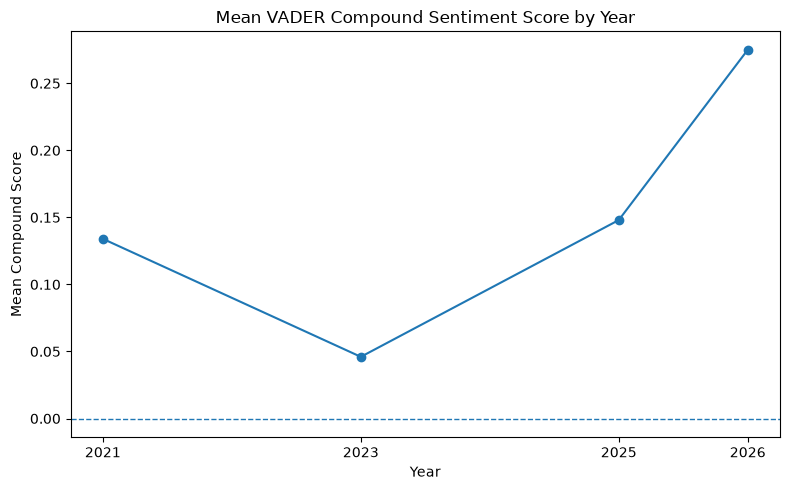

In [201]:
# Plot mean VADER compound sentiment by year

import matplotlib.pyplot as plt

plot_df = sentiment_summary.reset_index()

plt.figure(figsize=(8, 5))

plt.plot(
    plot_df["year"],
    plot_df["mean_compound"],
    marker="o"
)

plt.axhline(
    0,
    linestyle="--",
    linewidth=1
)

plt.title("Mean VADER Compound Sentiment Score by Year")
plt.xlabel("Year")
plt.ylabel("Mean Compound Score")
plt.xticks(plot_df["year"])

plt.tight_layout()
plt.show()

In [195]:
# Examine the distribution of VADER compound scores by year

compound_summary = (
    scoring_df
    .groupby("year")["vader_compound"]
    .agg(
        count="count",
        minimum="min",
        q1=lambda x: x.quantile(0.25),
        median="median",
        q3=lambda x: x.quantile(0.75),
        maximum="max",
        mean="mean"
    )
    .round(3)
)

display(compound_summary)

,count,minimum,q1,median,q3,maximum,mean
year,,,,,,,
2021,14,-0.795,0.000,0.102,0.295,0.786,0.134
2023,20,-0.665,-0.278,0.000,0.177,0.953,0.046
2025,11,-0.966,-0.164,0.273,0.504,0.987,0.148
2026,14,-0.879,-0.330,0.461,0.867,0.964,0.275


In [196]:
# Inspect the most extreme VADER sentiment posts by year

extreme_posts = (
    scoring_df[
        [
            "year",
            "title",
            "sentiment_text",
            "vader_compound",
            "vader_sentiment"
        ]
    ]
    .sort_values(["year", "vader_compound"])
)

for year in sorted(extreme_posts["year"].unique()):
    year_posts = extreme_posts[extreme_posts["year"] == year]

    print(f"\n{'=' * 70}")
    print(f"{year} — MOST NEGATIVE")
    print(f"{'=' * 70}")

    display(year_posts.head(2))

    print(f"\n{year} — MOST POSITIVE")
    print(f"{'=' * 70}")

    display(year_posts.tail(2))


2021 — MOST NEGATIVE


,year,title,sentiment_text,vader_compound,vader_sentiment
55,2021,Got role model on my eval!,Didn’t think it was even possible or feasible ...,-0.7953,negative
60,2021,When you finally get a fair and justified eval,Finally got that elusive exceeds expectations ...,-0.1779,negative



2021 — MOST POSITIVE


,year,title,sentiment_text,vader_compound,vader_sentiment
51,2021,August Special Pay Review,So I just read another post that explained the...,0.6641,positive
62,2021,Good management makes a difference,I’ve been a CSTL for over a year and a half. G...,0.7865,positive



2023 — MOST NEGATIVE


...

,year,title,sentiment_text,vader_compound,vader_sentiment
23,2025,I'm a ROLE MODEL!!!,"My manager just gave me my evaluation, and she...",0.5792,positive
22,2025,Performance evals (again) and college questions,"Hello again, fellow associates. I just got my ...",0.9871,positive



2026 — MOST NEGATIVE


,year,title,sentiment_text,vader_compound,vader_sentiment
8,2026,Evaluation comments,Does anyone know who or when the comments of y...,-0.8790,negative
16,2026,Evals,"Sorry if this has already been asked, but is c...",-0.6007,negative



2026 — MOST POSITIVE


,year,title,sentiment_text,vader_compound,vader_sentiment
17,2026,Eval,I've gotten RM for the second time in 2 years!...,0.9621,positive
15,2026,the hard truth,i’ve been seeing a lot of complaints from my f...,0.9639,positive


In [197]:
# Calculate longitudinal changes in mean VADER sentiment

mean_sentiment = sentiment_summary["mean_compound"].sort_index()

sentiment_change = pd.DataFrame({
    "from_year": mean_sentiment.index[:-1],
    "to_year": mean_sentiment.index[1:],
    "mean_sentiment_from": mean_sentiment.values[:-1],
    "mean_sentiment_to": mean_sentiment.values[1:]
})

sentiment_change["change"] = (
    sentiment_change["mean_sentiment_to"]
    - sentiment_change["mean_sentiment_from"]
)

overall_change = mean_sentiment.iloc[-1] - mean_sentiment.iloc[0]

display(sentiment_change.round(3))

print(f"\nOverall change in mean compound sentiment:")
print(f"2021 → 2026: {overall_change:.3f}")

,from_year,to_year,mean_sentiment_from,mean_sentiment_to,change
0,2021,2023,0.134,0.046,-0.088
1,2023,2025,0.046,0.148,0.102
2,2025,2026,0.148,0.275,0.127



Overall change in mean compound sentiment:
2021 → 2026: 0.141


In [198]:
# Calculate change in sentiment category proportions
# from the first study year to the most recent study year

category_change = pd.DataFrame({
    "2021_pct": [
        sentiment_summary.loc[2021, "negative_pct"],
        sentiment_summary.loc[2021, "neutral_pct"],
        sentiment_summary.loc[2021, "positive_pct"]
    ],
    "2026_pct": [
        sentiment_summary.loc[2026, "negative_pct"],
        sentiment_summary.loc[2026, "neutral_pct"],
        sentiment_summary.loc[2026, "positive_pct"]
    ]
}, index=["negative", "neutral", "positive"])

category_change["change_percentage_points"] = (
    category_change["2026_pct"] - category_change["2021_pct"]
)

display(category_change.round(3))

,2021_pct,2026_pct,change_percentage_points
negative,21.429,28.571,7.142
neutral,21.429,7.143,-14.286
positive,57.143,64.286,7.143


In [199]:
# Calculate 95% confidence intervals for mean VADER compound scores

import numpy as np
from scipy import stats

confidence_summary = []

for year, group in scoring_df.groupby("year"):
    scores = group["vader_compound"].dropna()
    n = len(scores)
    mean = scores.mean()
    standard_error = stats.sem(scores)

    confidence_interval = stats.t.interval(
        confidence=0.95,
        df=n - 1,
        loc=mean,
        scale=standard_error
    )

    confidence_summary.append({
        "year": year,
        "n": n,
        "mean_compound": mean,
        "ci_lower": confidence_interval[0],
        "ci_upper": confidence_interval[1]
    })

confidence_summary = pd.DataFrame(confidence_summary)
confidence_summary = confidence_summary.round(3)

display(confidence_summary)

,year,n,mean_compound,ci_lower,ci_upper
0,2021,14,0.134,-0.092,0.360
1,2023,20,0.046,-0.171,0.262
2,2025,11,0.148,-0.222,0.517
3,2026,14,0.275,-0.099,0.650


## Phase 1 Results

The Phase 1 analysis examined sentiment expressed directly in 60 Reddit parent posts with available text across four study years: 2021, 2023, 2025, and 2026. Four additional 2026 records were excluded from sentiment scoring because the posts had been deleted and therefore contained no usable text. The validated parent-post dataset itself was preserved unchanged.

The distribution of sentiment varied across the study period. In 2021, 60.0% of posts were classified as positive, 20.0% as neutral, and 20.0% as negative. Sentiment was most mixed in 2023, when 35.0% of posts were classified as negative, 35.0% as neutral, and 30.0% as positive. The distribution became more positive in 2025, with 54.5% positive, 18.2% neutral, and 27.3% negative posts. In 2026, 64.3% of posts were classified as positive, 7.1% as neutral, and 28.6% as negative.

The mean VADER compound score followed a similar pattern. The mean declined from 0.164 in 2021 to 0.046 in 2023 before increasing to 0.148 in 2025 and 0.275 in 2026. The median compound score also increased from 0.128 in 2021 to 0.461 in 2026. Overall, the mean compound score increased by 0.111 points between 2021 and 2026.

These results do not indicate a consistent worsening of sentiment toward Publix evaluations over the study period. Instead, the data show a decline in sentiment through 2023 followed by a recovery in 2025 and 2026. However, the change is not uniformly positive: the proportion of negative posts increased from 20.0% in 2021 to 28.6% in 2026, while the proportion of neutral posts decreased from 20.0% to 7.1%. This suggests that the later sample may contain less neutral discussion rather than simply becoming more positive.

The 95% confidence intervals around the yearly mean compound scores were wide and included zero for all four study years. Given the small and uneven sample sizes, these results should therefore be interpreted as descriptive patterns within the collected Reddit sample rather than as statistically significant evidence of a population-wide change in sentiment.

Overall, Phase 1 does not support the hypothesis that sentiment toward Publix employee evaluations is becoming progressively worse over time. The strongest negative period in the sample was 2023, while 2026 had the highest mean and median sentiment scores and the largest proportion of positive posts.